In [1]:
import sys
import os
import re
from collections import defaultdict
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils

In [2]:
import importlib
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py'>

In [3]:
api = wandb.Api()
username = 'julian-zim-uni-vie'
project_names = [project.name for project in api.projects(entity=username)]

In [4]:
projects = {
	'll00': {
		'bom_ns' : list(),
		'hgm_ns' : list(),
		'bom_ss' : list(),
		'hgm_ss' : list(),
	},
}

for name in project_names:
	if name.startswith('worm '):
		model, ll = name.split(' ')[1].split('-')[0:2]
		projects[ll][model].append(name)

In [5]:
hyperparams = {
	ll: {
		model : {
			'means': {
				**(
					{'vb_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.endswith('ss') else
					{'wb_reg_lambda': {
							'linear': -1.,
							'geometric': -1.,
					}}
				),
				**(
					{'wm_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.startswith('hgm') else {}
				),
			},
			'datasets': {
				dataset: {
					'mpe_loss': {
						'all': np.empty(shape=()),
					},
					**(
						{'vb_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.endswith('ss') else
						{'wb_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}}
					),
					**(
						{'wm_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.startswith('hgm') else {}
					),
				} for dataset in [' '.join(project.split(' ')[-2:]) for project in projects[ll][model]]
			},
		} for model in projects[ll].keys()
	} for ll in projects.keys()
}

In [6]:
percentile = 1
all = True

for ll in hyperparams.keys():
	for model in hyperparams[ll].keys():
		for dataset in hyperparams[ll][model]['datasets']:
			project = [name for name in projects[ll][model] if name.endswith(dataset)][0]

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')
			mpe_losses = np.array([run.summary.get('mpe_loss', float('inf')) for run in runs])

			print('sorting them...')
			mpe_losses, sorted_runs = zip(*sorted([(loss, run) for loss, run in zip(mpe_losses, runs) if loss != float('inf')], key=lambda x: x[0]))

			print(f'processing mpe losses...')
			hyperparams[ll][model]['datasets'][dataset]['mpe_loss']['all'] = mpe_losses if all else mpe_losses[:max(1, int(percentile / 100 * len(mpe_losses)))]

			if model.endswith('ss'):
				print(f'processing vb_reg_lambdas...')
				vb_reg_lambdas = np.array([run.config['vb_reg_lambda'] for run in sorted_runs])
				best_vb_reg_lambdas = vb_reg_lambdas[:max(1, int(percentile / 100 * len(vb_reg_lambdas)))]
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['all'] = vb_reg_lambdas if all else best_vb_reg_lambdas
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['linear'] = np.mean(best_vb_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_vb_reg_lambdas)))
			else:
				print(f'processing wb_reg_lambdas...')
				wb_reg_lambdas = np.array([run.config['wb_reg_lambda'] for run in sorted_runs])
				best_wb_reg_lambdas = wb_reg_lambdas[:max(1, int(percentile / 100 * len(wb_reg_lambdas)))]
				hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['all'] = wb_reg_lambdas if all else best_wb_reg_lambdas
				hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['linear'] = np.mean(best_wb_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wb_reg_lambdas)))

			if model.startswith('hgm'):
				print(f'processing wm_reg_lambdas...')
				wm_reg_lambdas = np.array([run.config['wm_reg_lambda'] for run in sorted_runs])
				best_wm_reg_lambdas = wm_reg_lambdas[:max(1, int(percentile / 100 * len(wm_reg_lambdas)))]
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['all'] = wm_reg_lambdas if all else best_wm_reg_lambdas
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['linear'] = np.mean(best_wm_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wm_reg_lambdas)))

		print('averaging across projects...')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			means_linear = np.array([
				hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean']['linear'] for dataset in hyperparams[ll][model]['datasets'].keys()
			])
			means_geometric = np.array([
				hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean']['geometric'] for dataset in hyperparams[ll][model]['datasets'].keys()
			])

			hyperparams[ll][model]['means'][hyperparam]['linear'] = np.mean(means_linear).item()
			# hyperparams[ll][model]['means'][hyperparam]['linear'] = np.max(means_linear).item()
			hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.mean(np.log10(means_geometric))).item()
			# hyperparams[ll][model]['means'][hyperparam]['geometric'] = np.power(10, np.max(np.log10(means_geometric))).item()

getting runs for WORM bom_ns-ll00 13.02 14h02 33 ZIM2165_Gcamp7b_worm9-2022-12-05...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for WORM bom_ns-ll00 13.02 13h23 32 ZIM2165_Gcamp7b_worm8-2022-12-10...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for WORM bom_ns-ll00 13.02 12h43 31 ZIM2165_Gcamp7b_worm7-2022-12-10...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for WORM bom_ns-ll00 13.02 12h04 30 ZIM2165_Gcamp7b_worm6-2022_11_28...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for WORM bom_ns-ll00 13.02 11h30 29 ZIM2165_Gcamp7b_worm6-2022-12-10...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for WORM bom_ns-ll00 13.02 10h50 28 ZIM2165_Gcamp7b_worm5-2022_11_28...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for WORM bom_ns-ll00 13.02 10h12 27 ZIM2165_Gcamp7b_worm4

In [7]:
for ll in hyperparams.keys():
	print(f'{ll}')
	for model in hyperparams[ll].keys():
		print(f'\t{model}')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			print(f'\t\t{hyperparam}')
			for mean_type in hyperparams[ll][model]['means'][hyperparam].keys():
				_mean = hyperparams[ll][model]['means'][hyperparam][mean_type]
				print(f'\t\t\t{mean_type}: \t{_mean}')

ll00
	bom_ns
		wb_reg_lambda
			linear: 	0.041379762143769594
			geometric: 	0.013452350928938815
	hgm_ns
		wb_reg_lambda
			linear: 	0.01568476336650376
			geometric: 	0.008794466847728473
		wm_reg_lambda
			linear: 	0.0289519907976937
			geometric: 	9.10793336527503e-06
	bom_ss
		vb_reg_lambda
			linear: 	0.043370919701192334
			geometric: 	0.029306734545954755
	hgm_ss
		vb_reg_lambda
			linear: 	0.015098851190082373
			geometric: 	0.009176484894278681
		wm_reg_lambda
			linear: 	0.05191855209145809
			geometric: 	2.2507708829018023e-05


In [7]:
# with open('../src/hyperparams.pkl', 'rb') as file:
#     hyperparams = pickle.load(file)

/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py:1216: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(len(hyperparams[ll].keys()), 2,


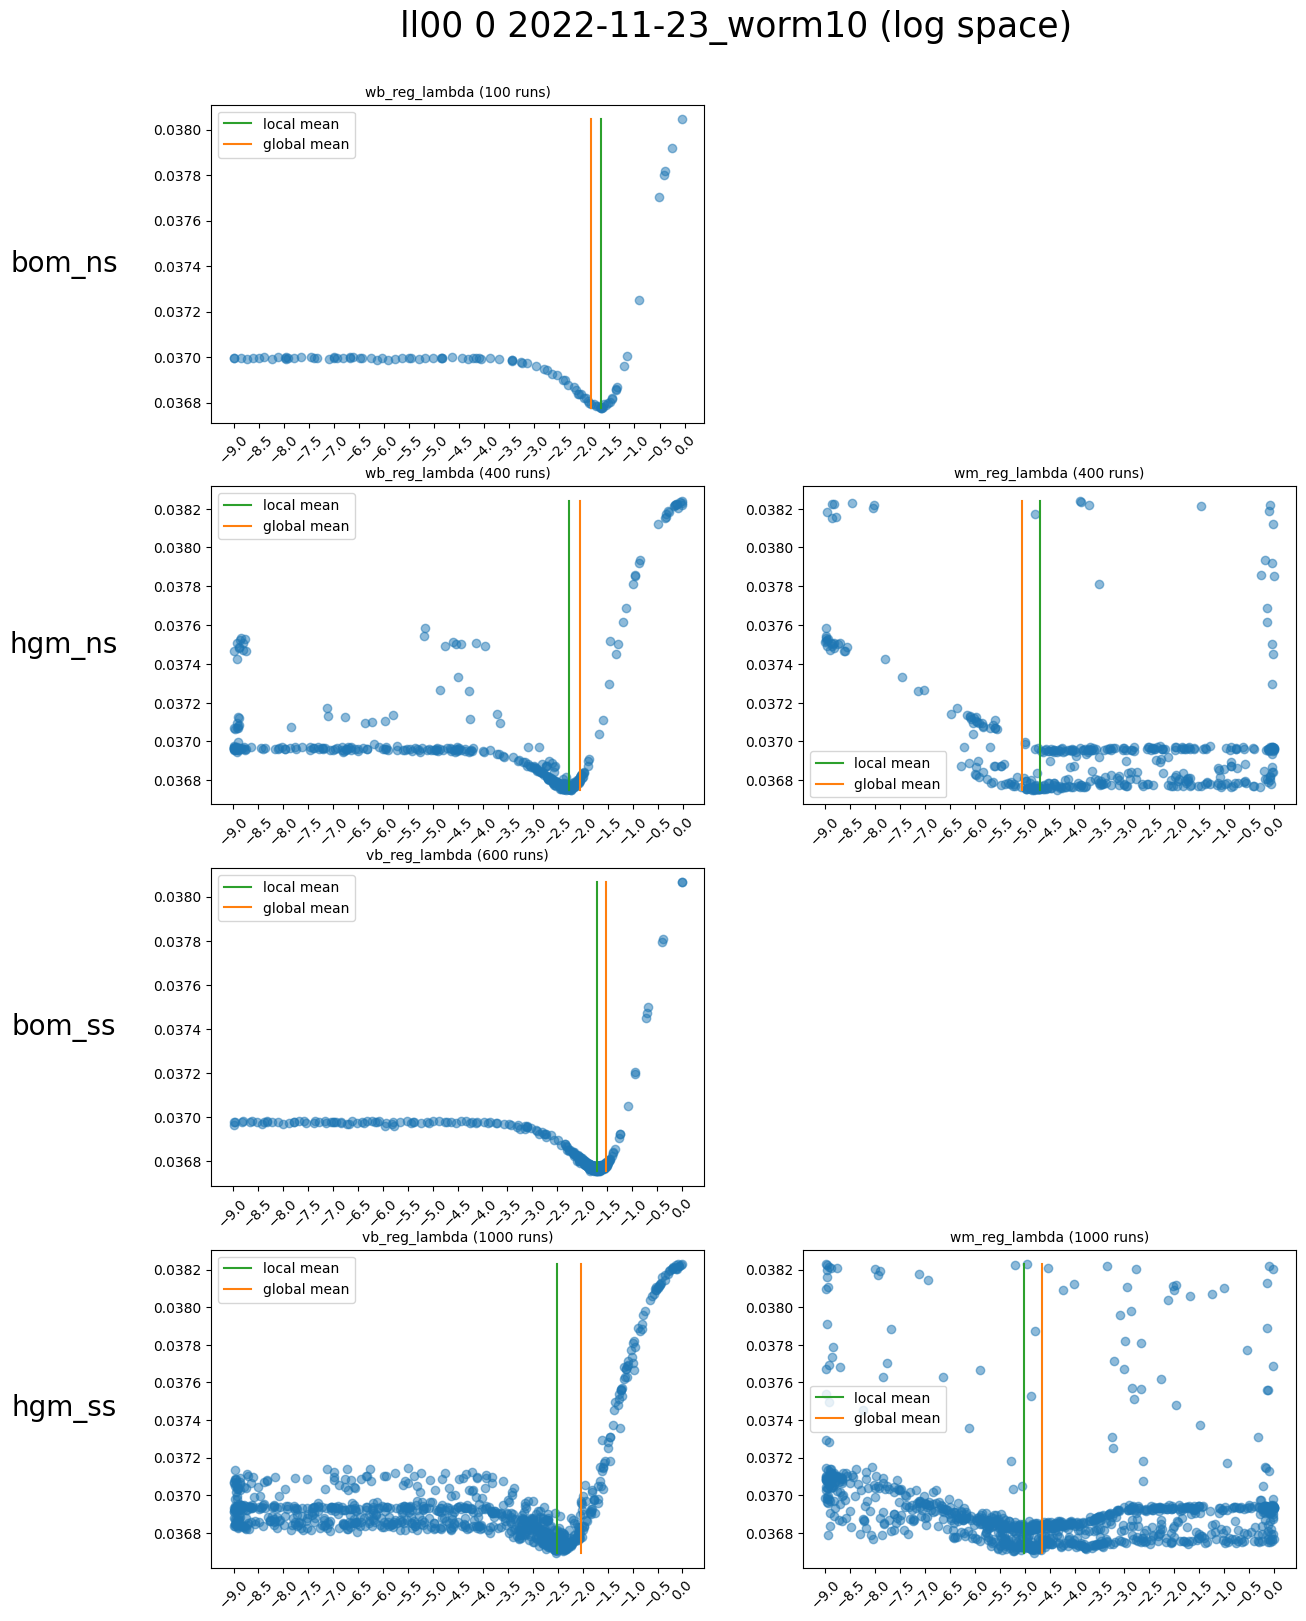

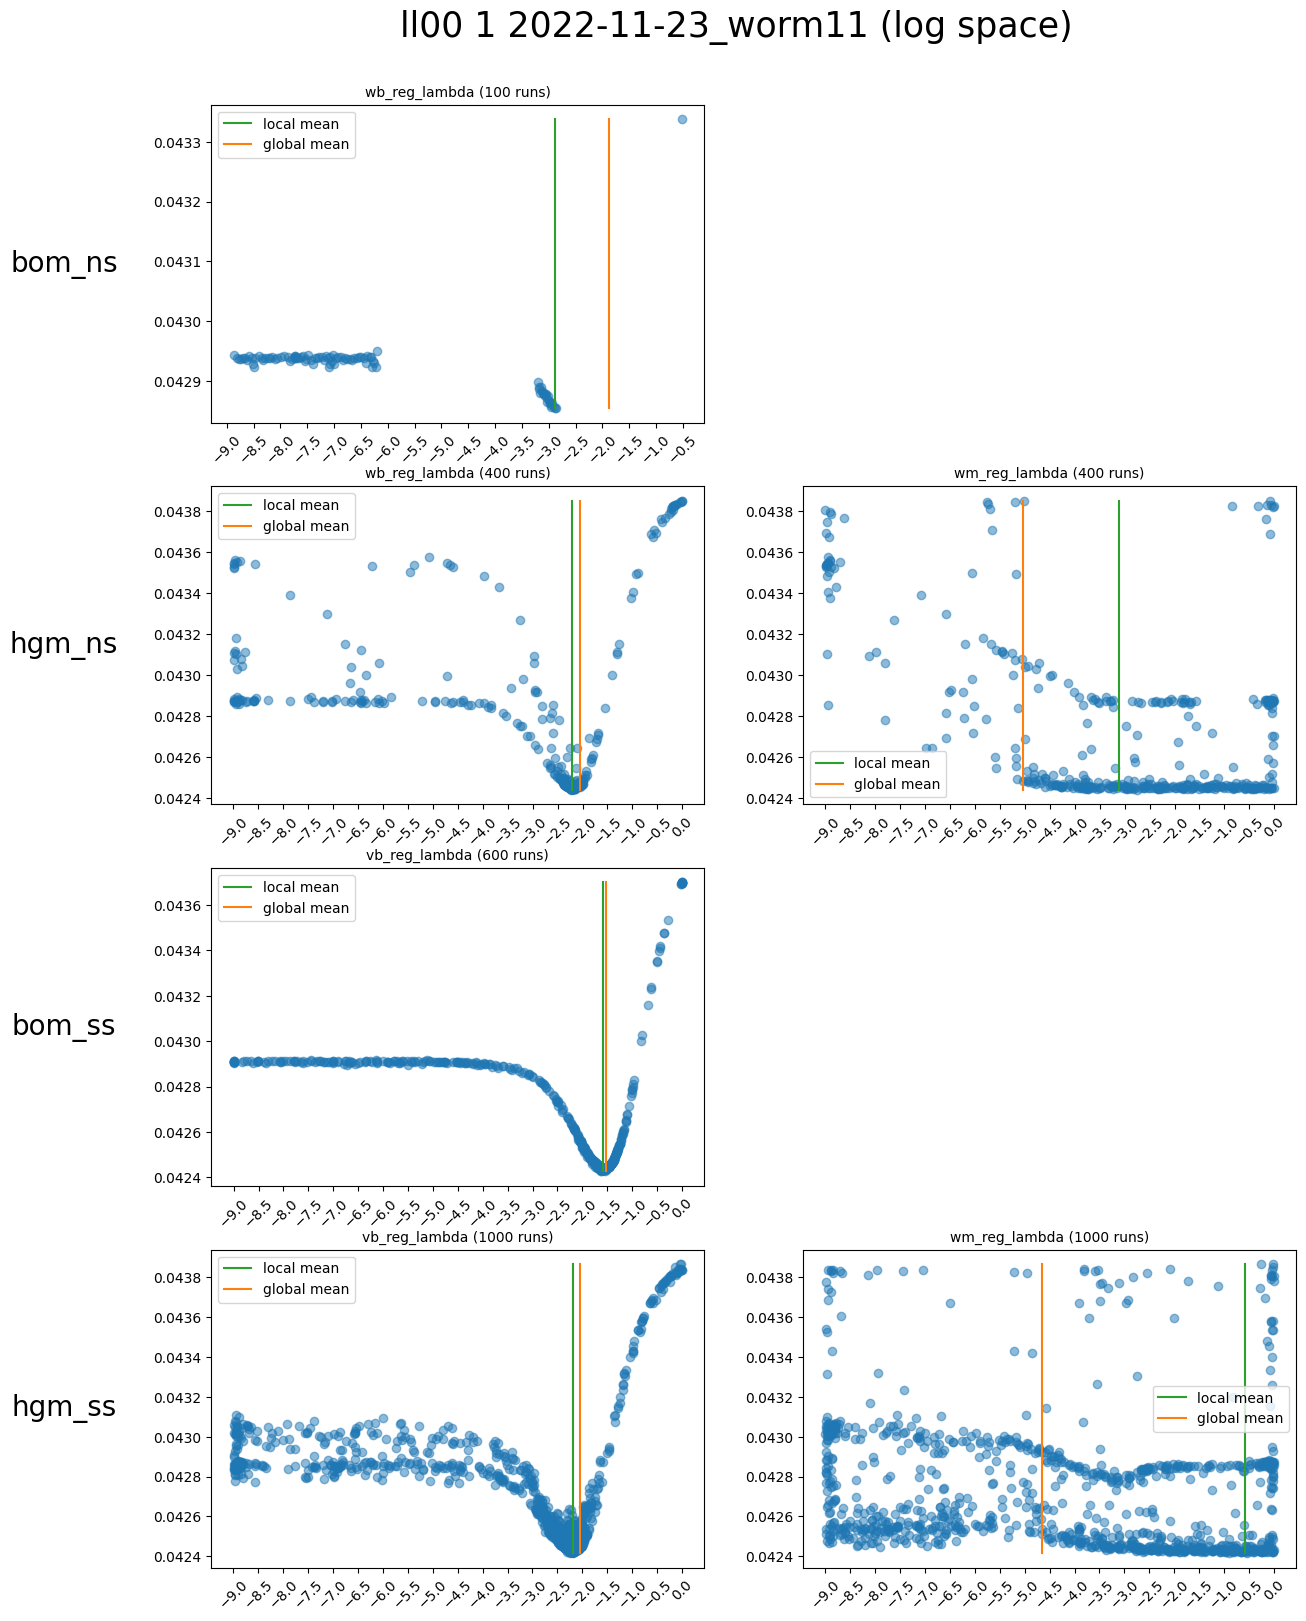

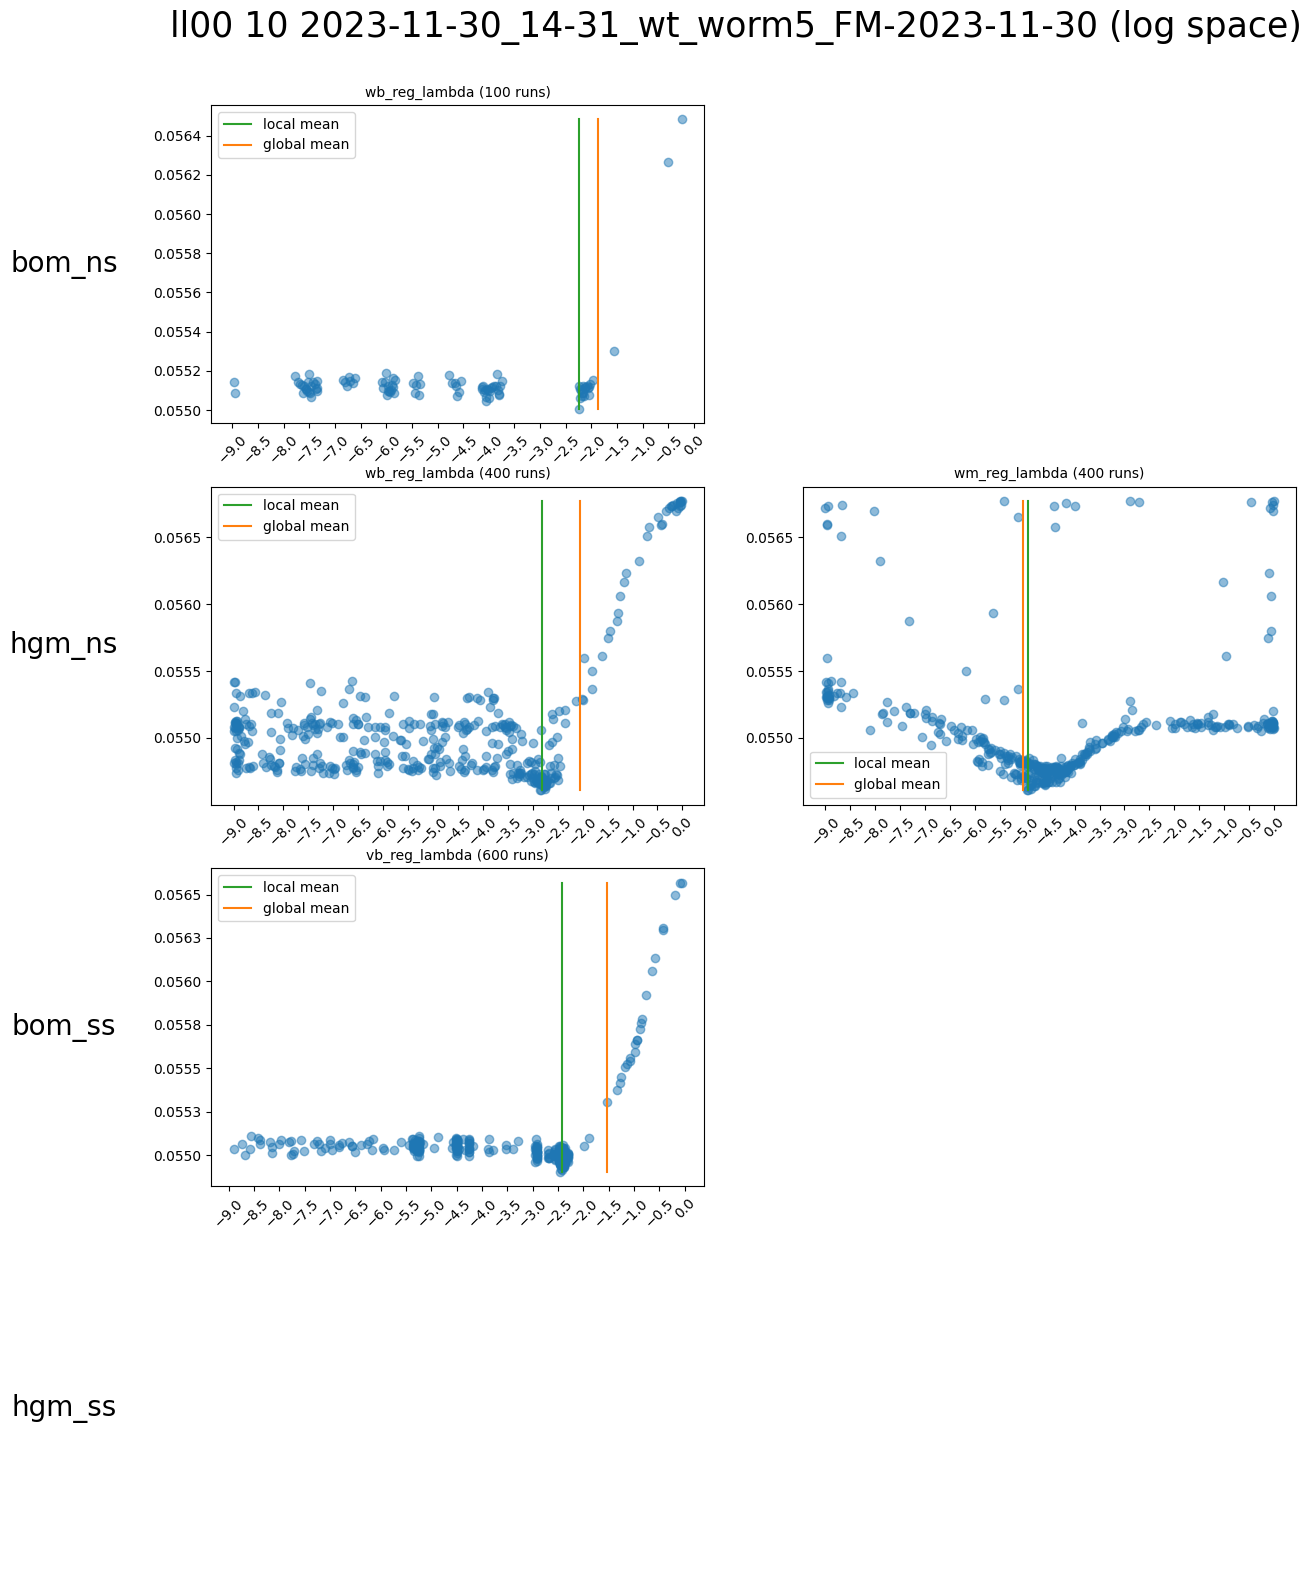

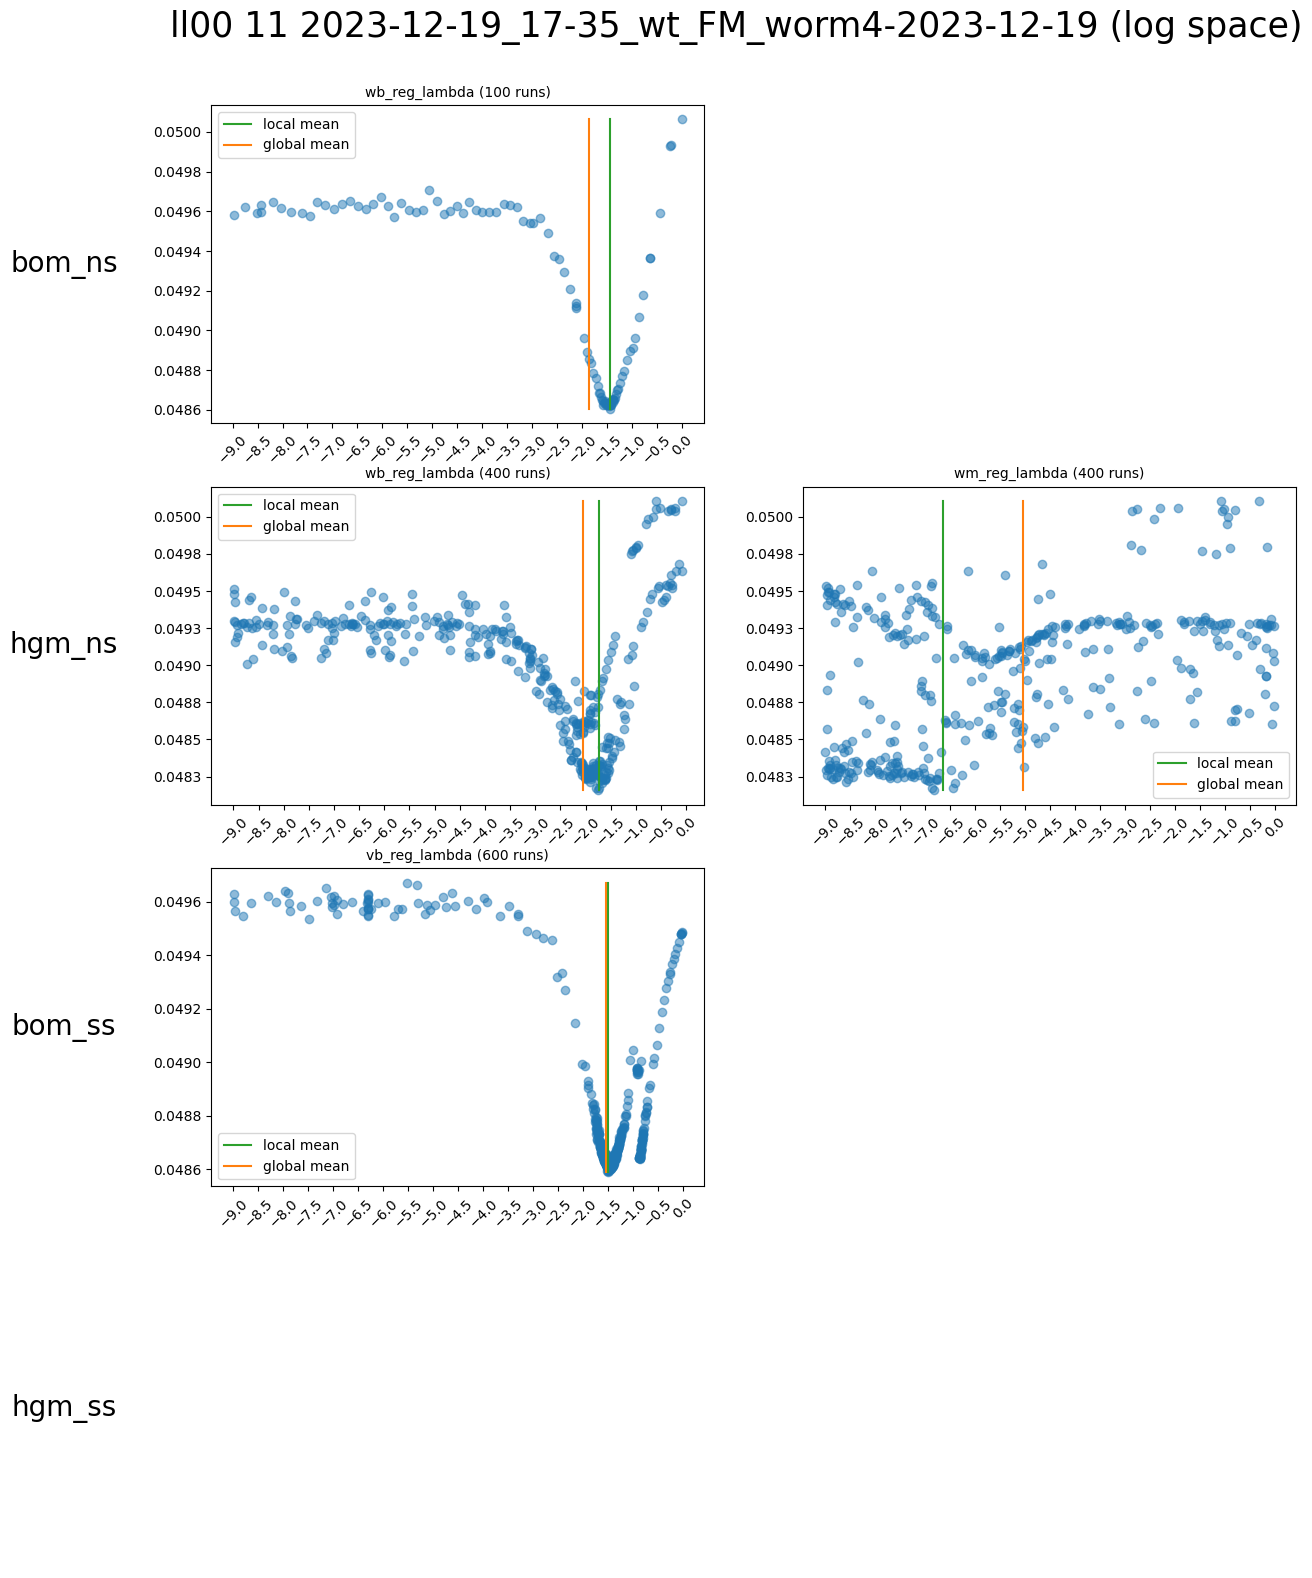

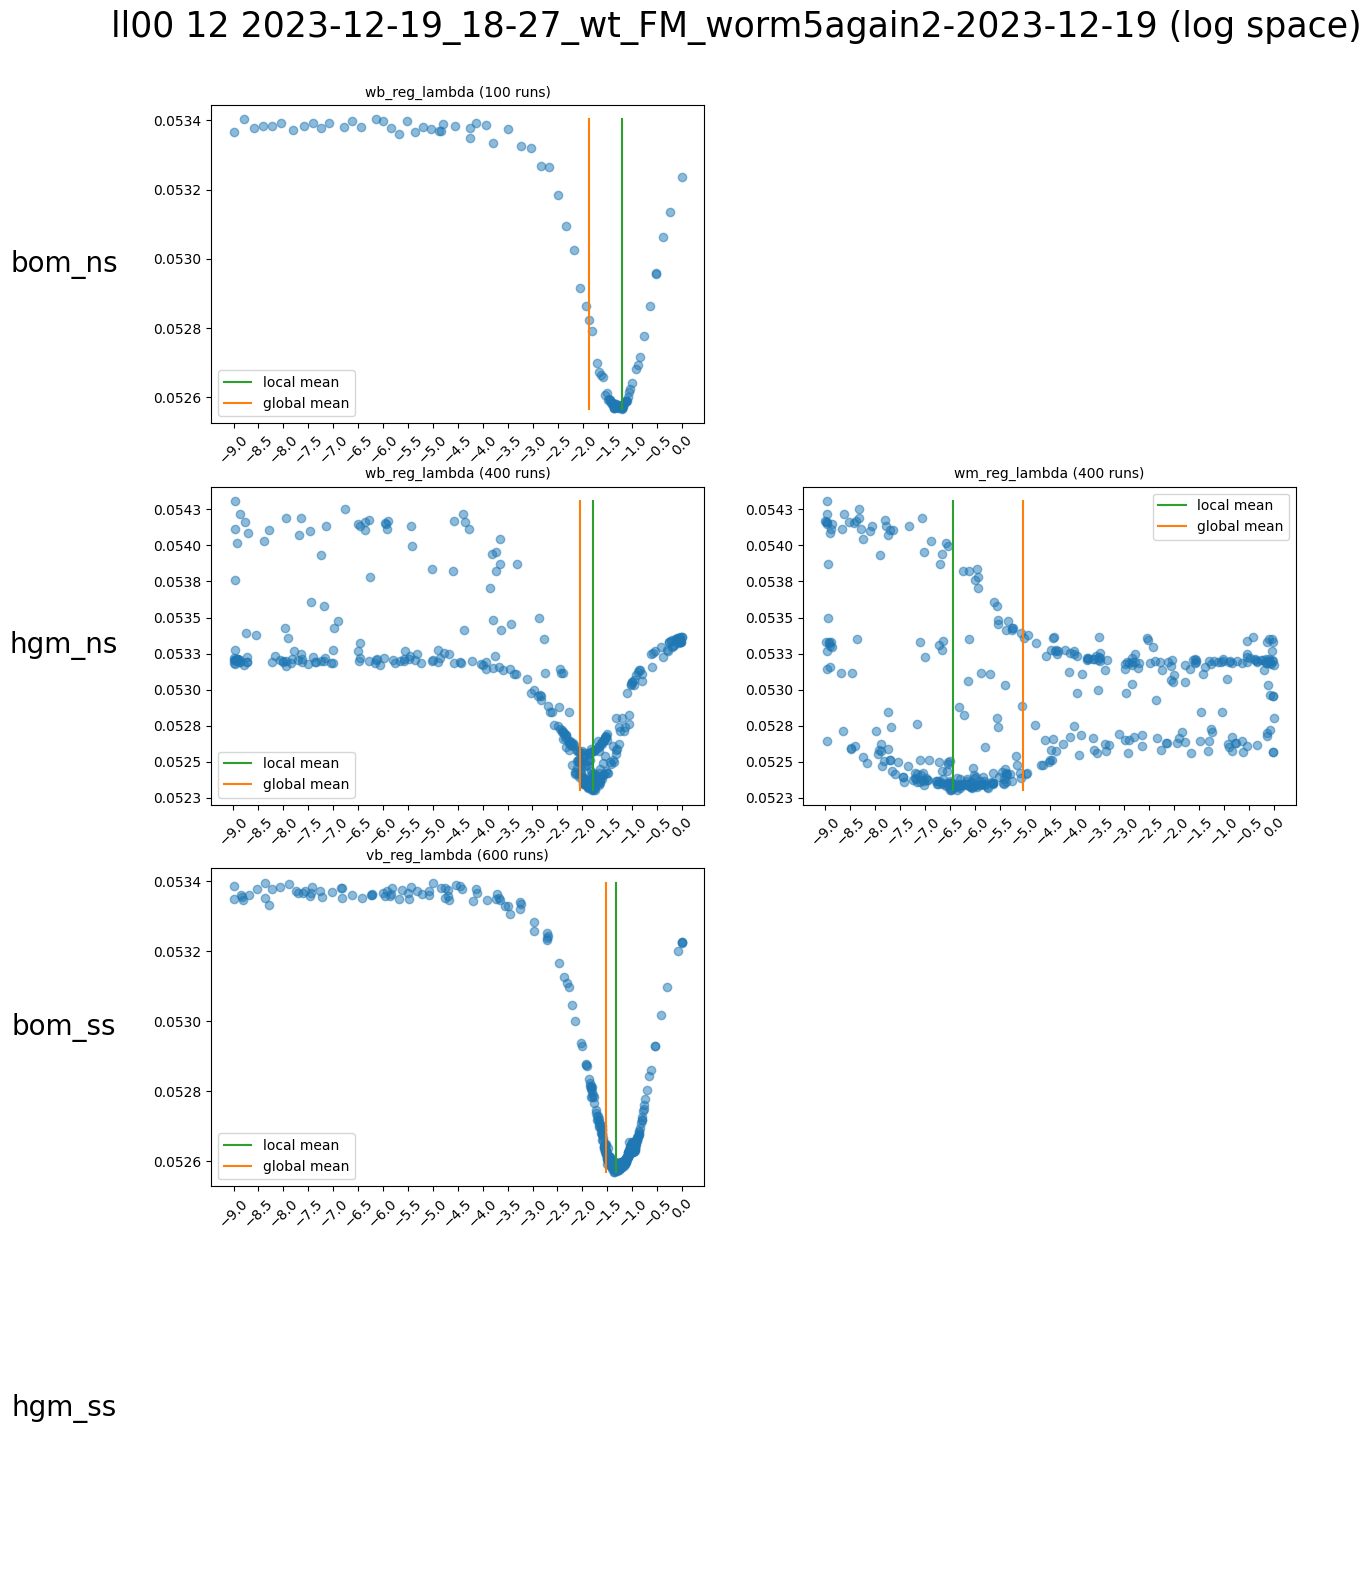

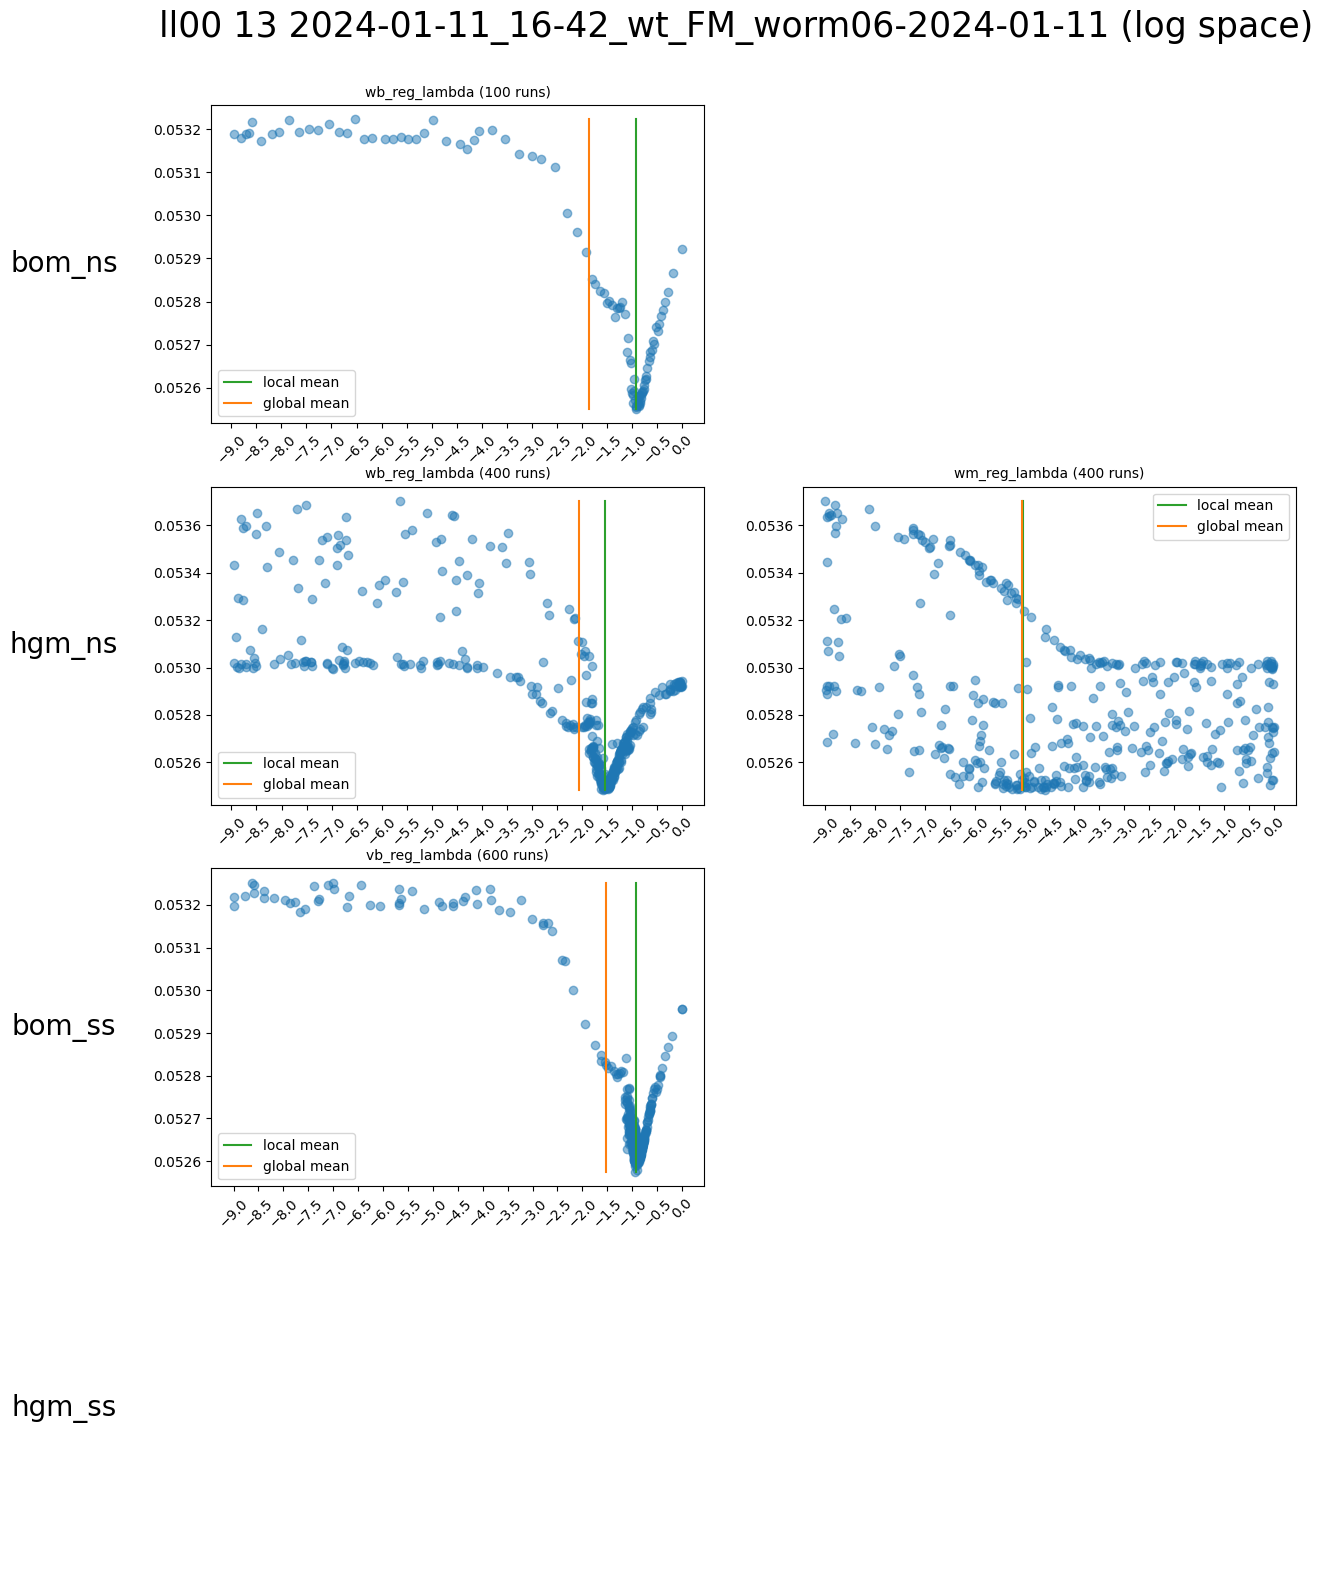

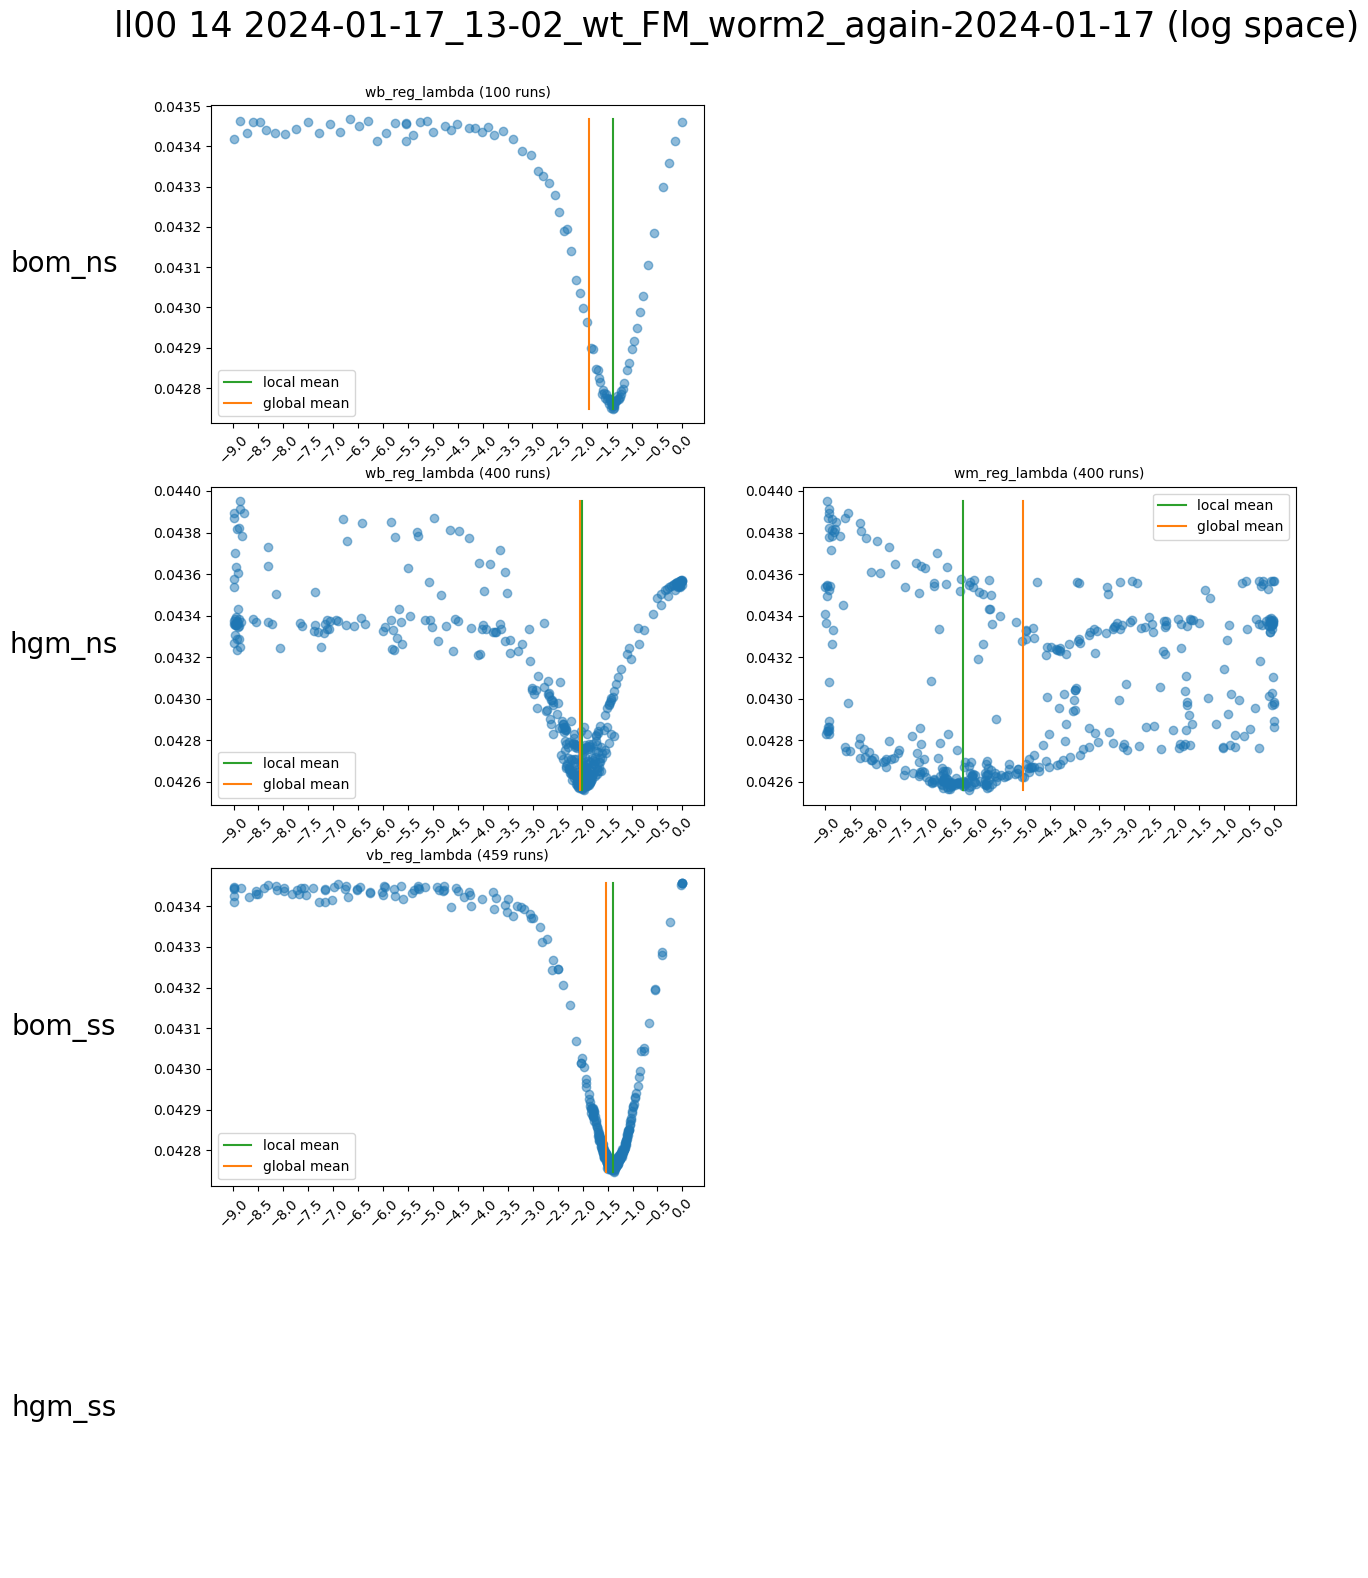

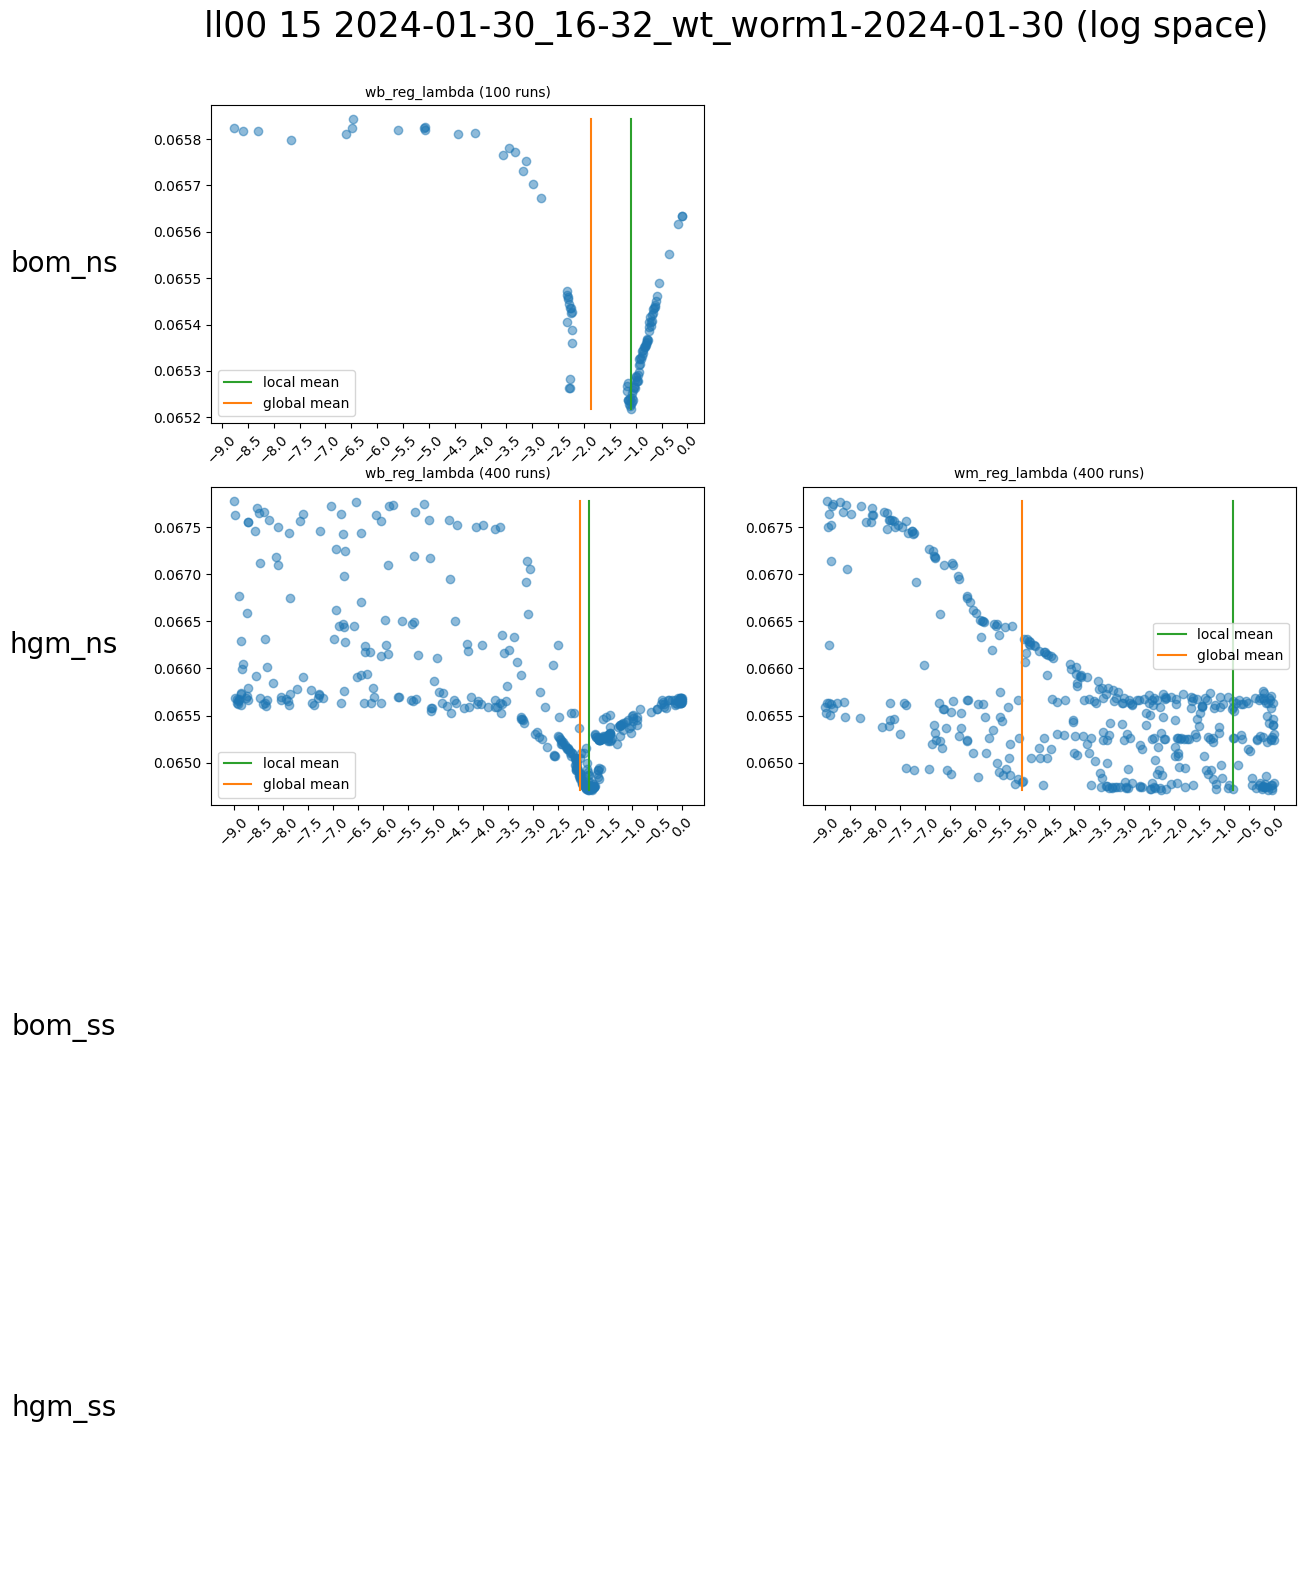

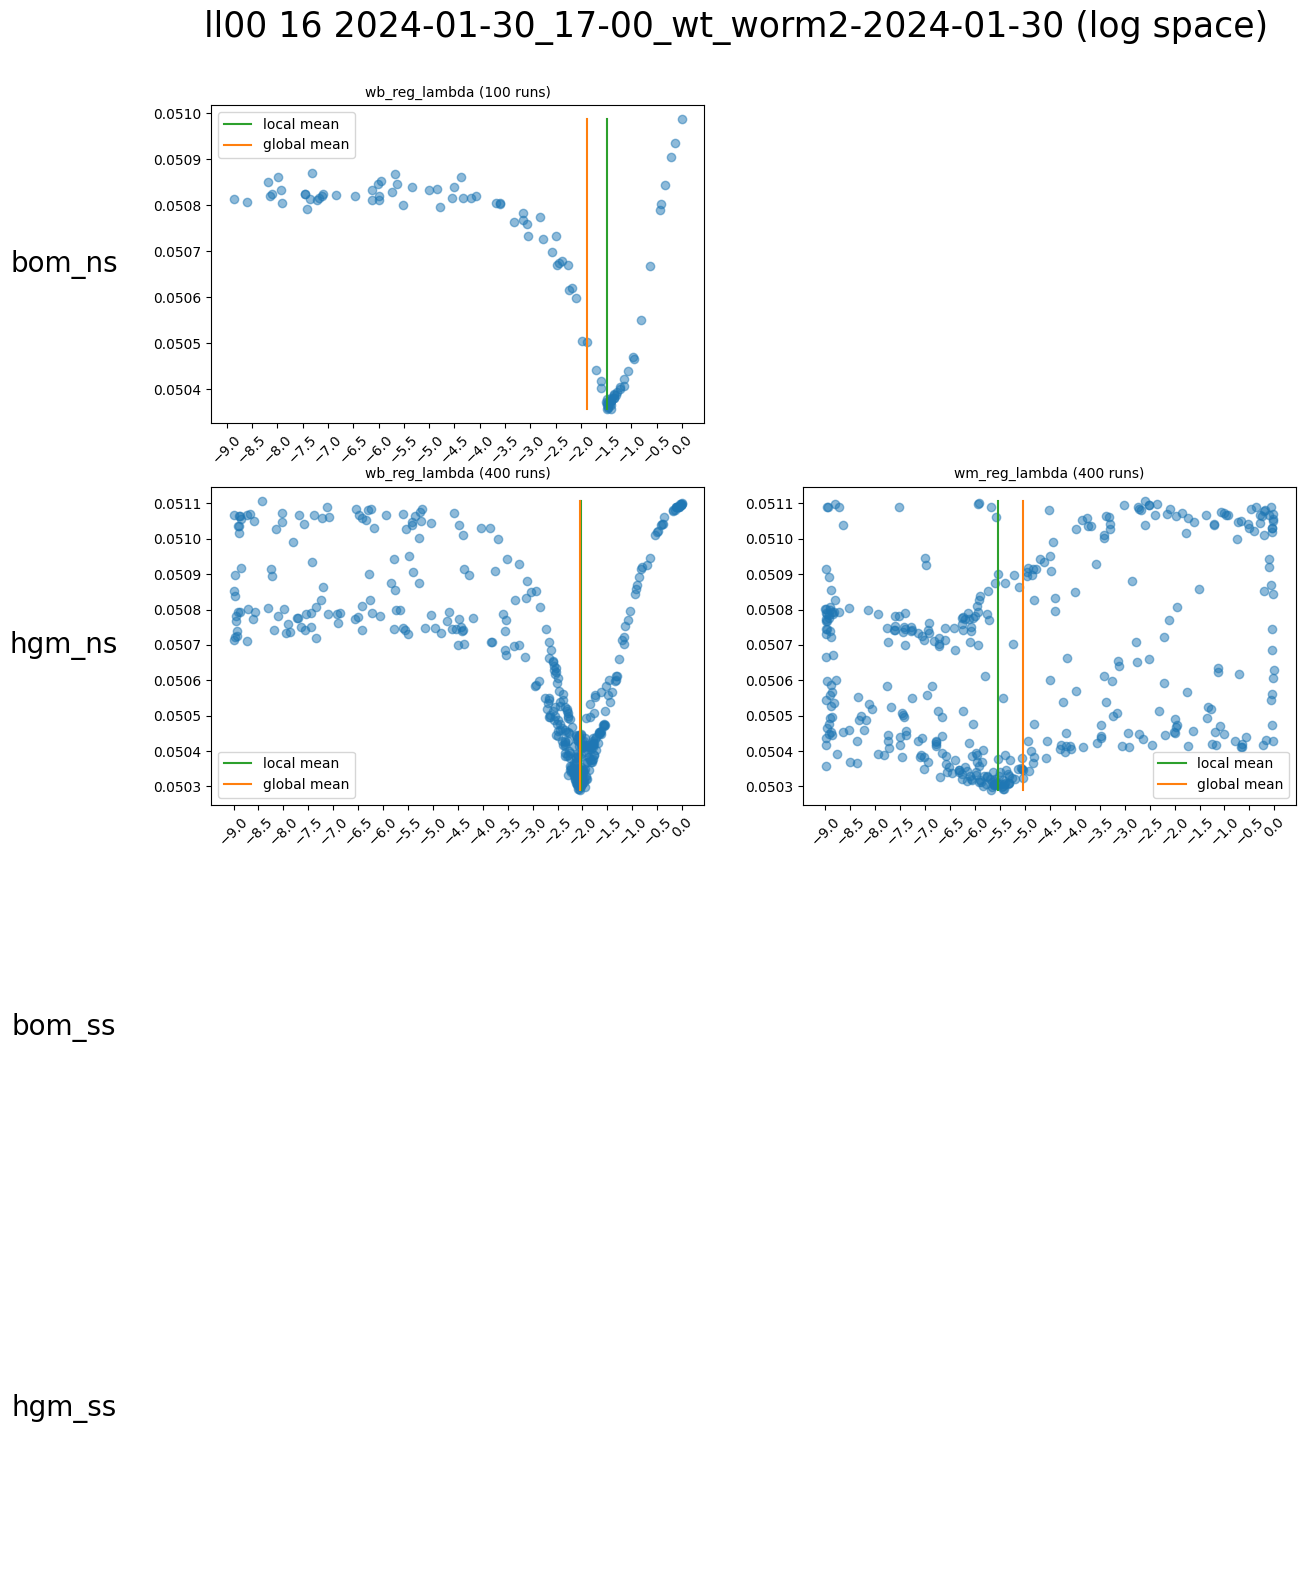

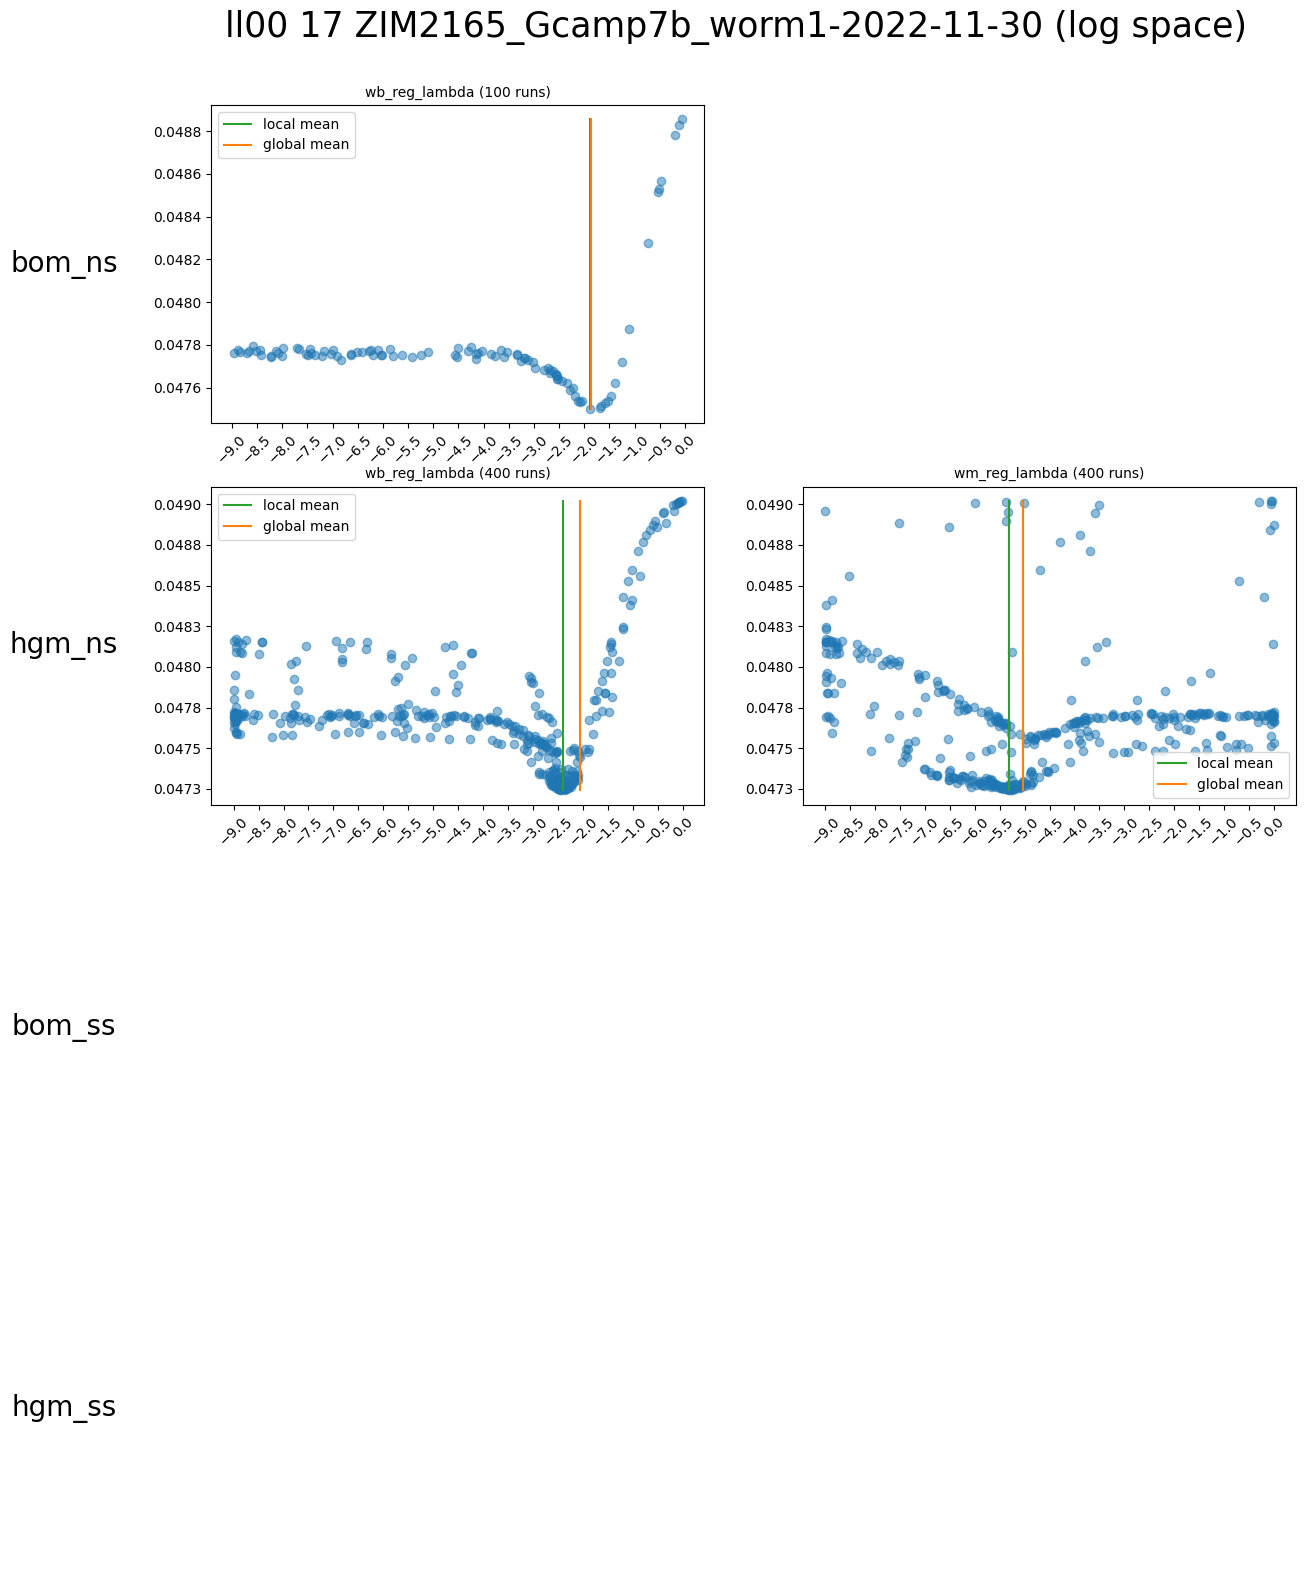

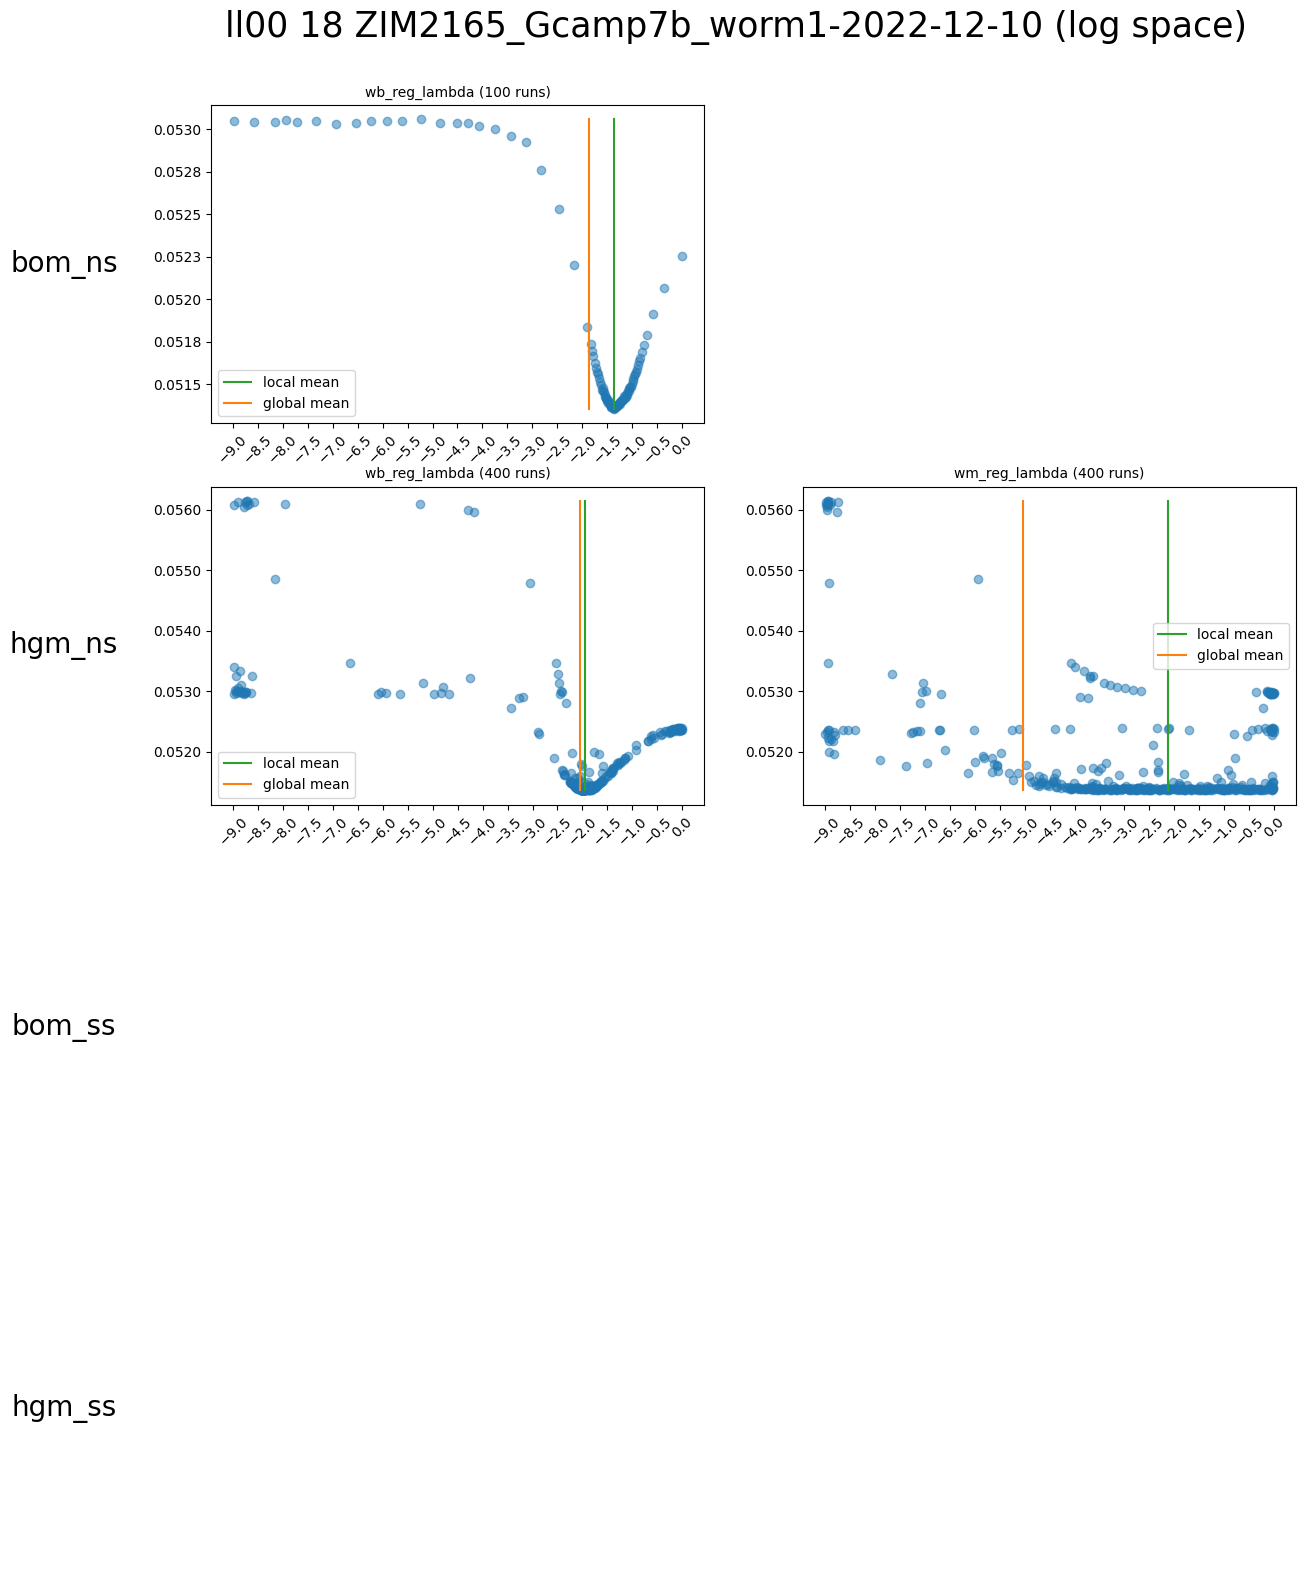

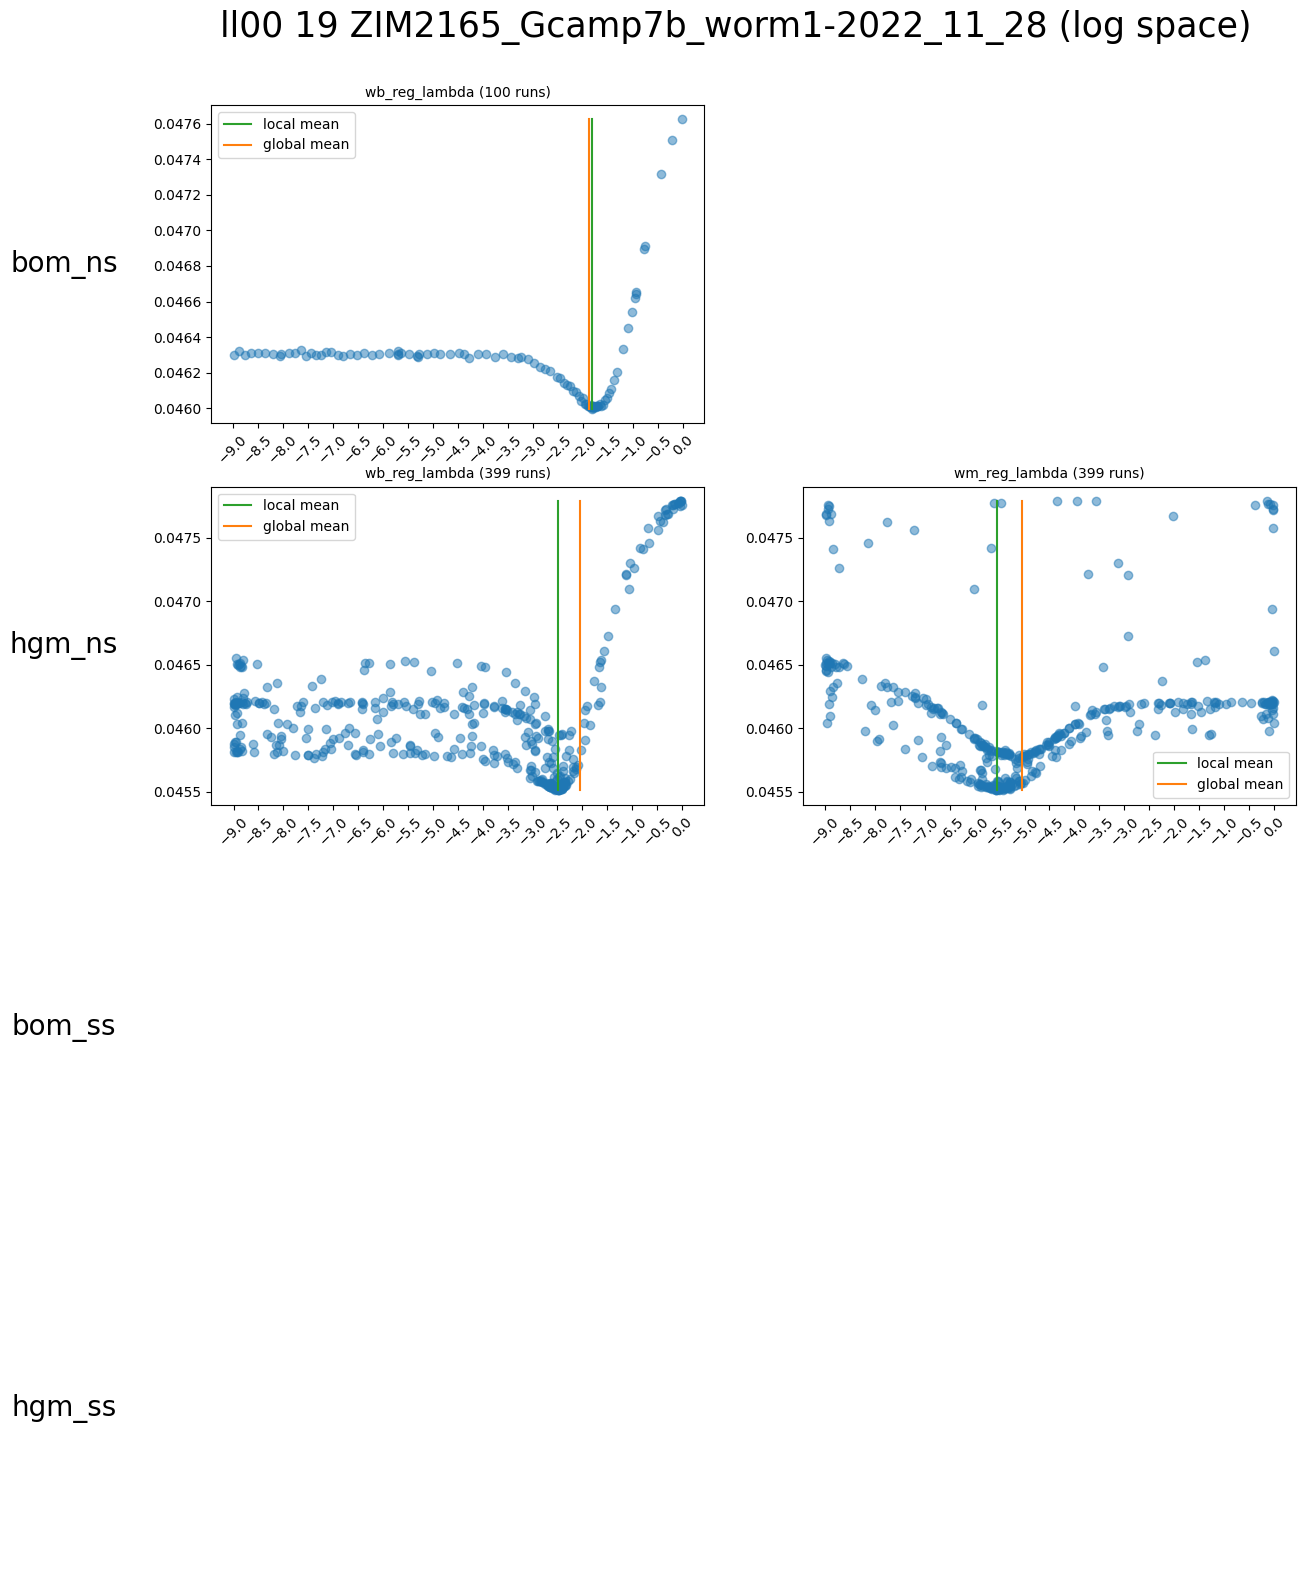

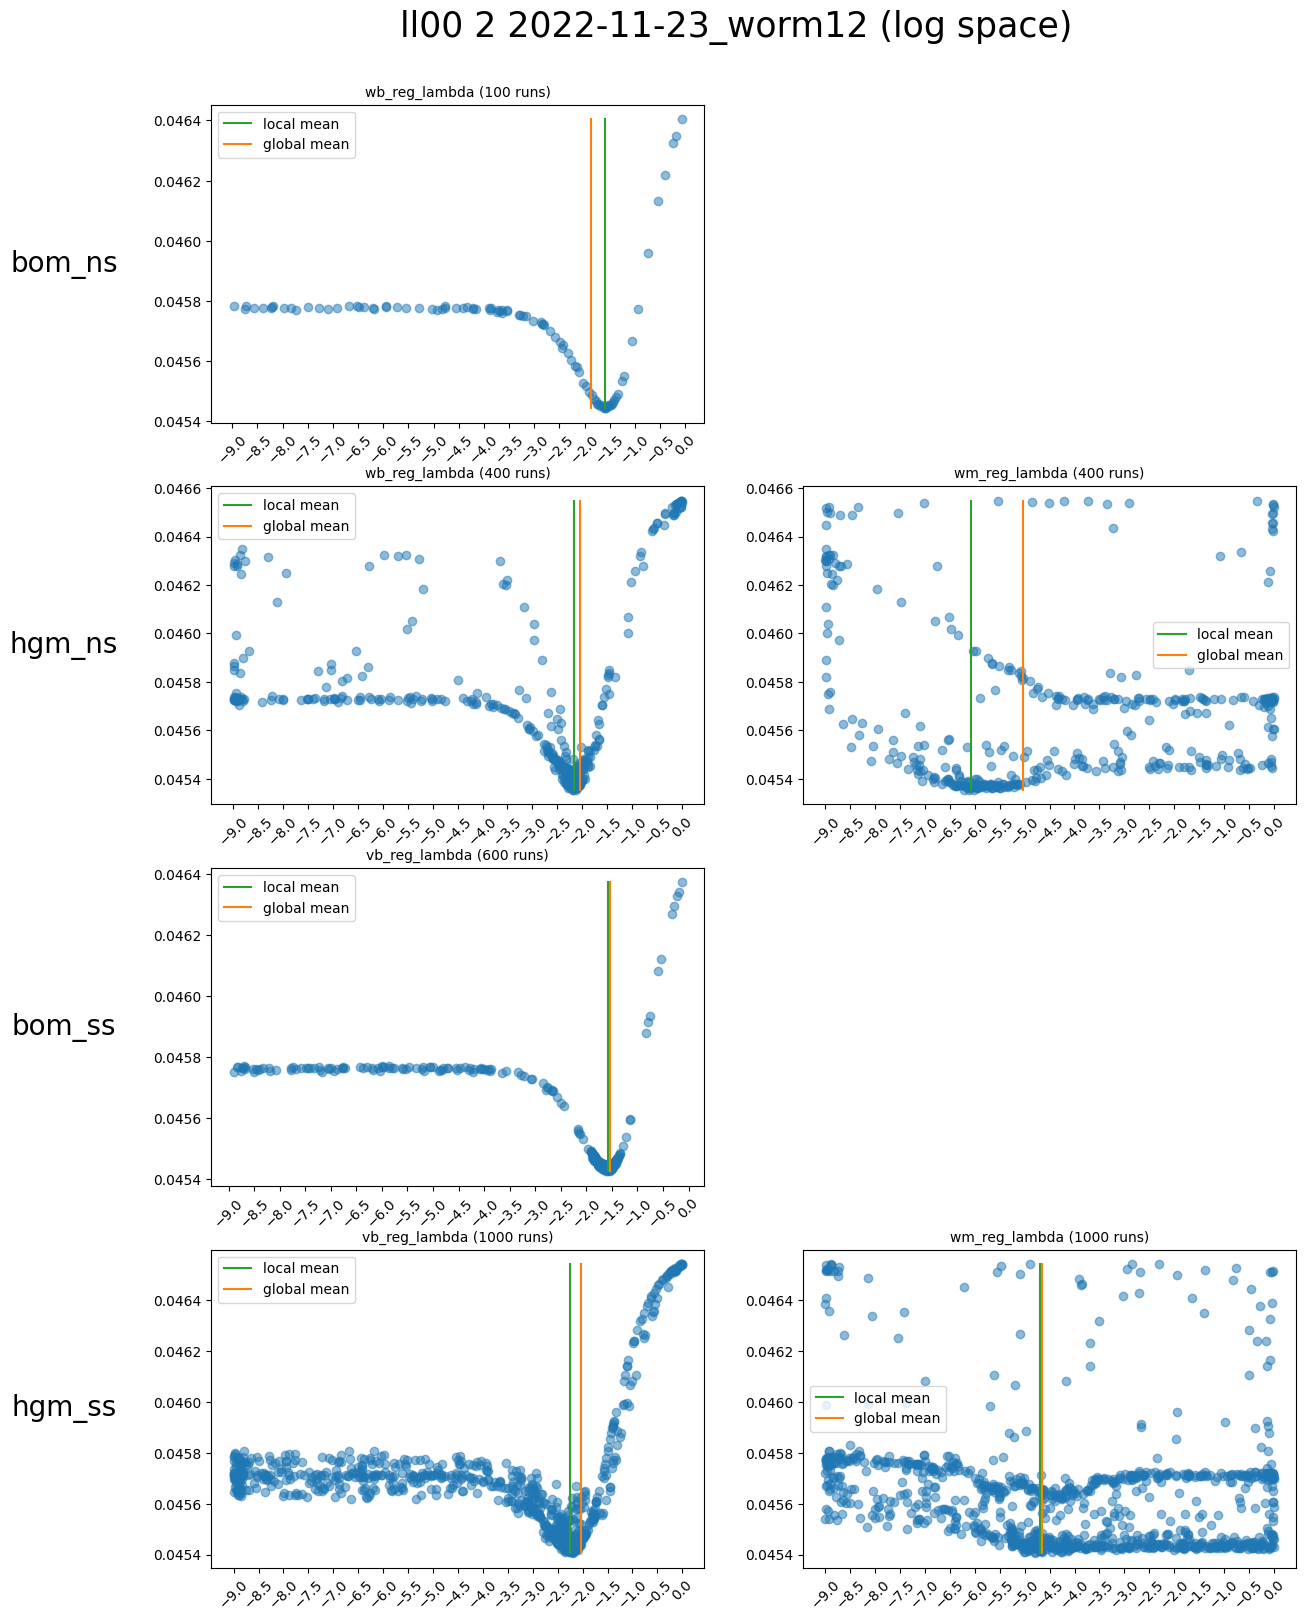

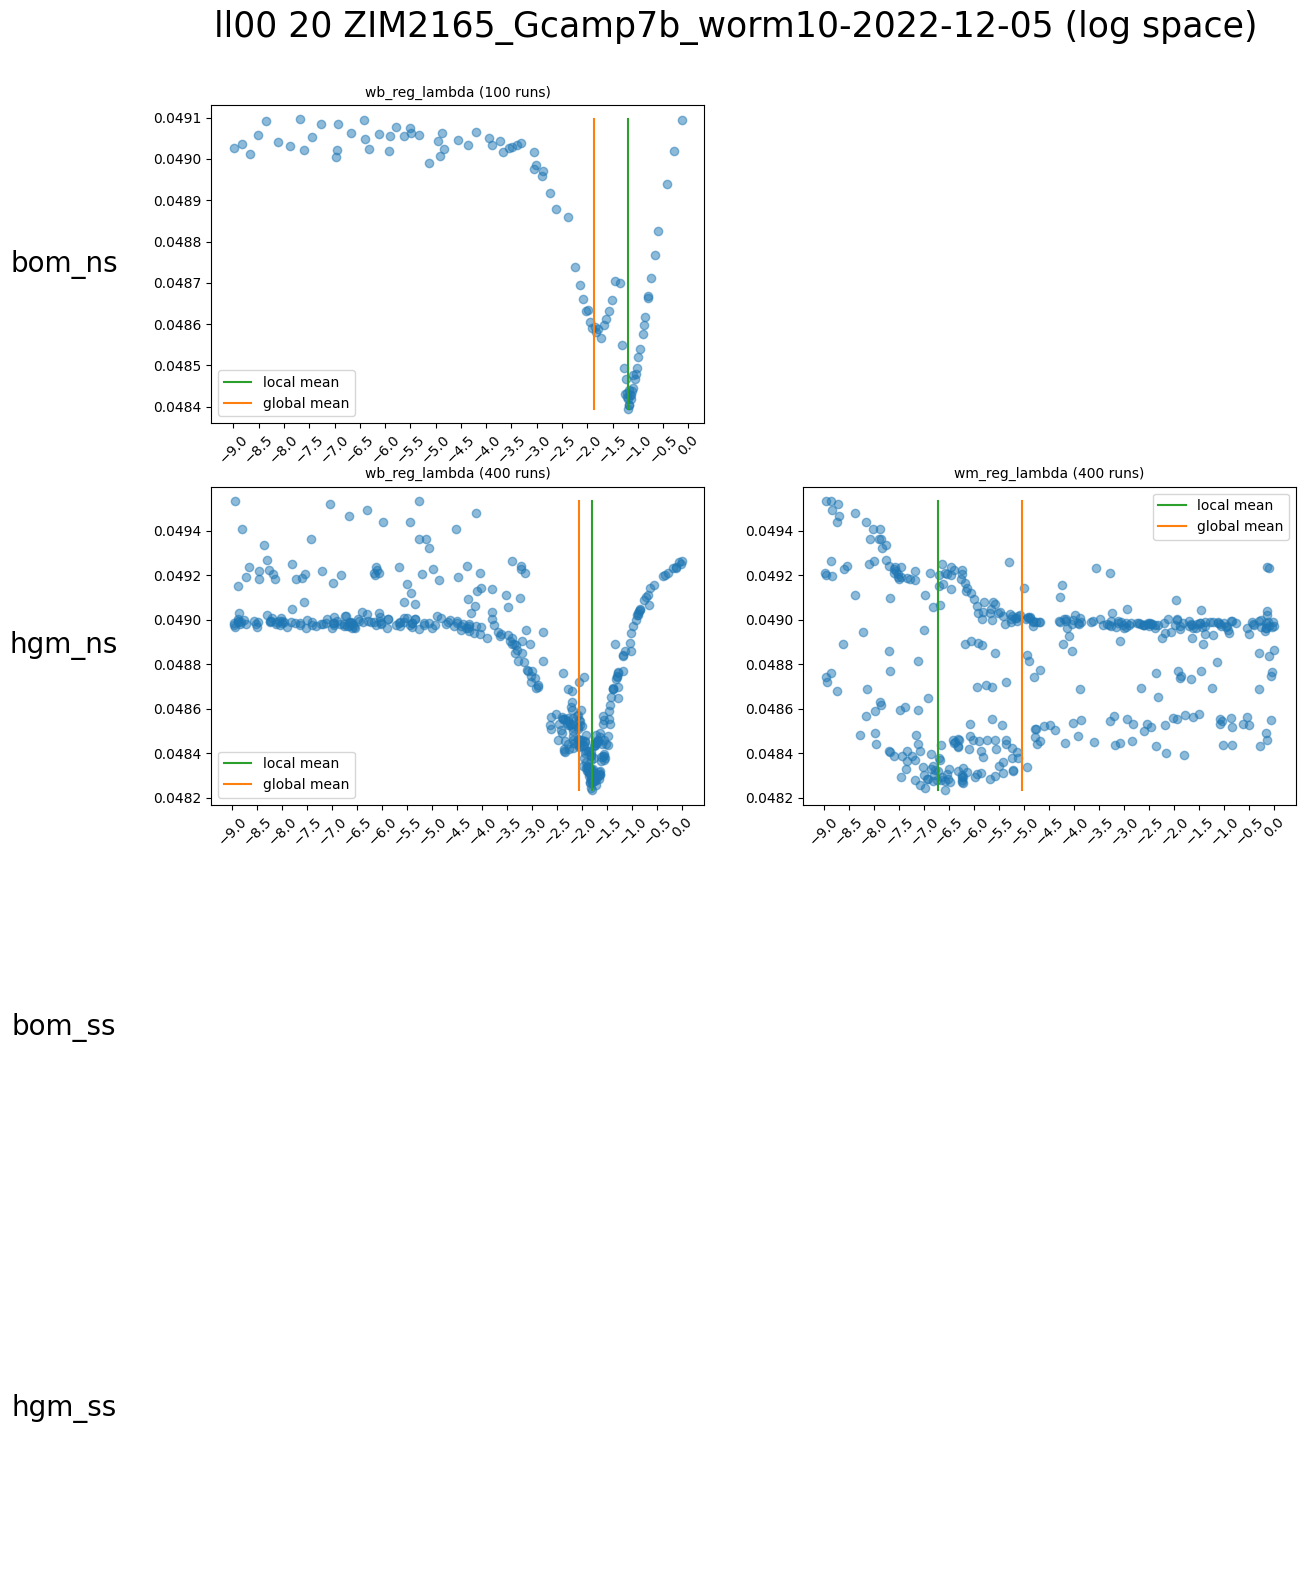

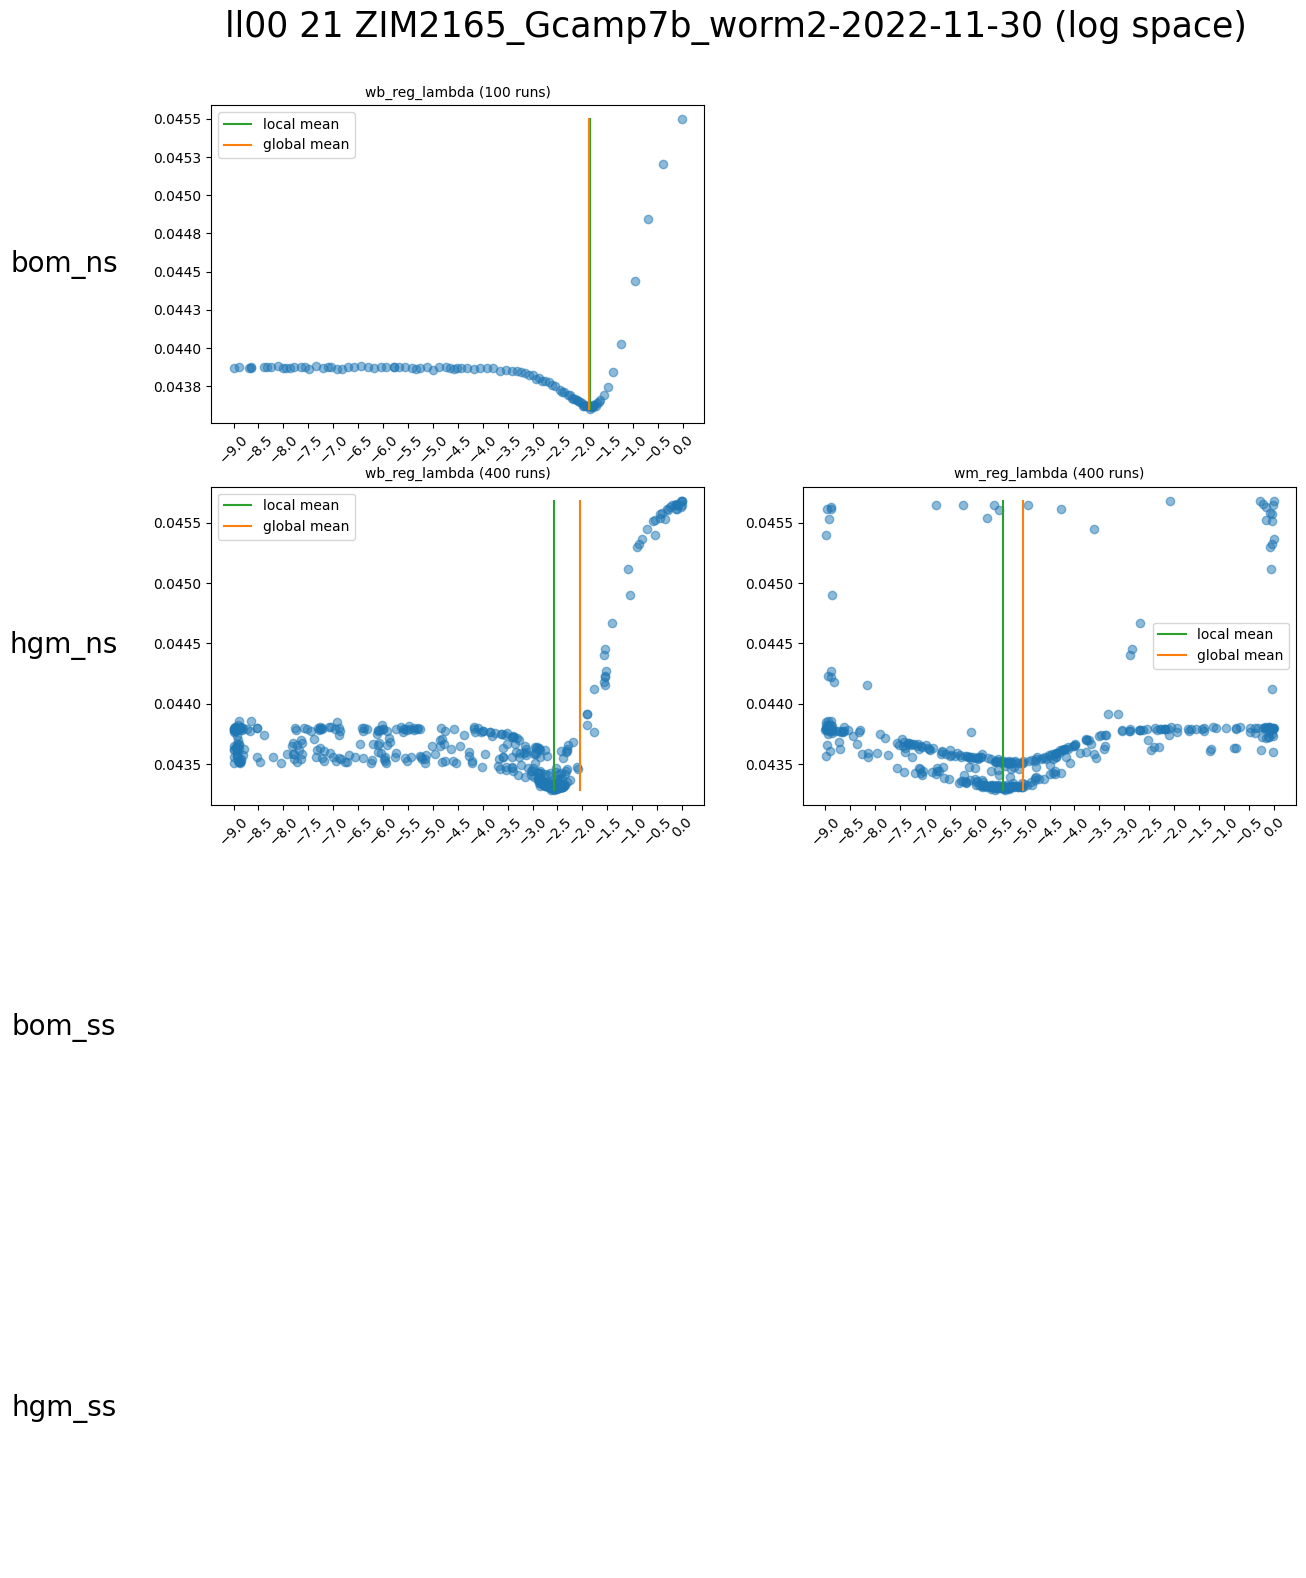

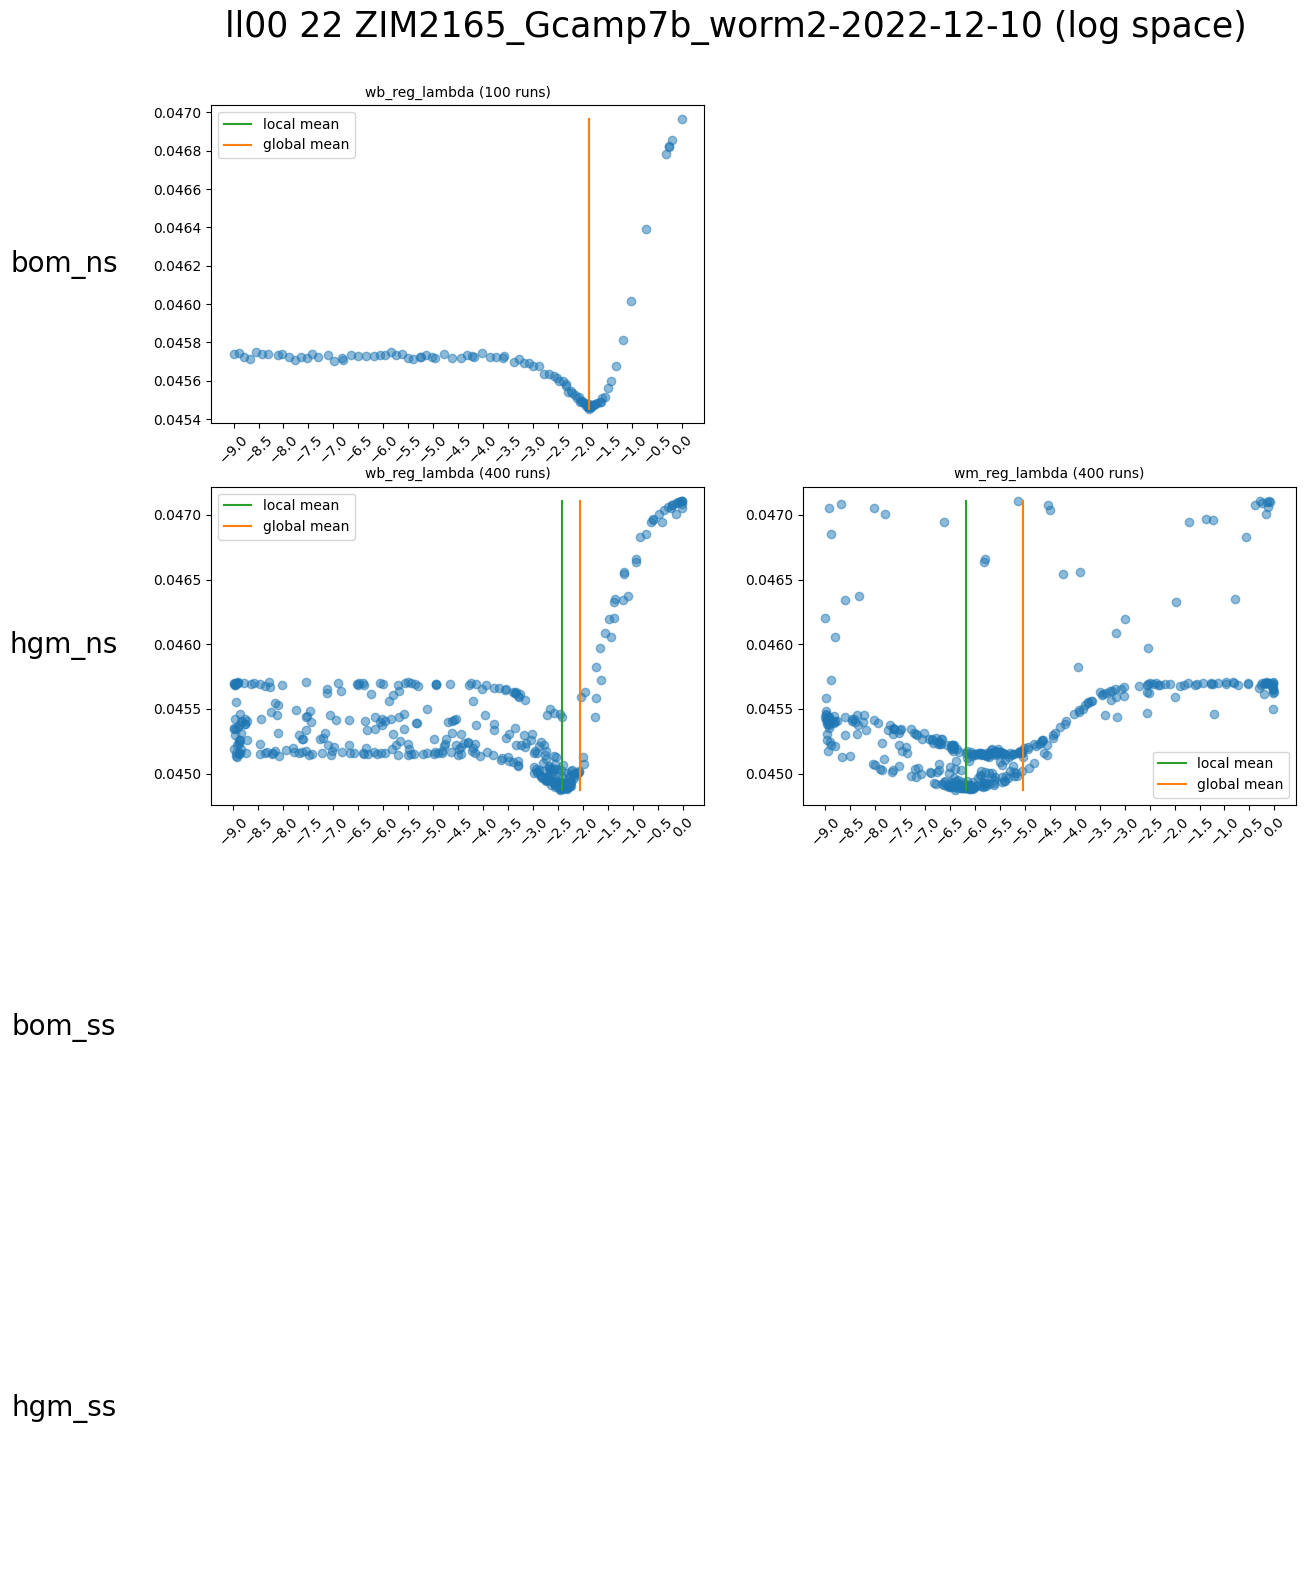

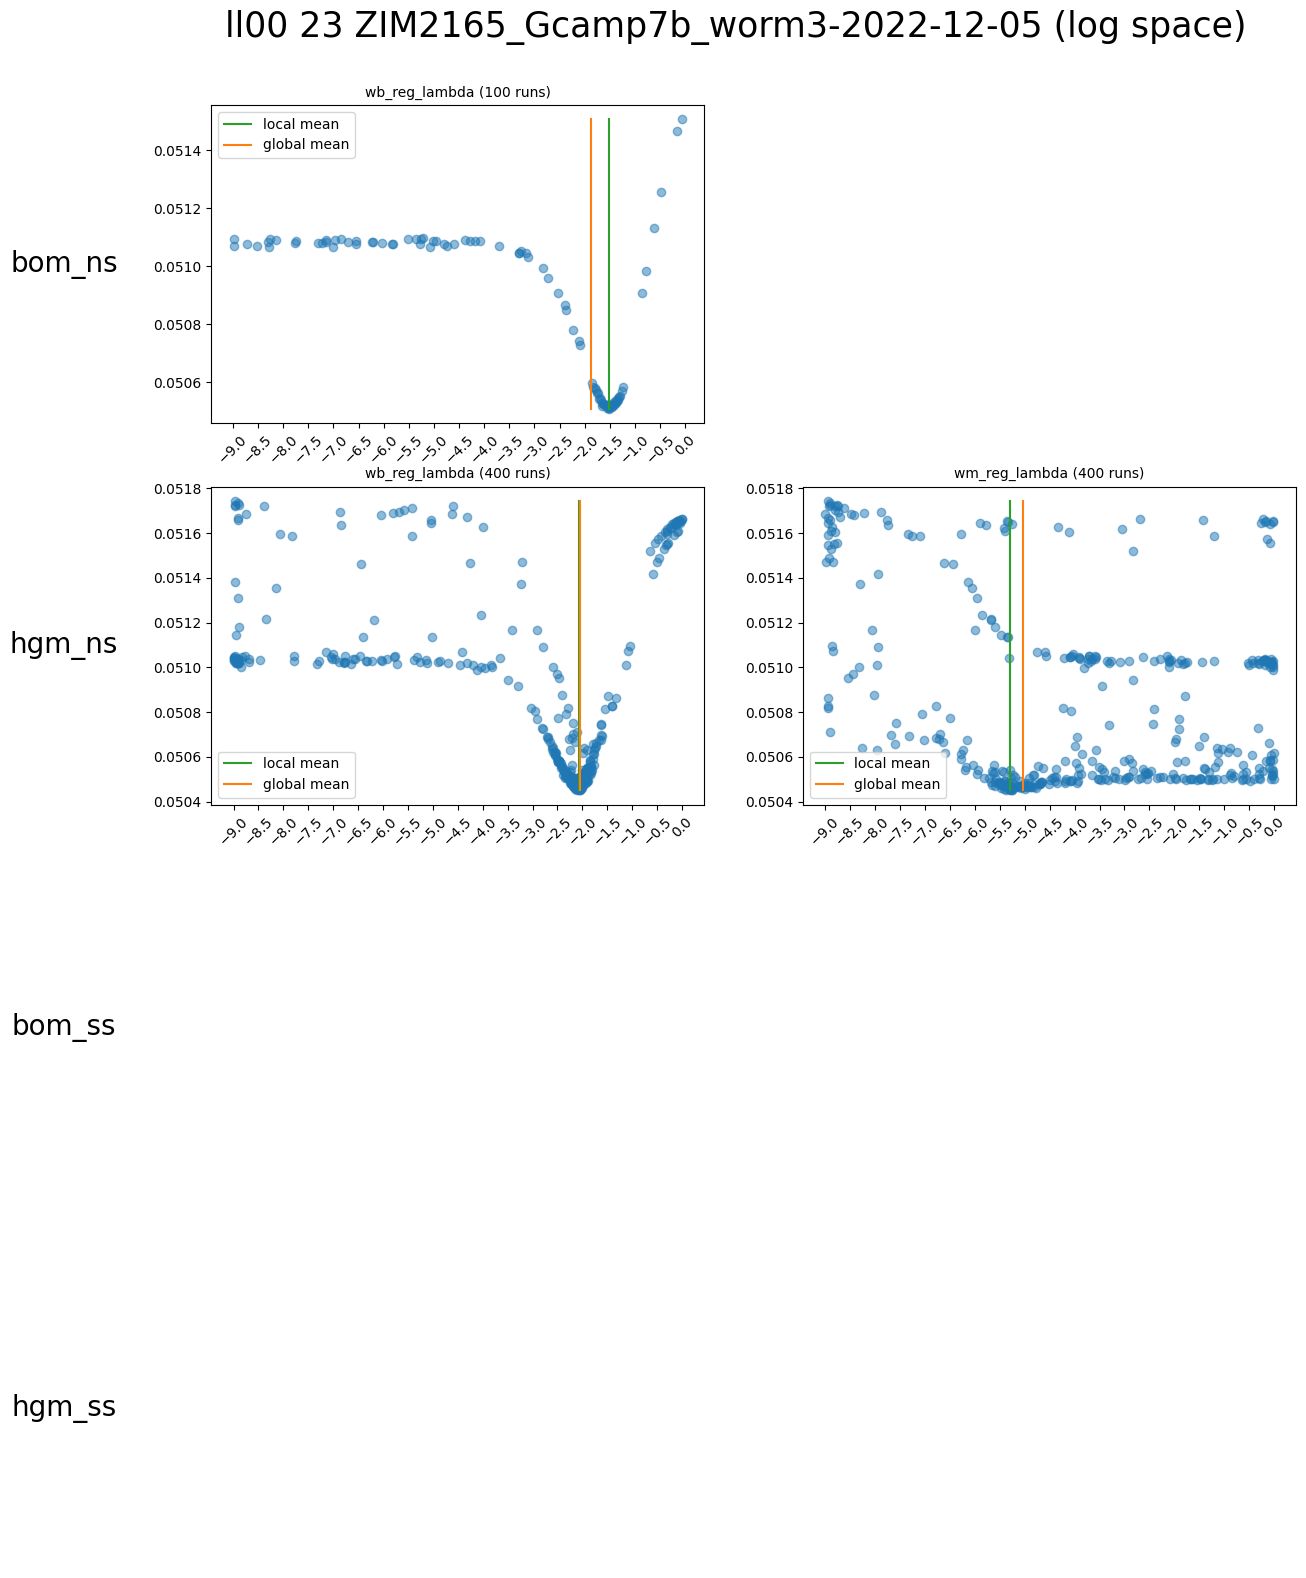

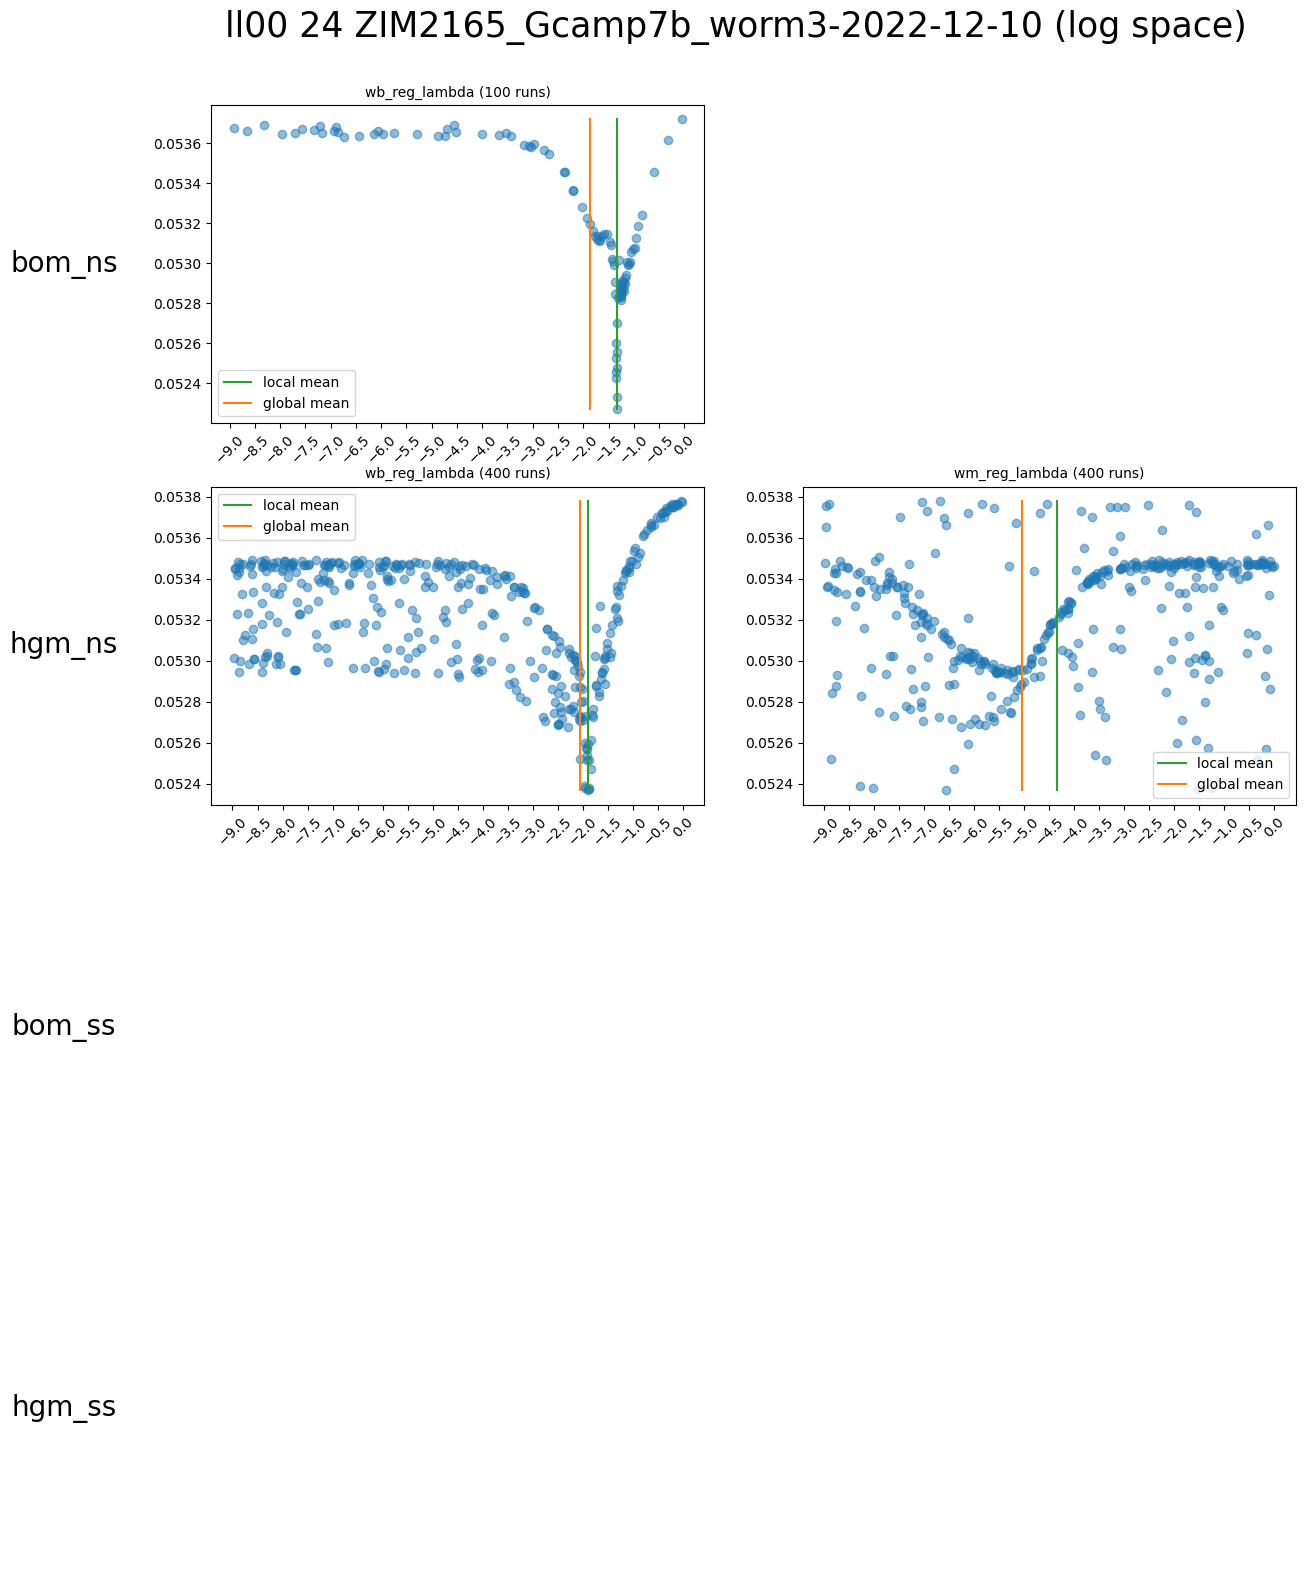

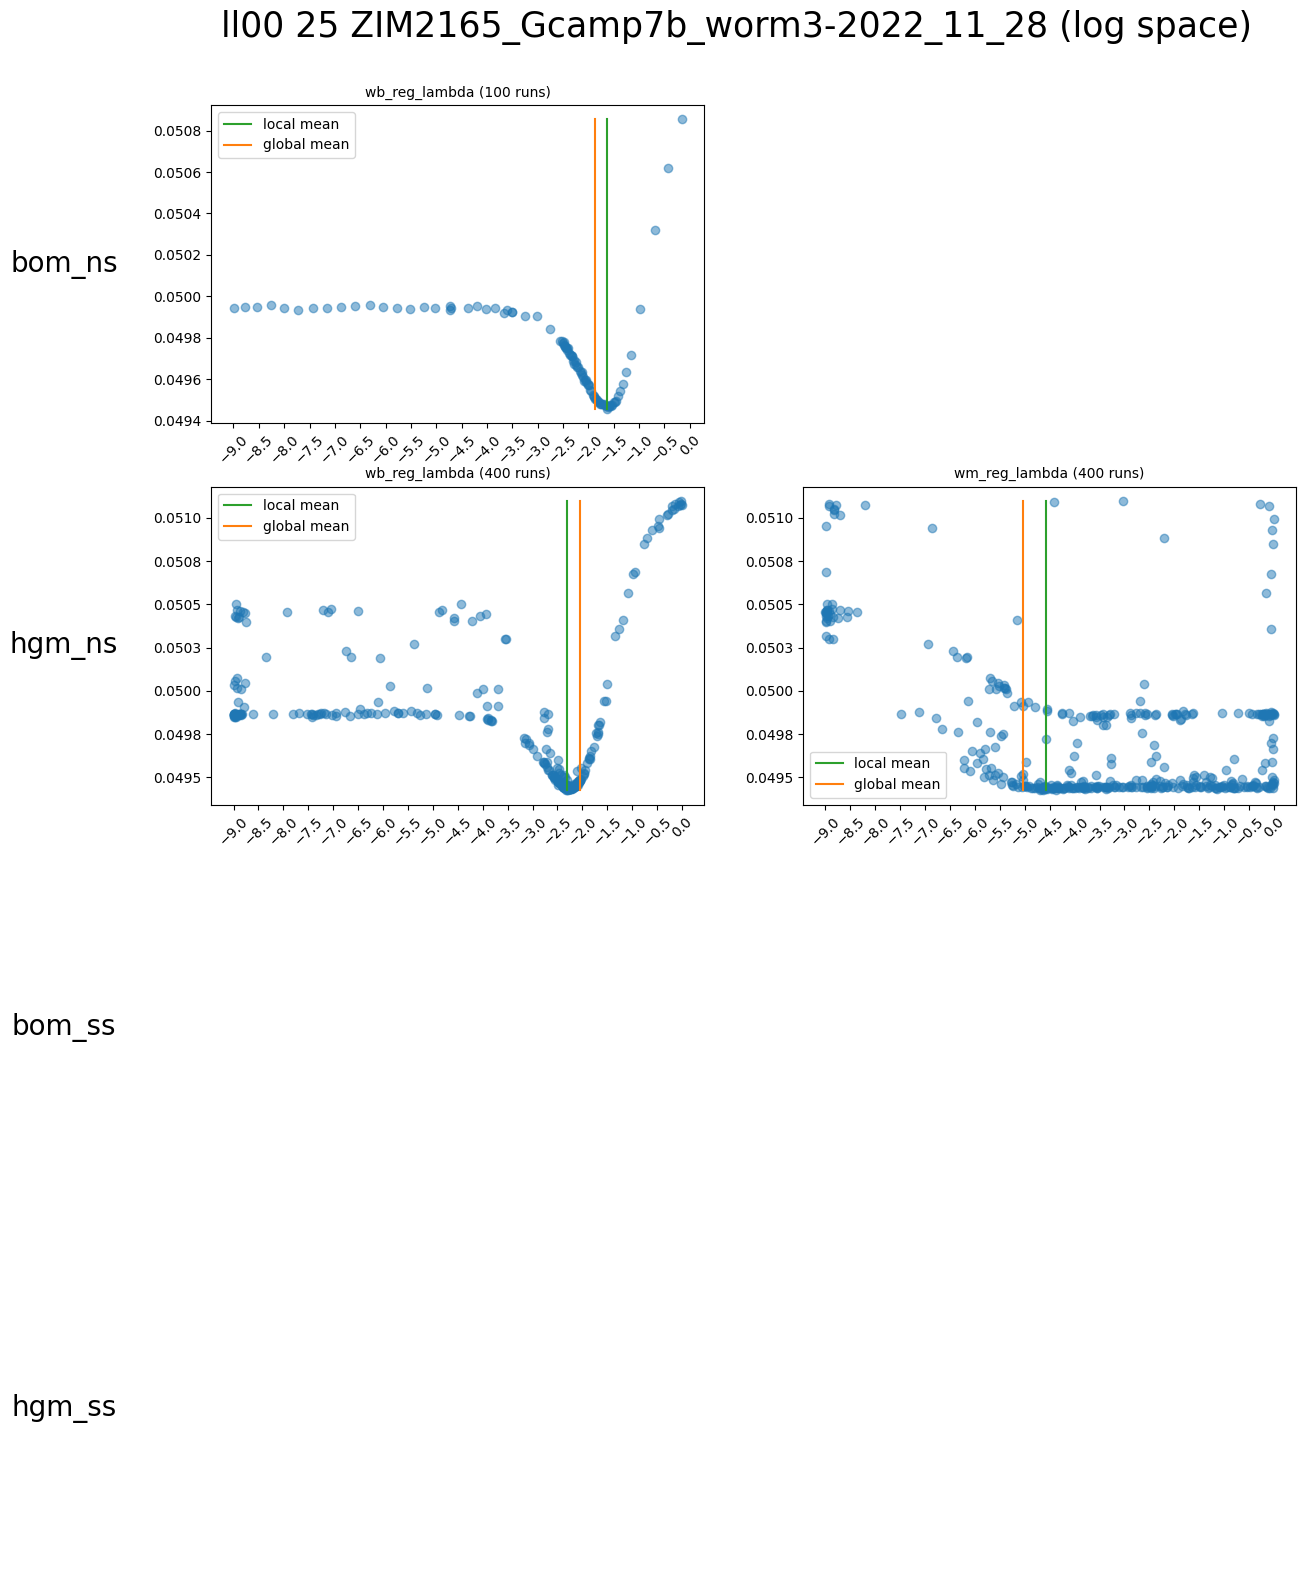

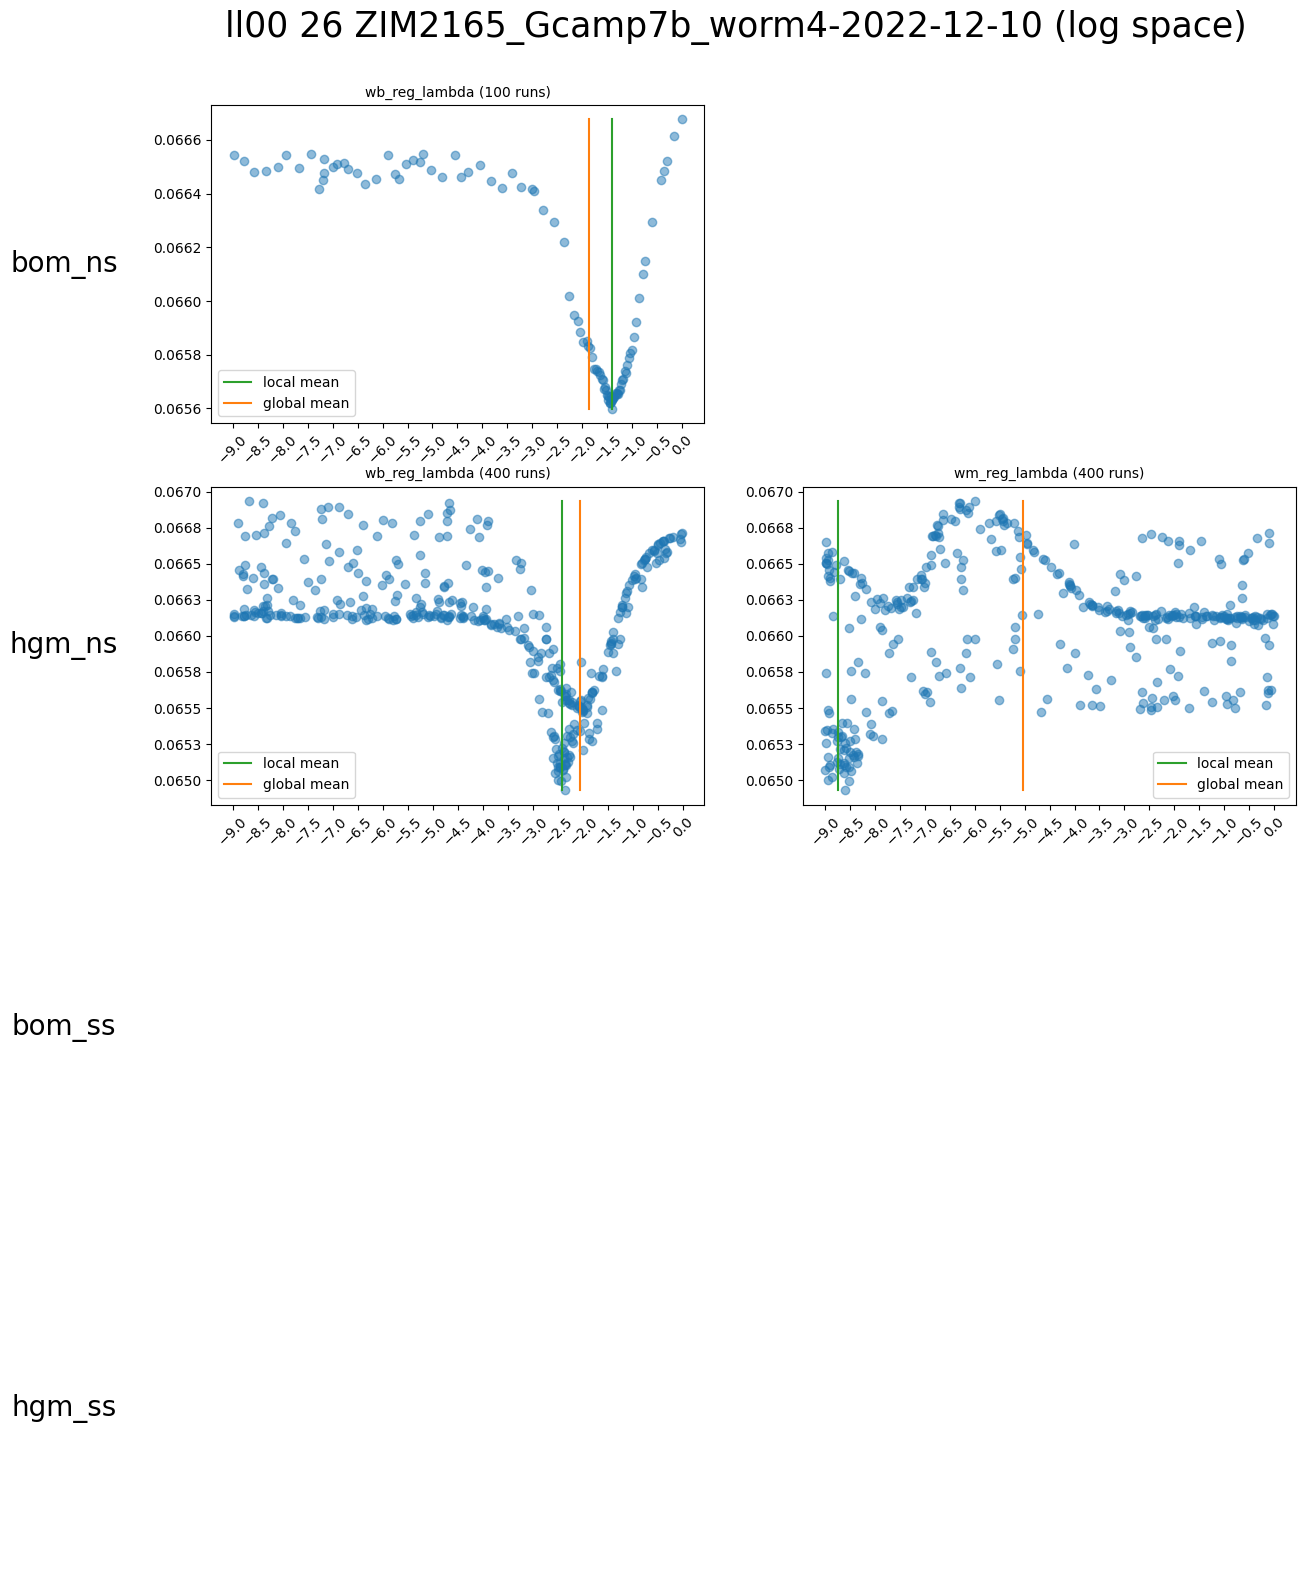

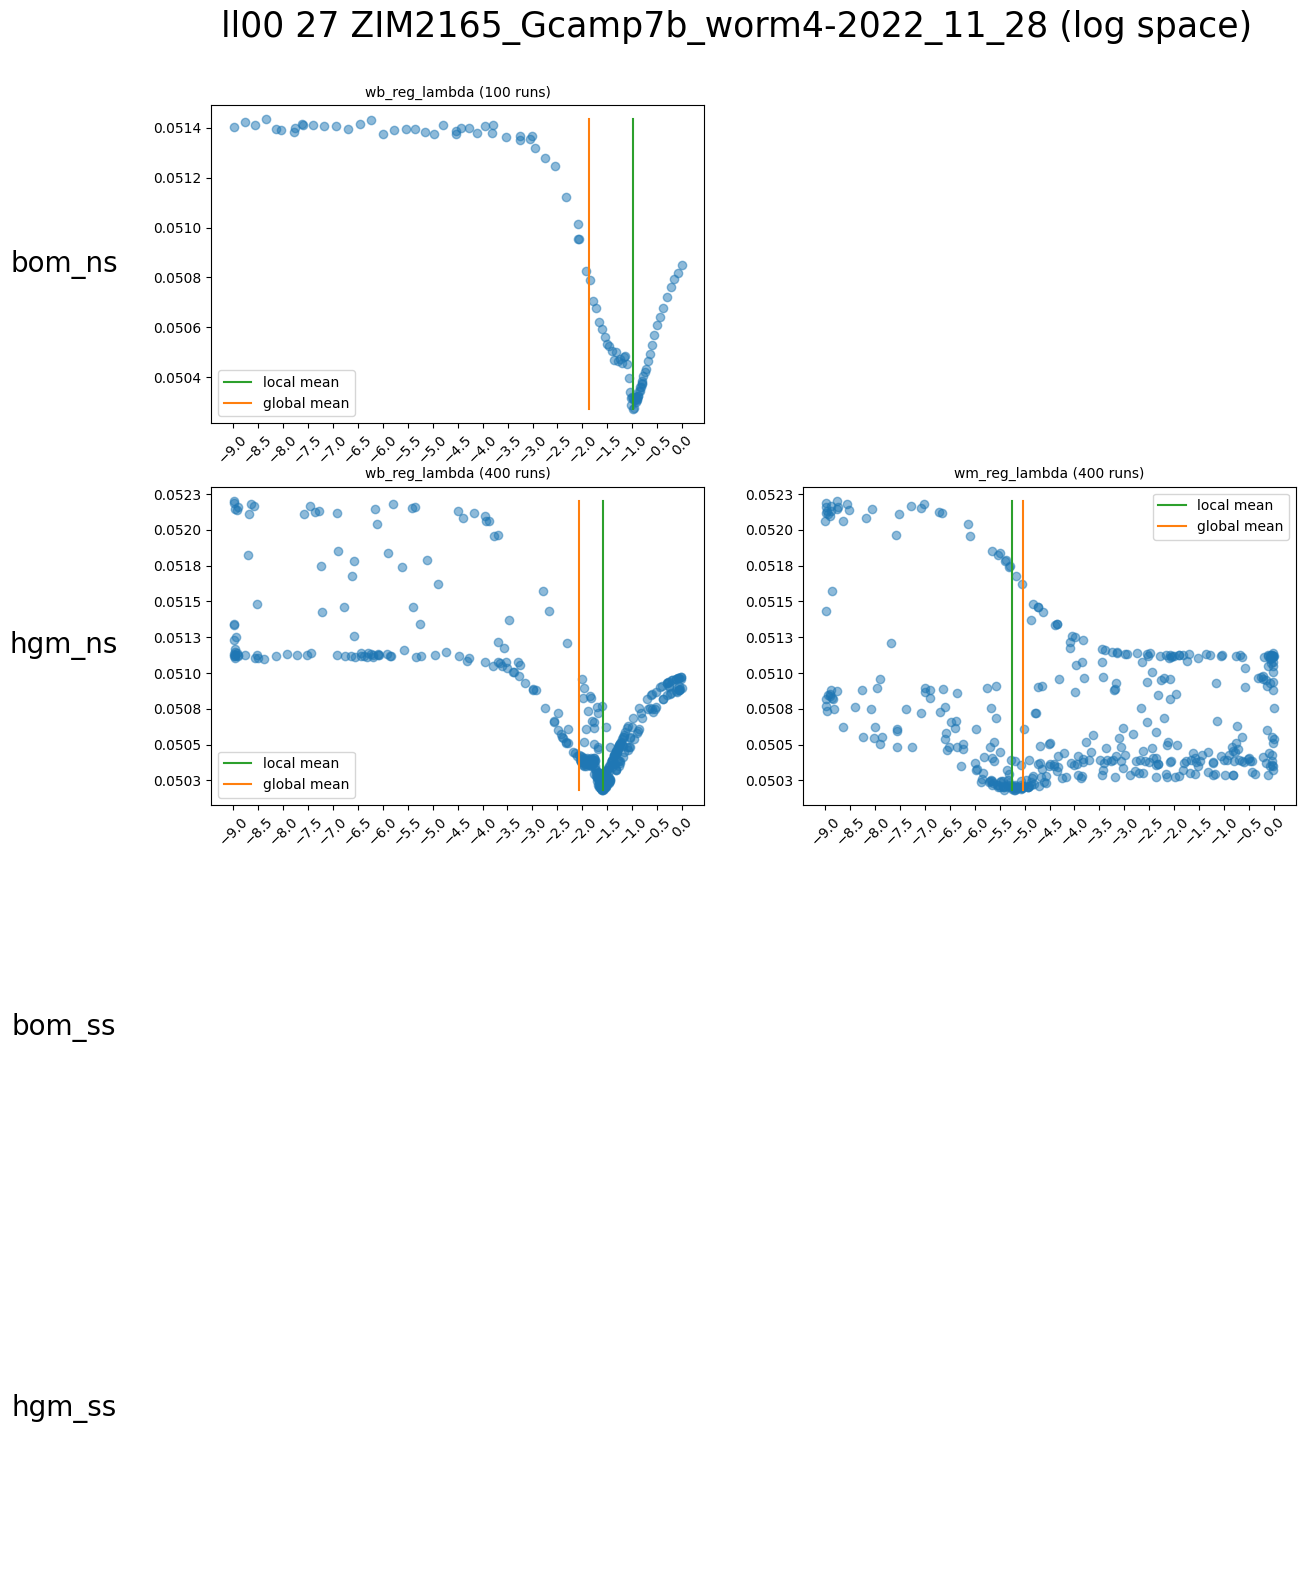

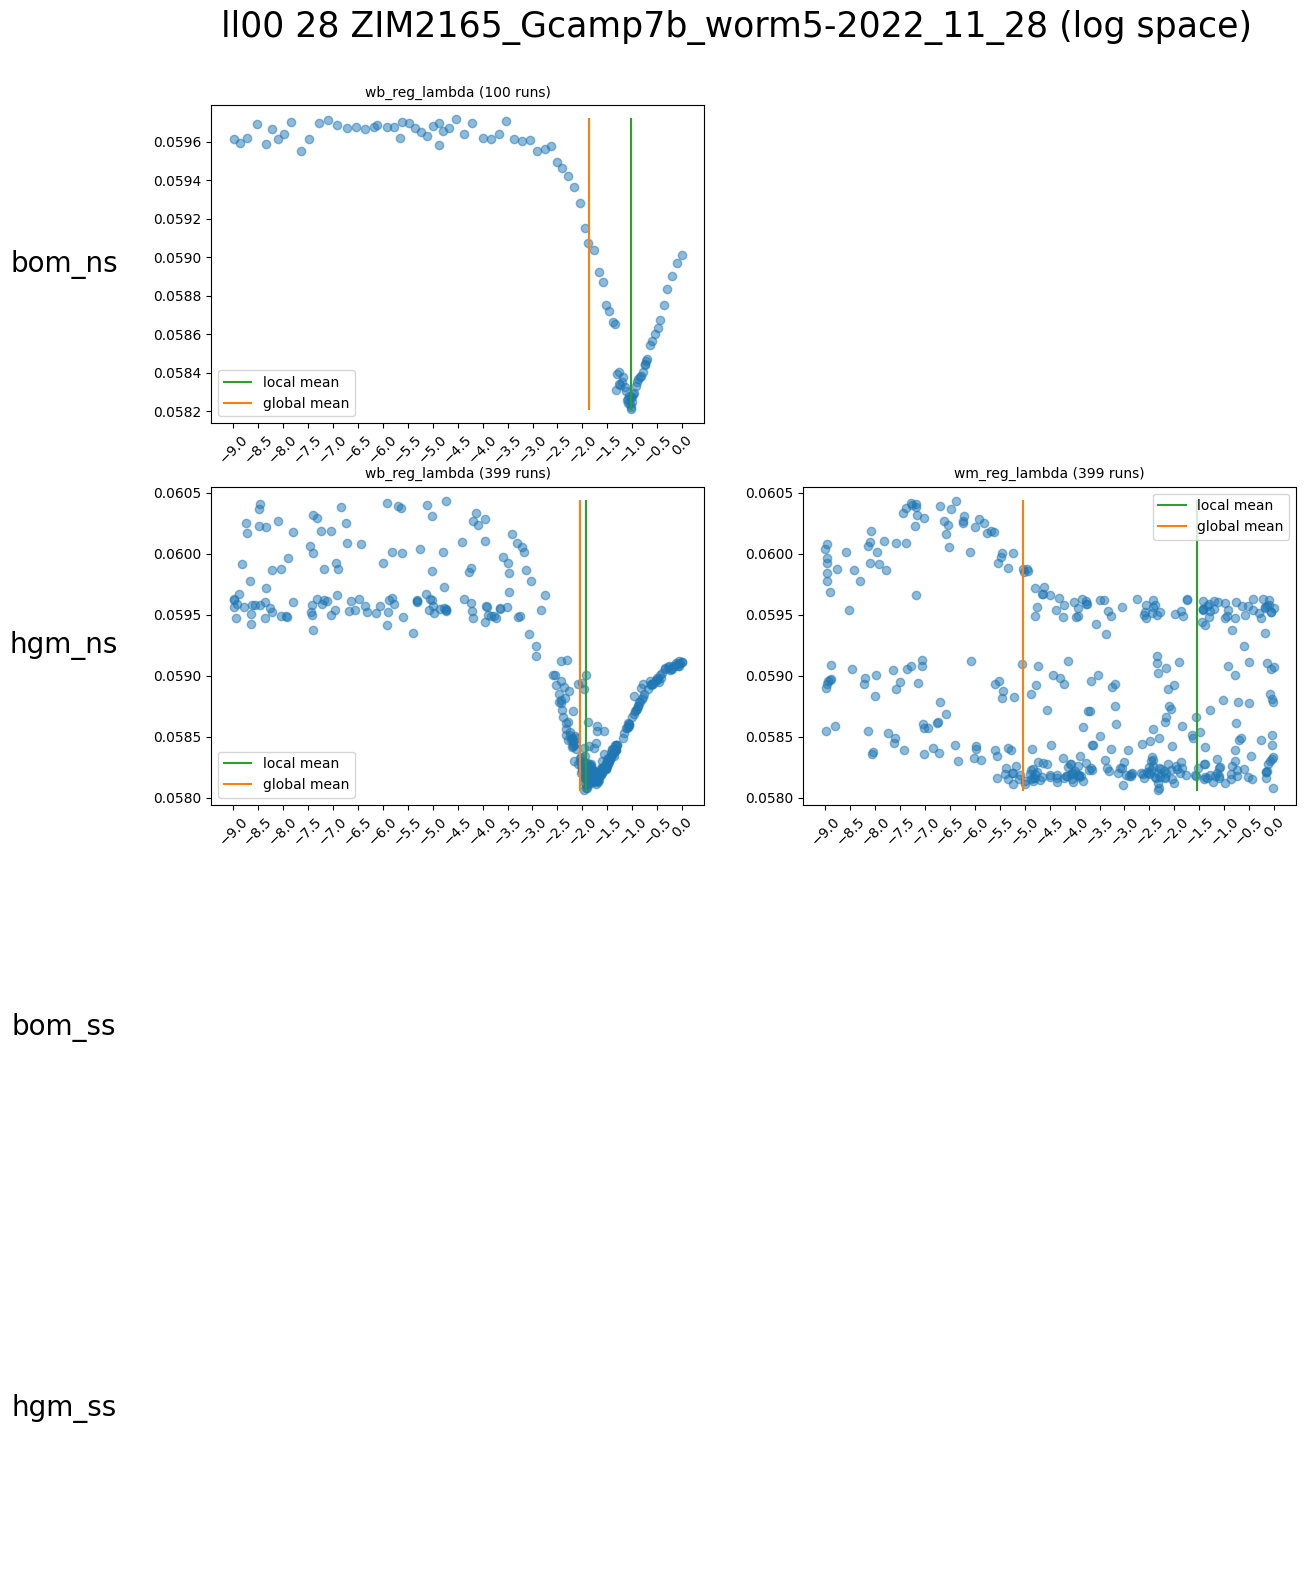

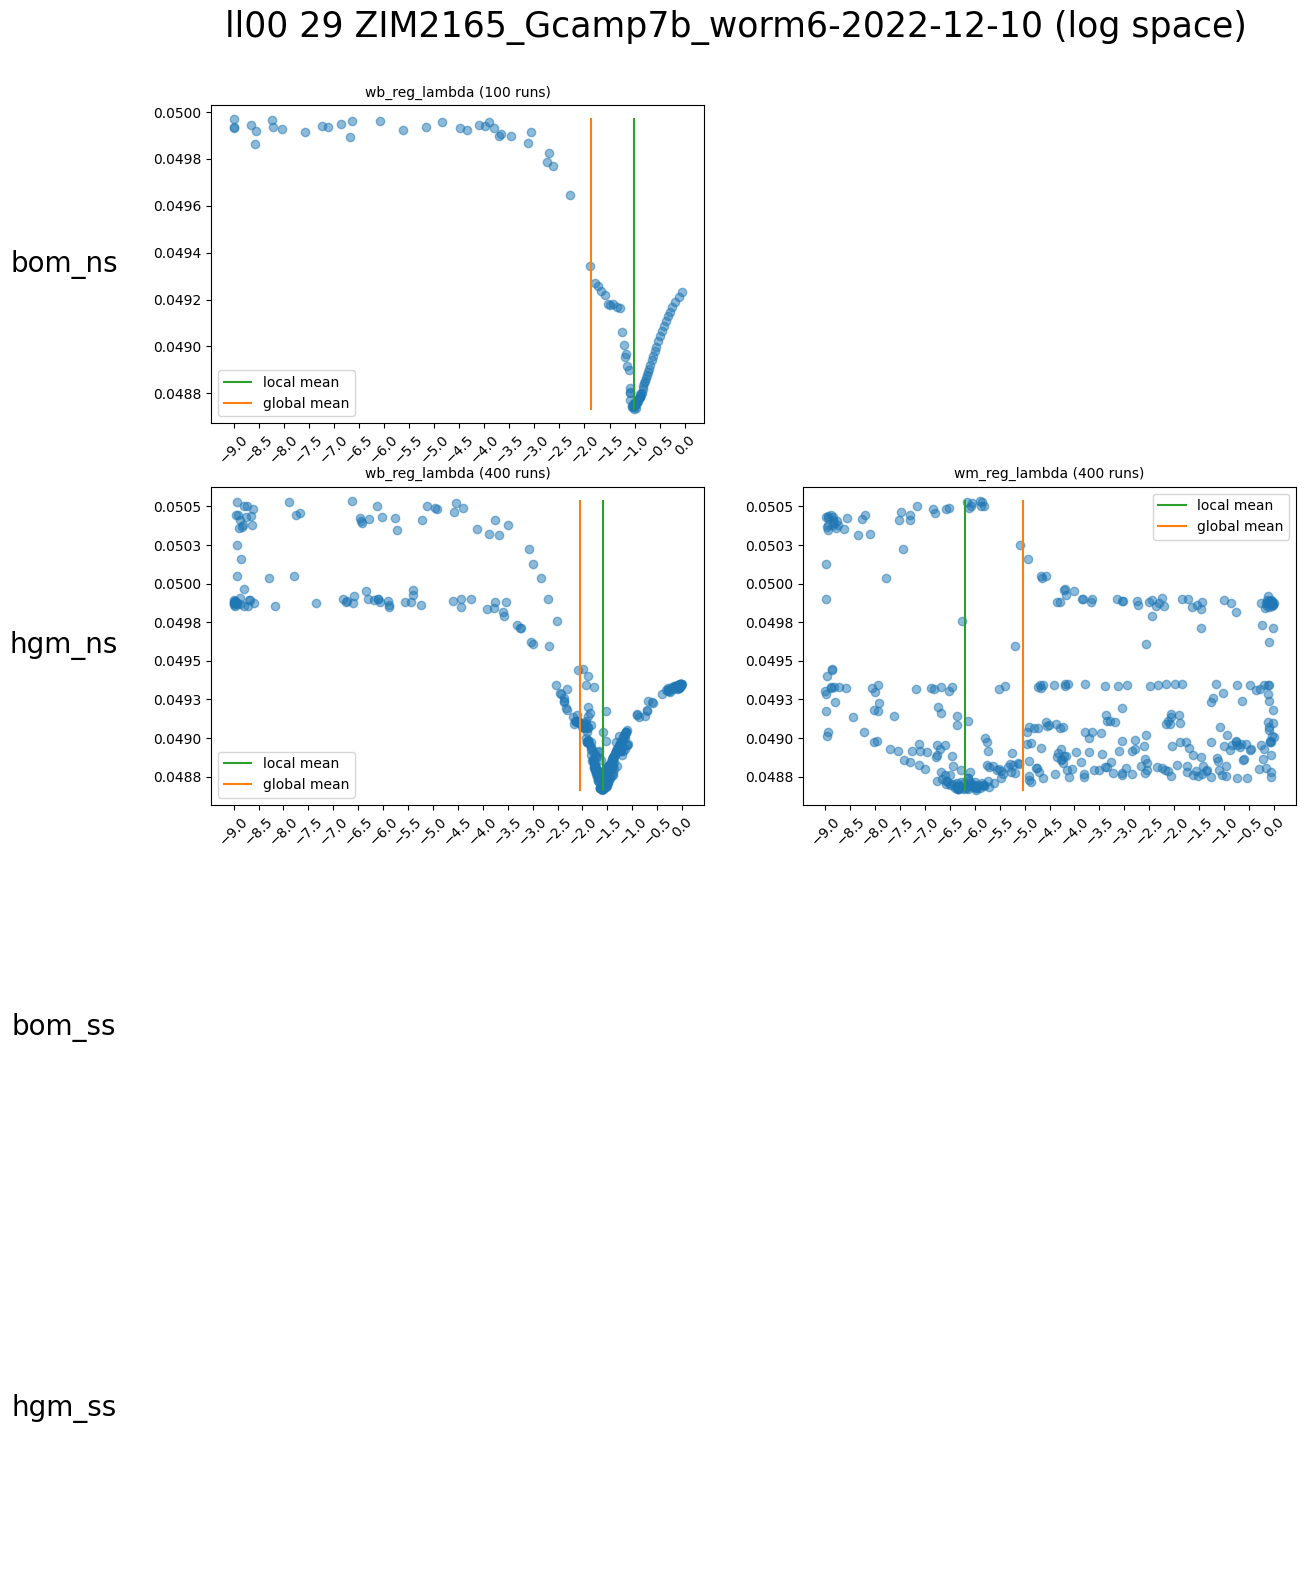

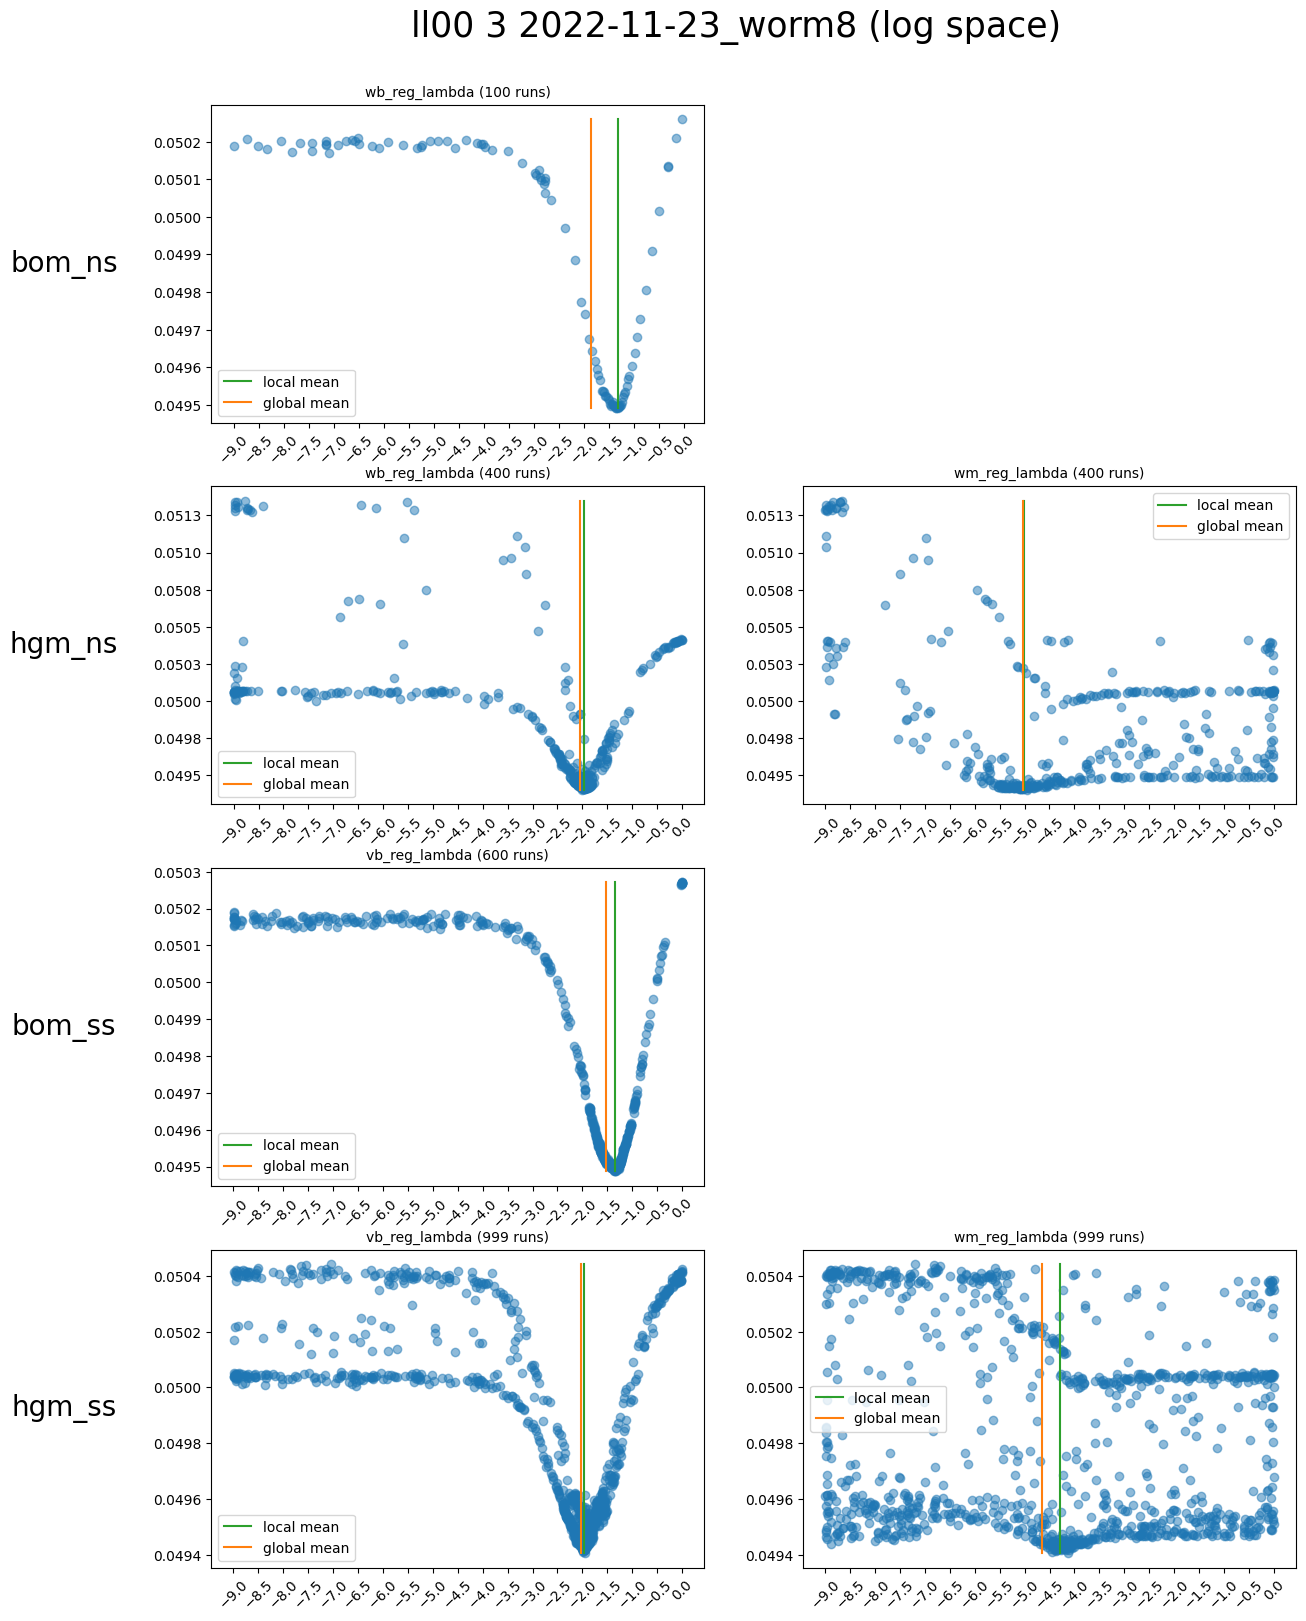

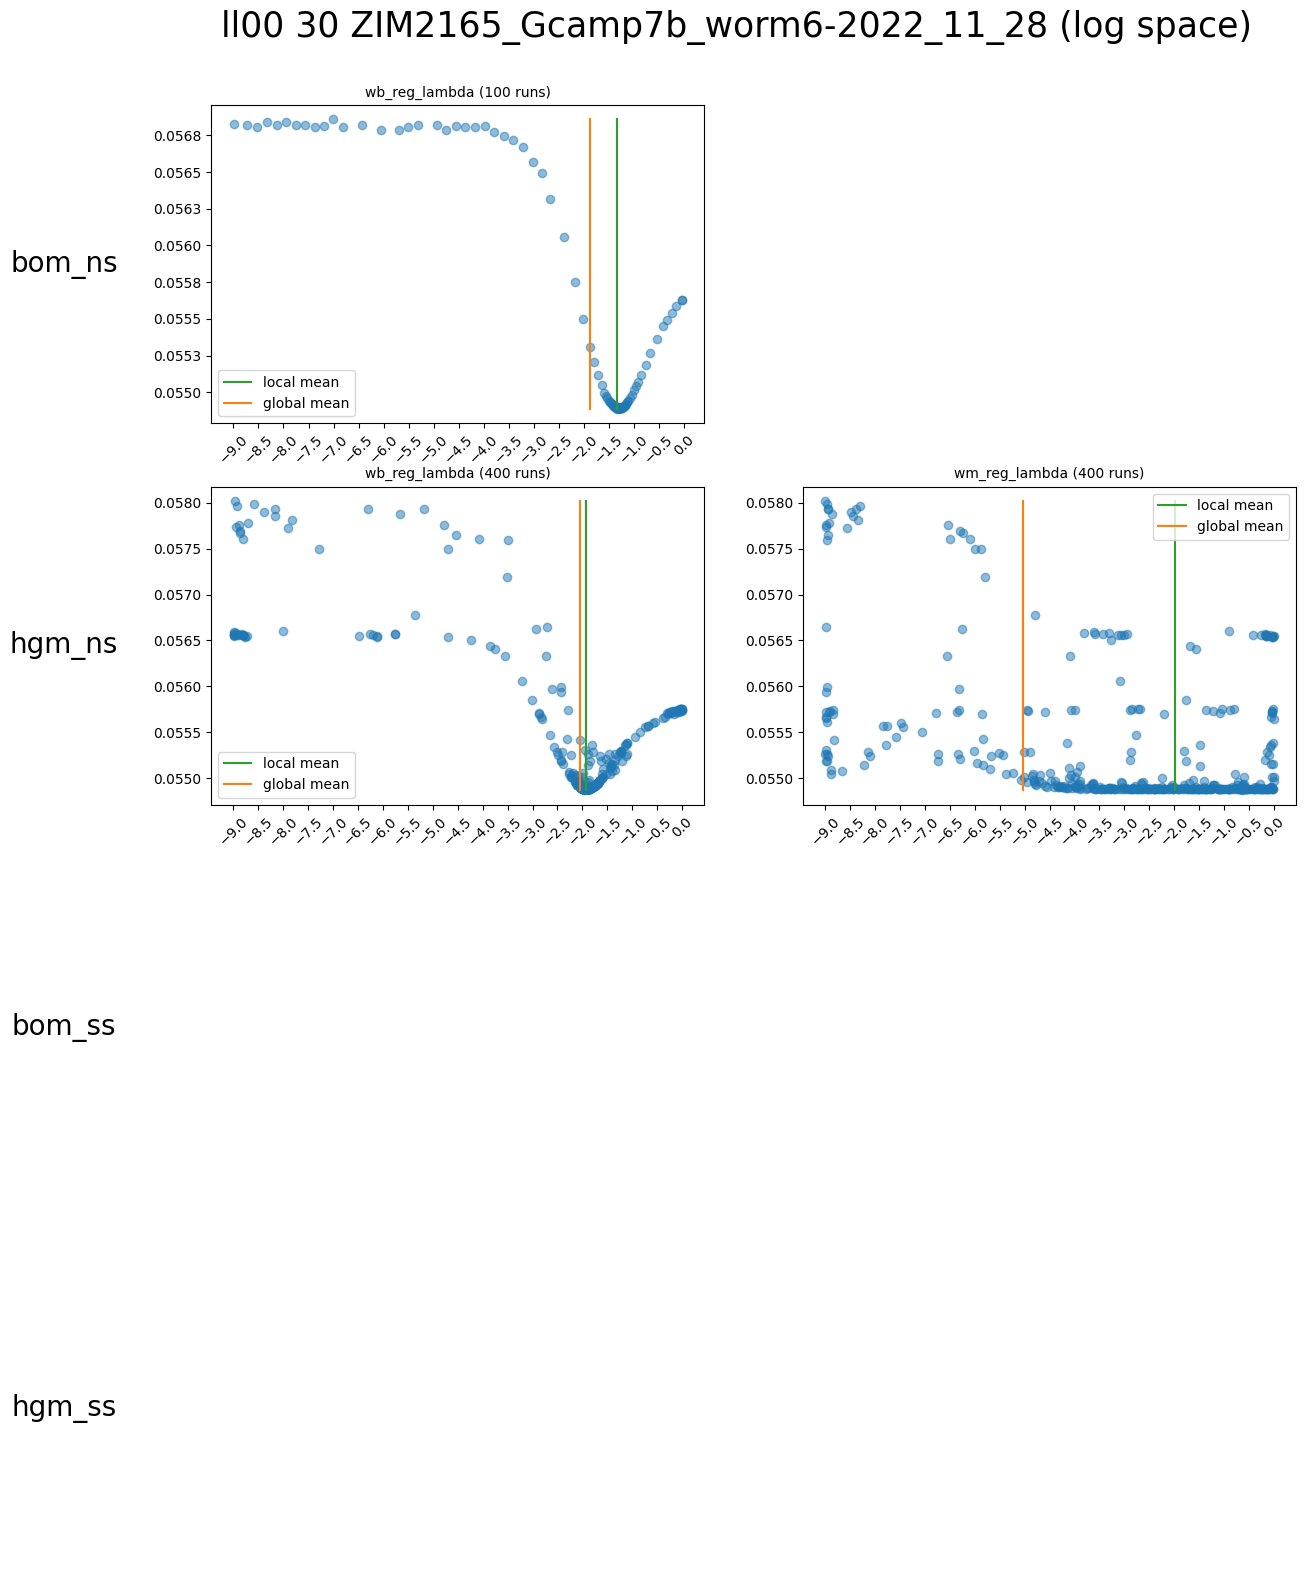

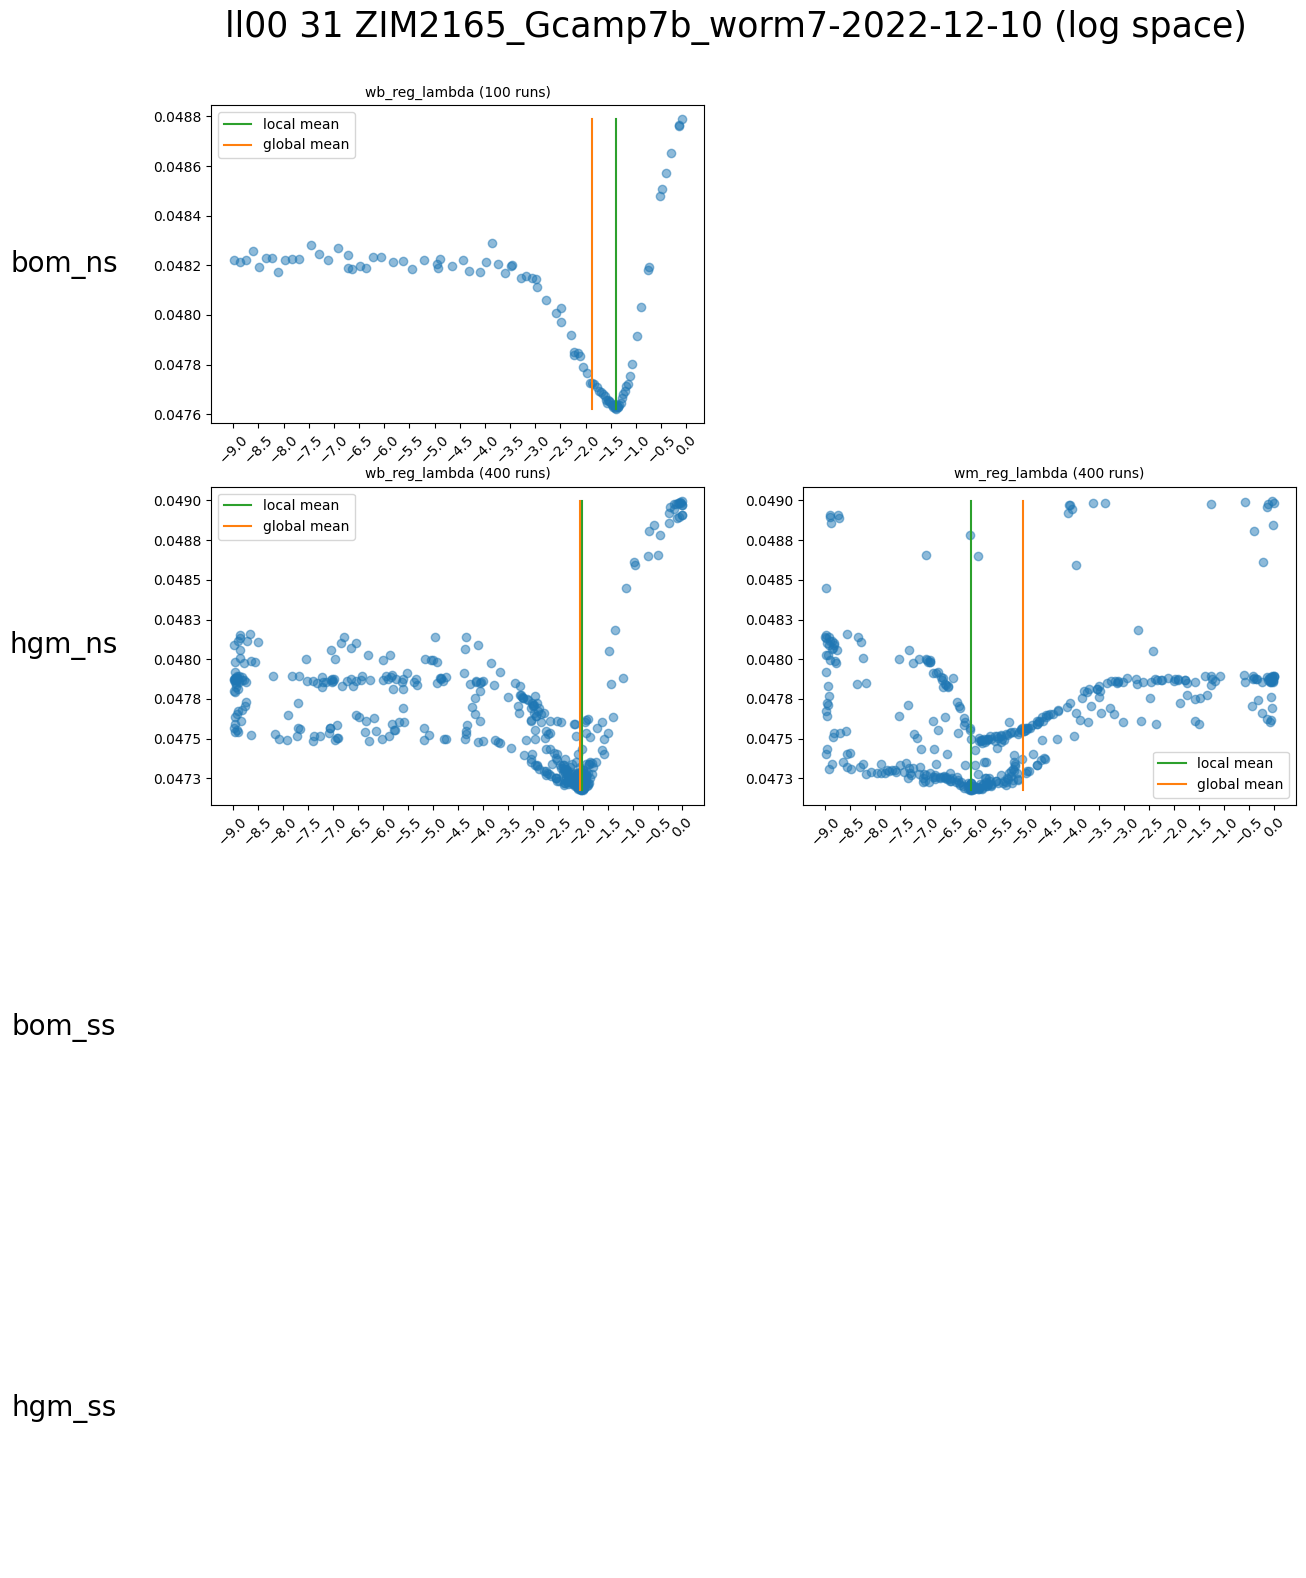

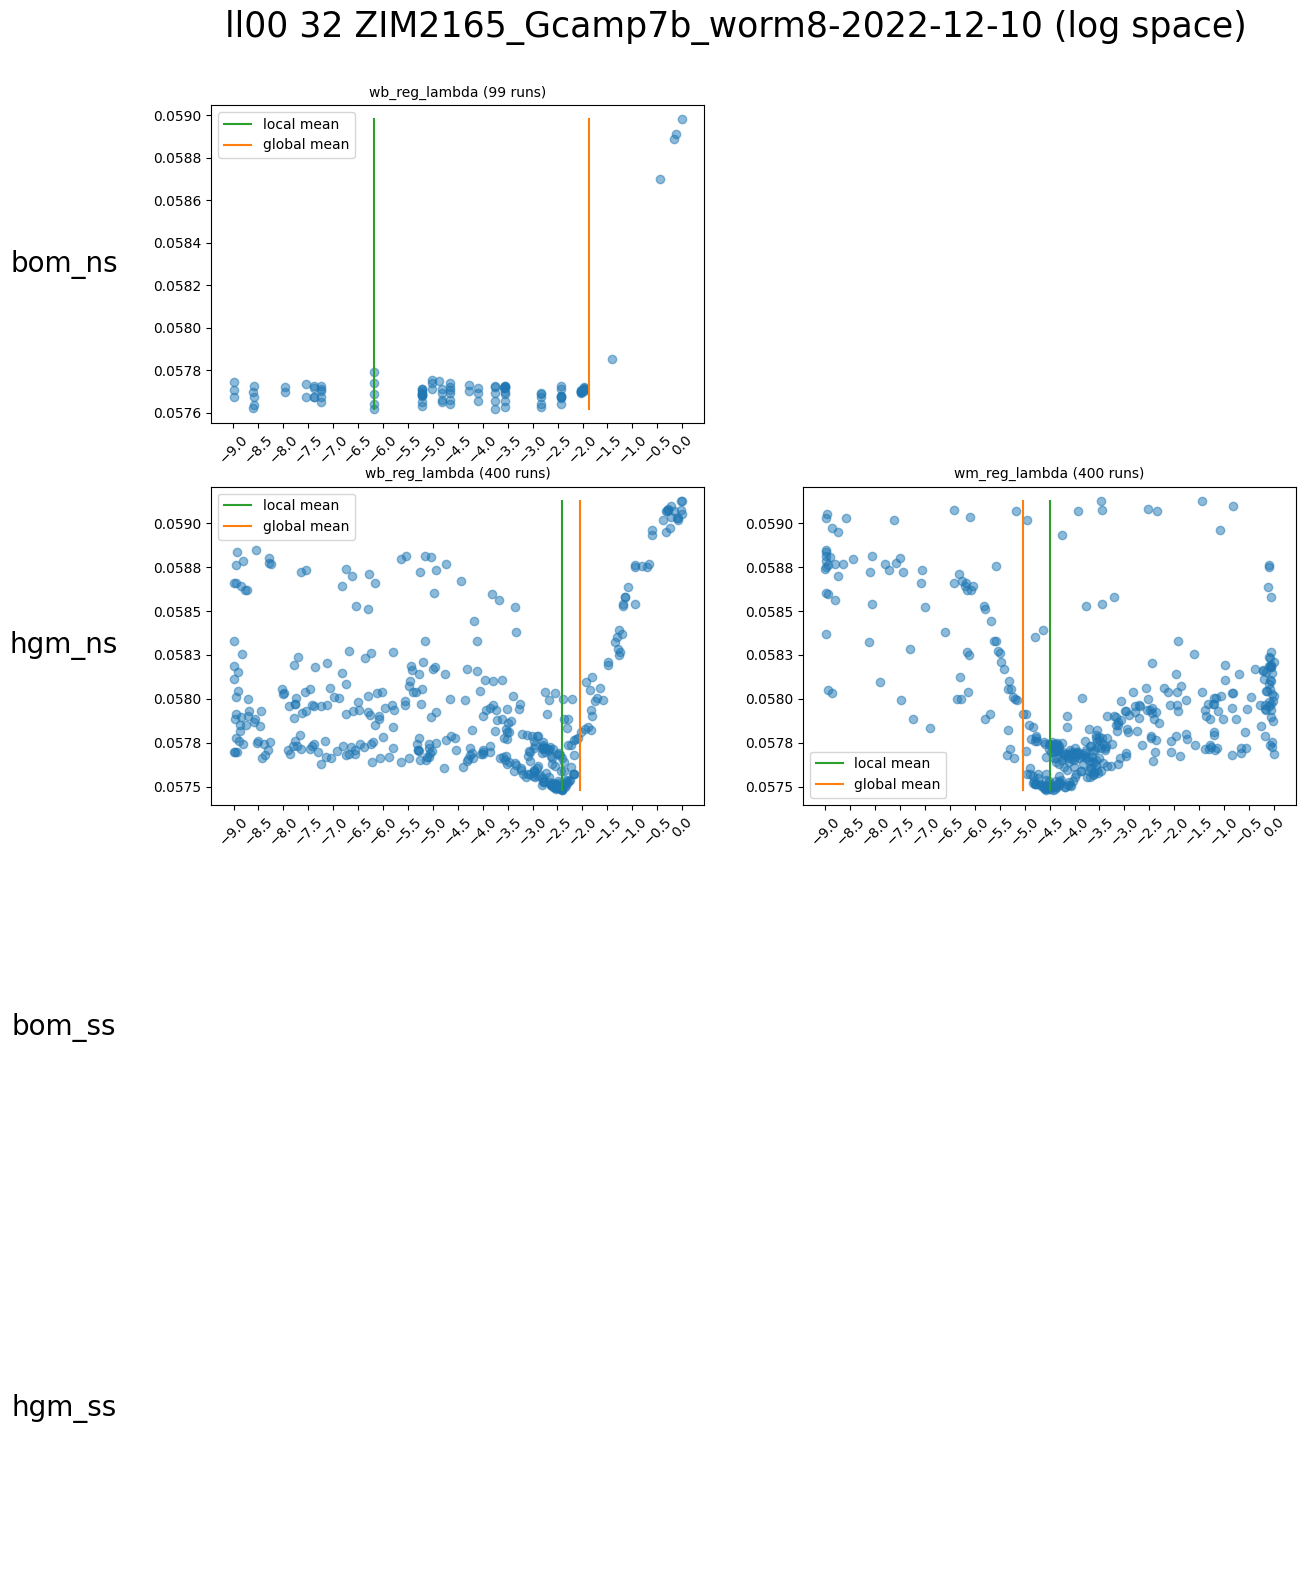

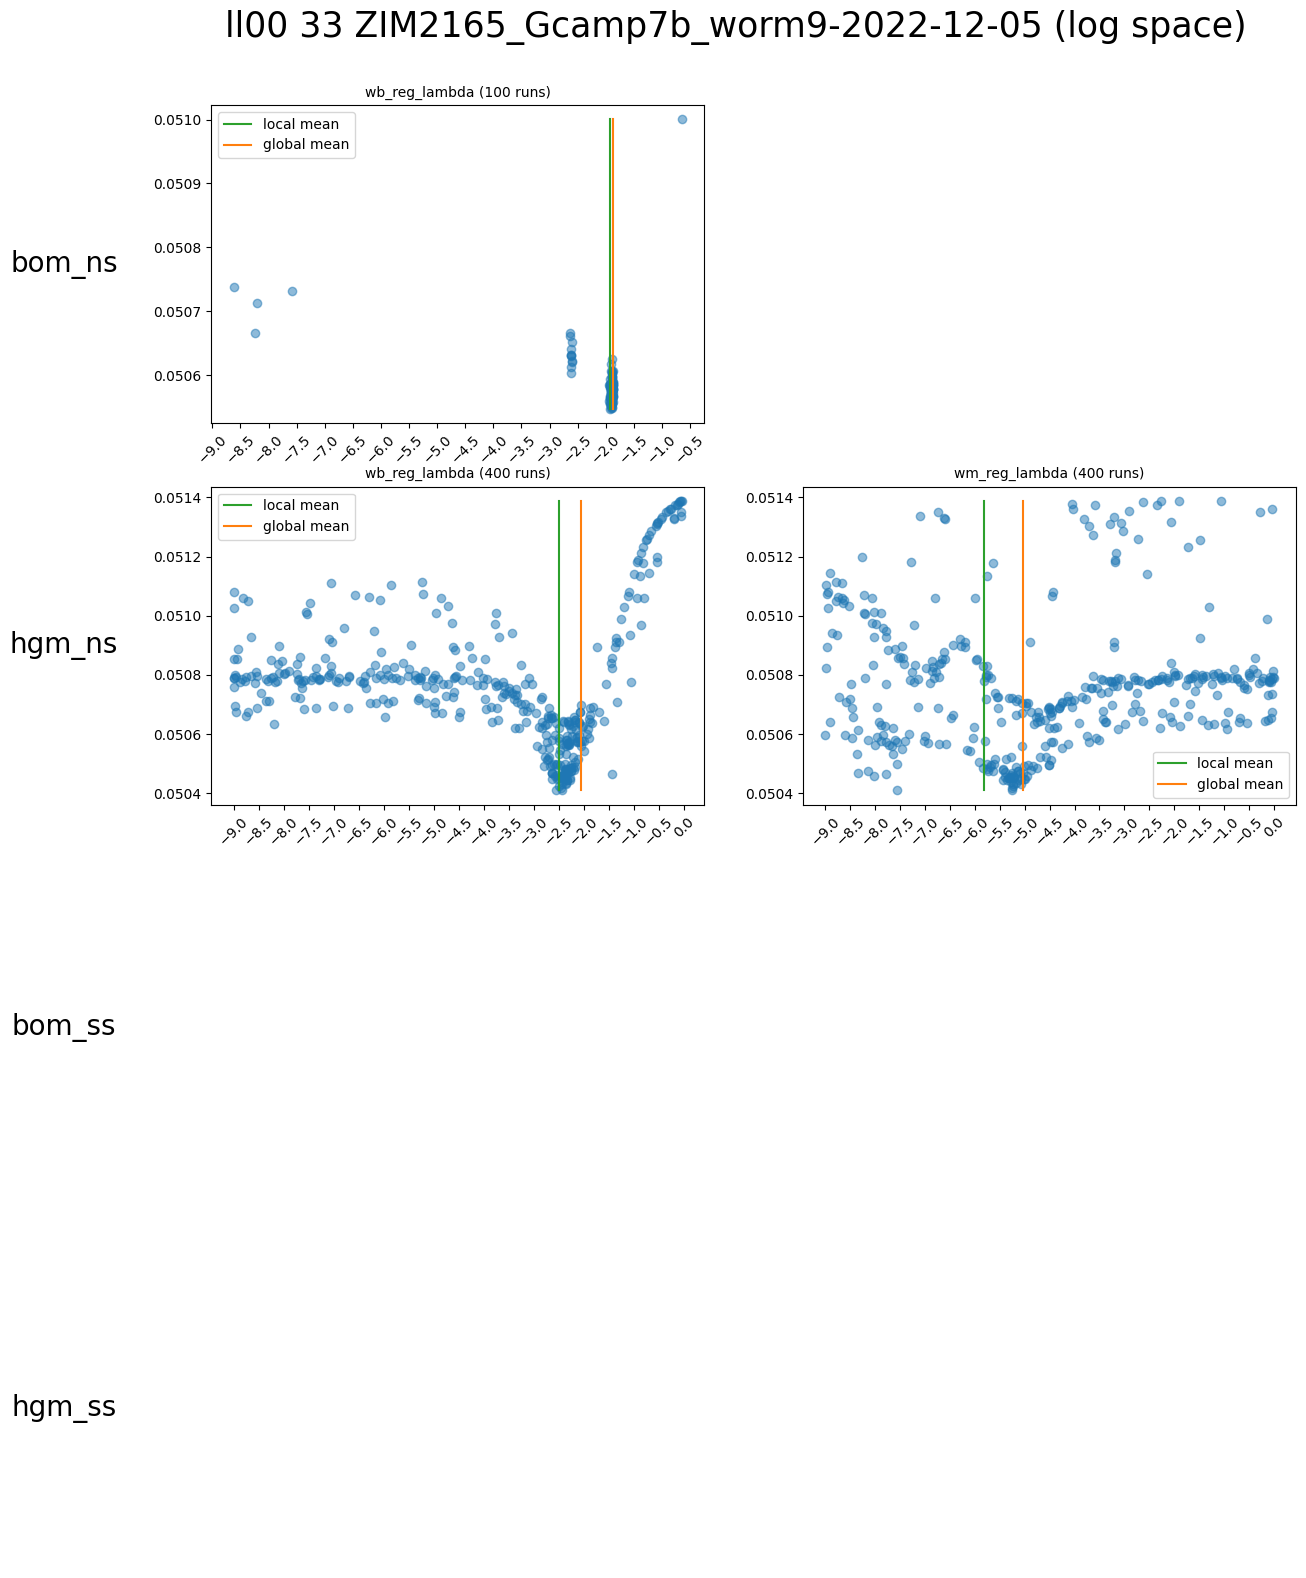

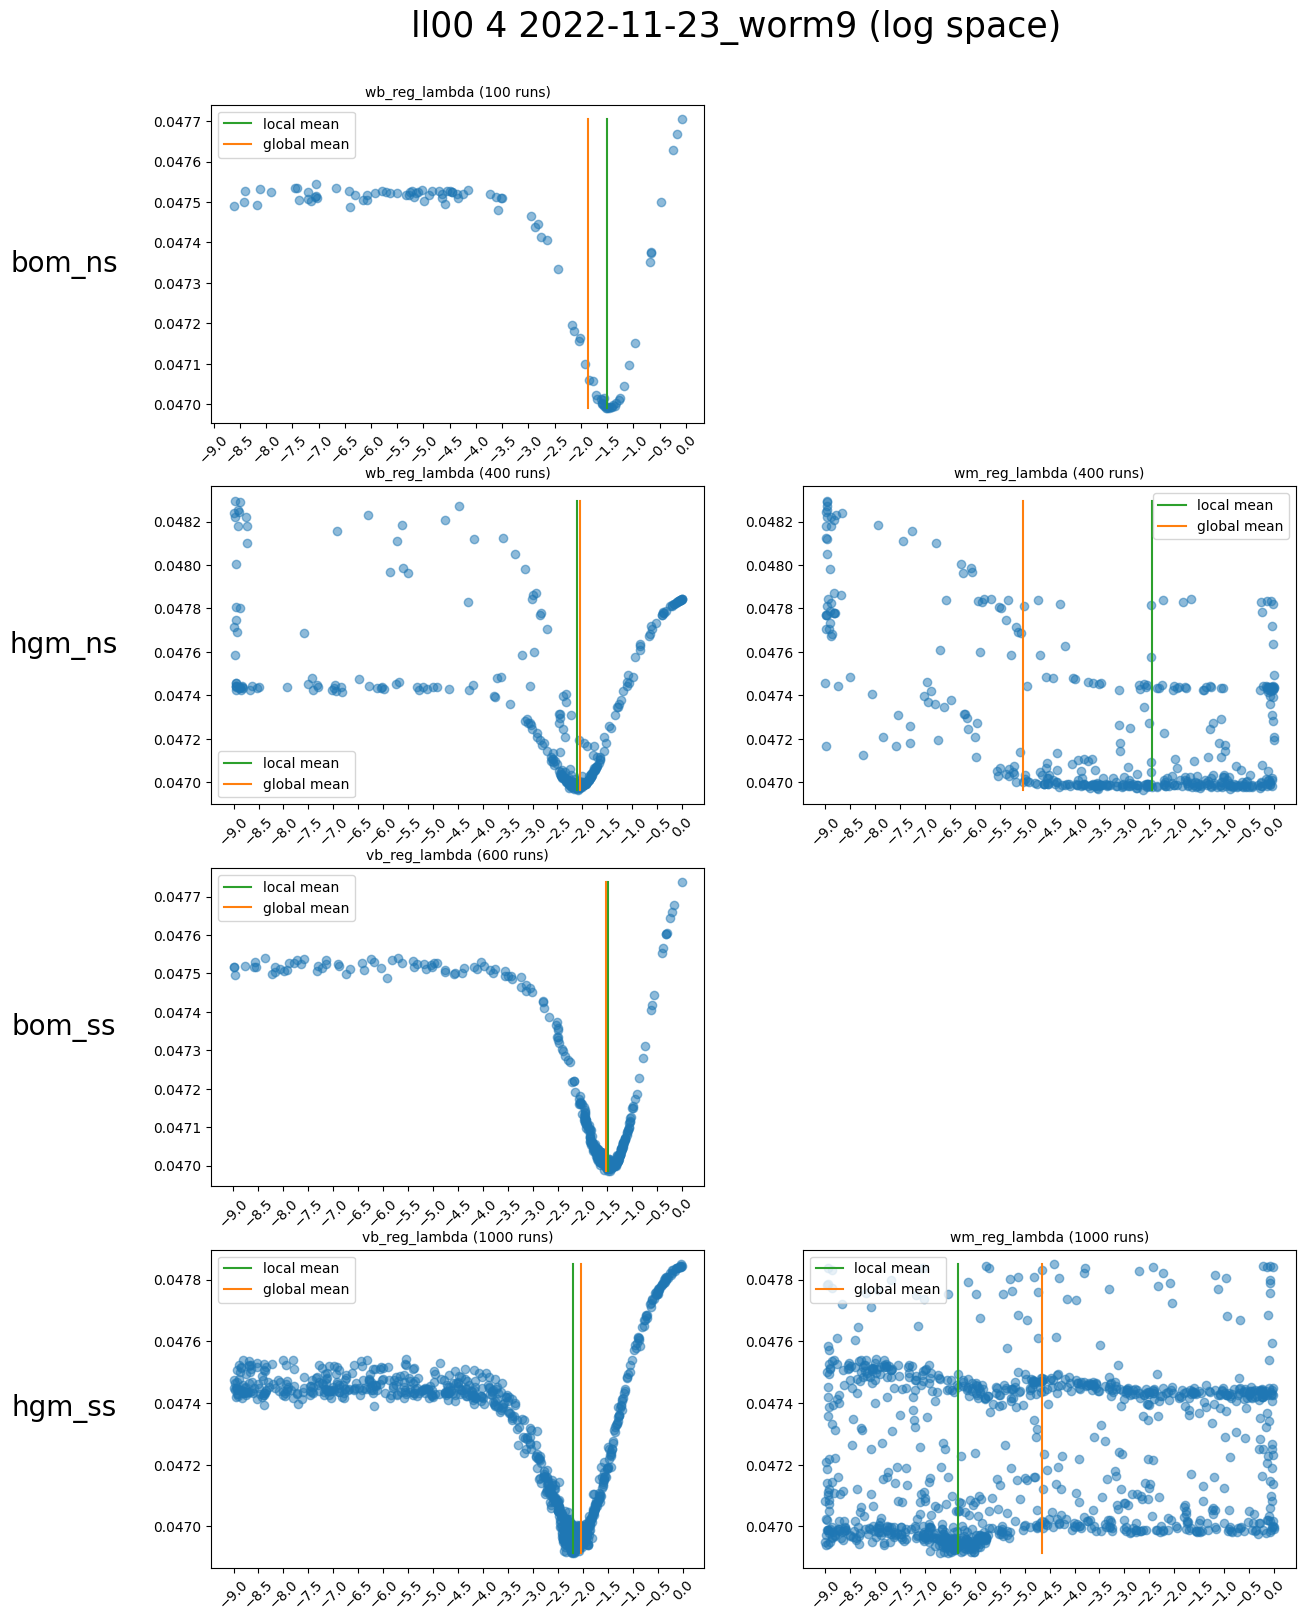

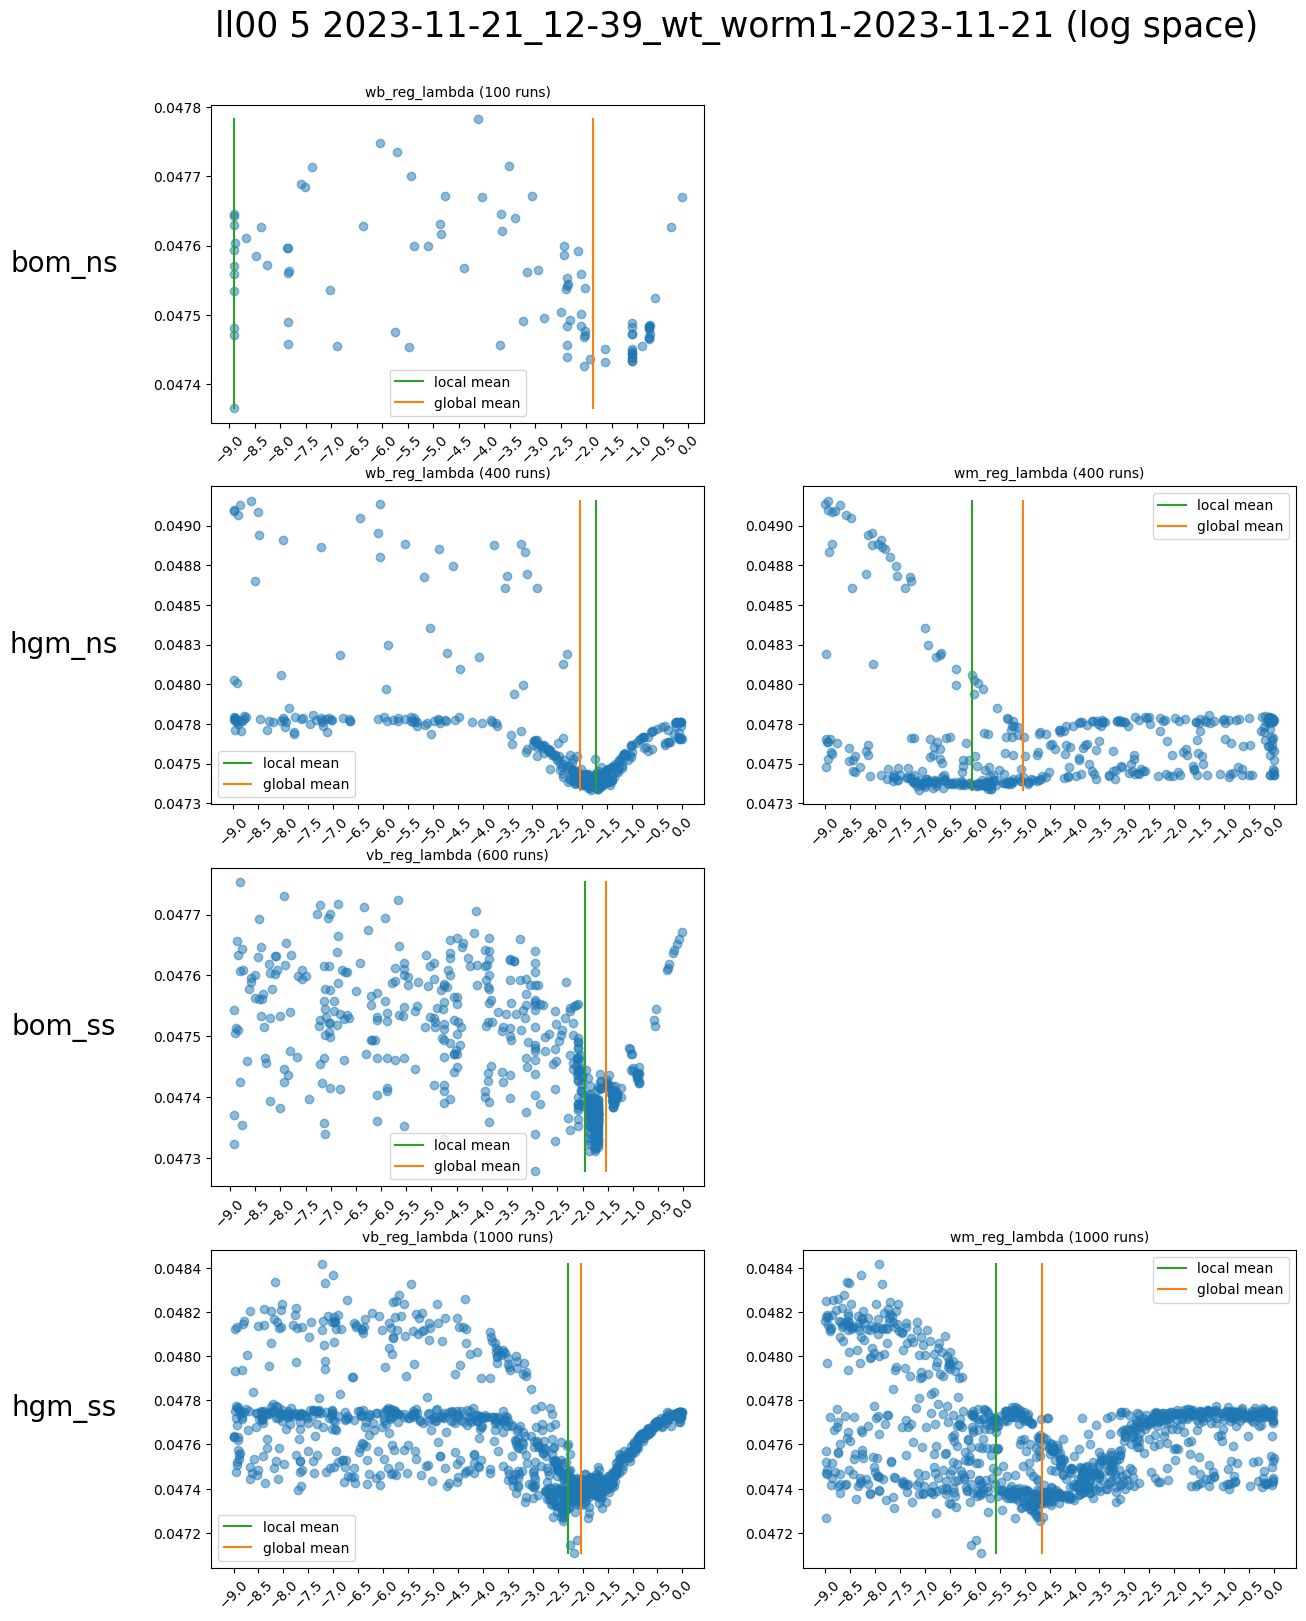

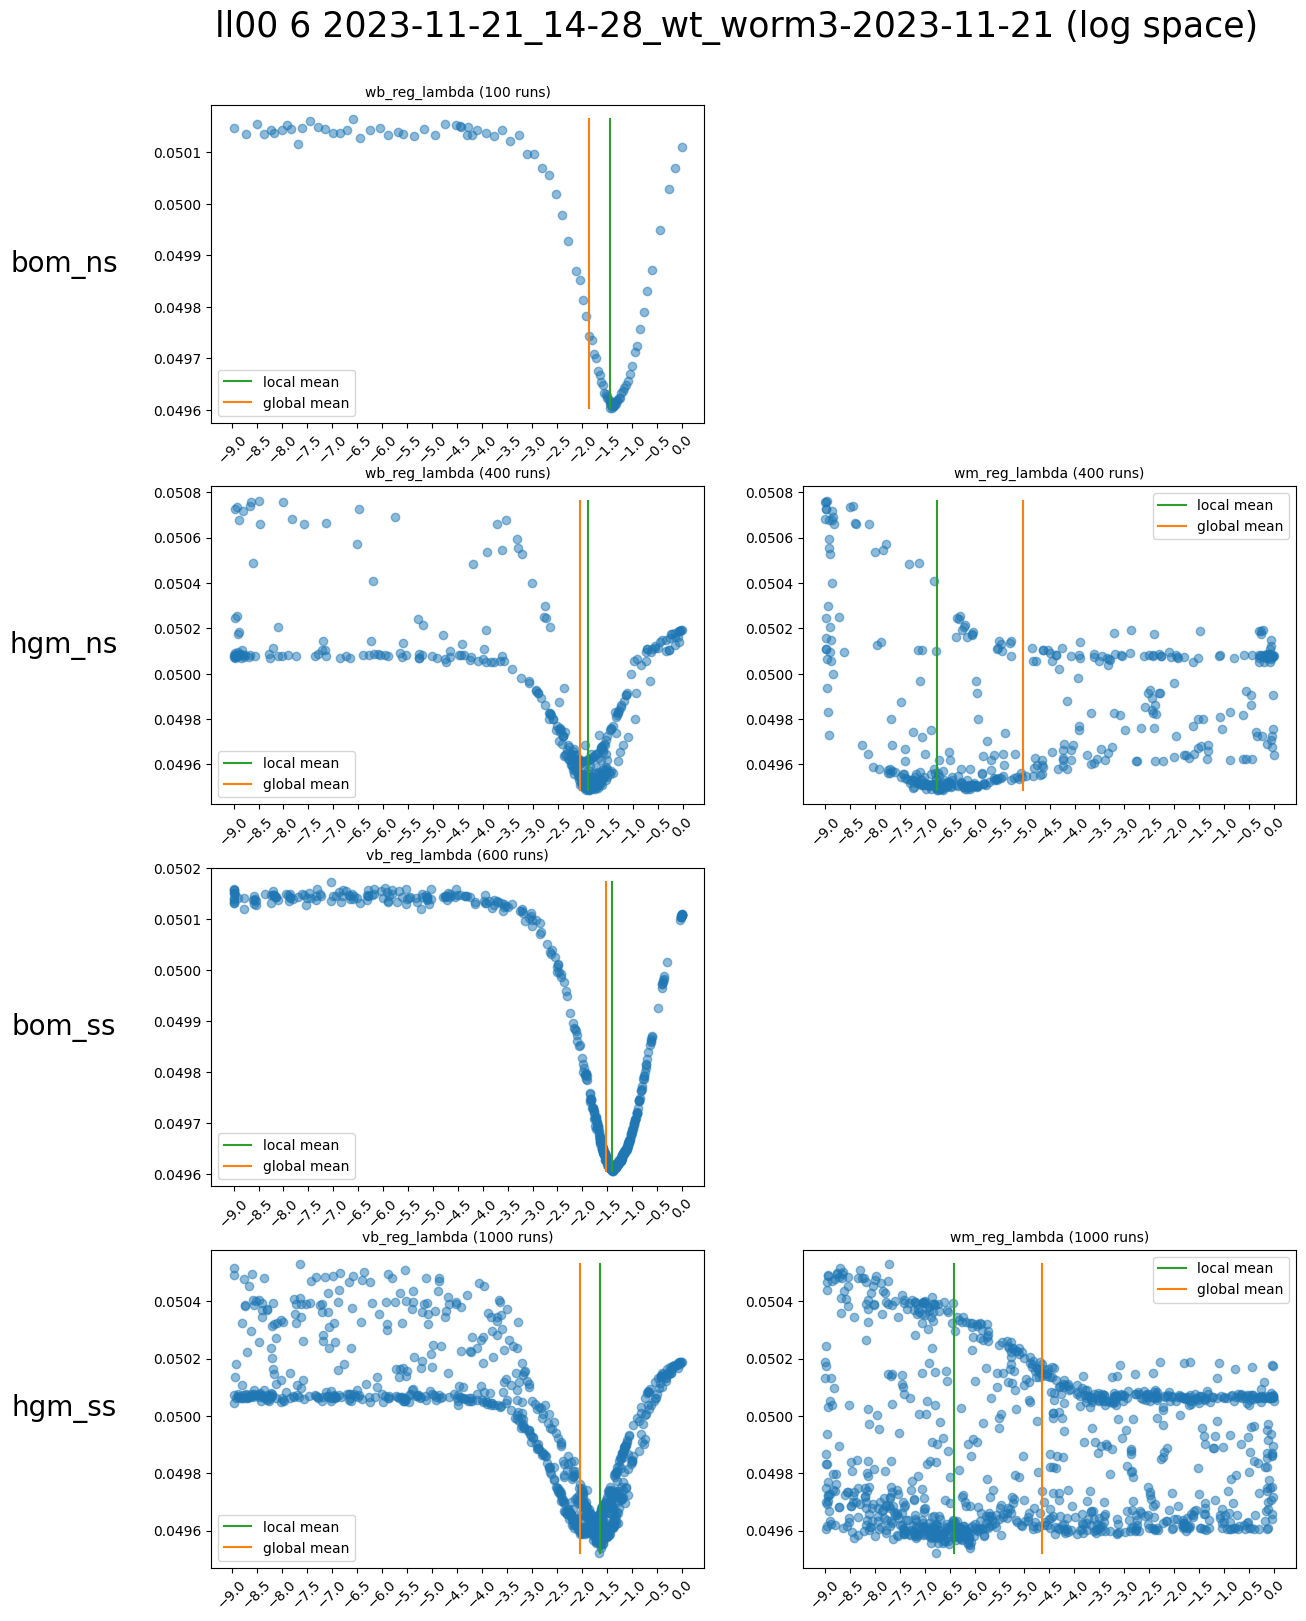

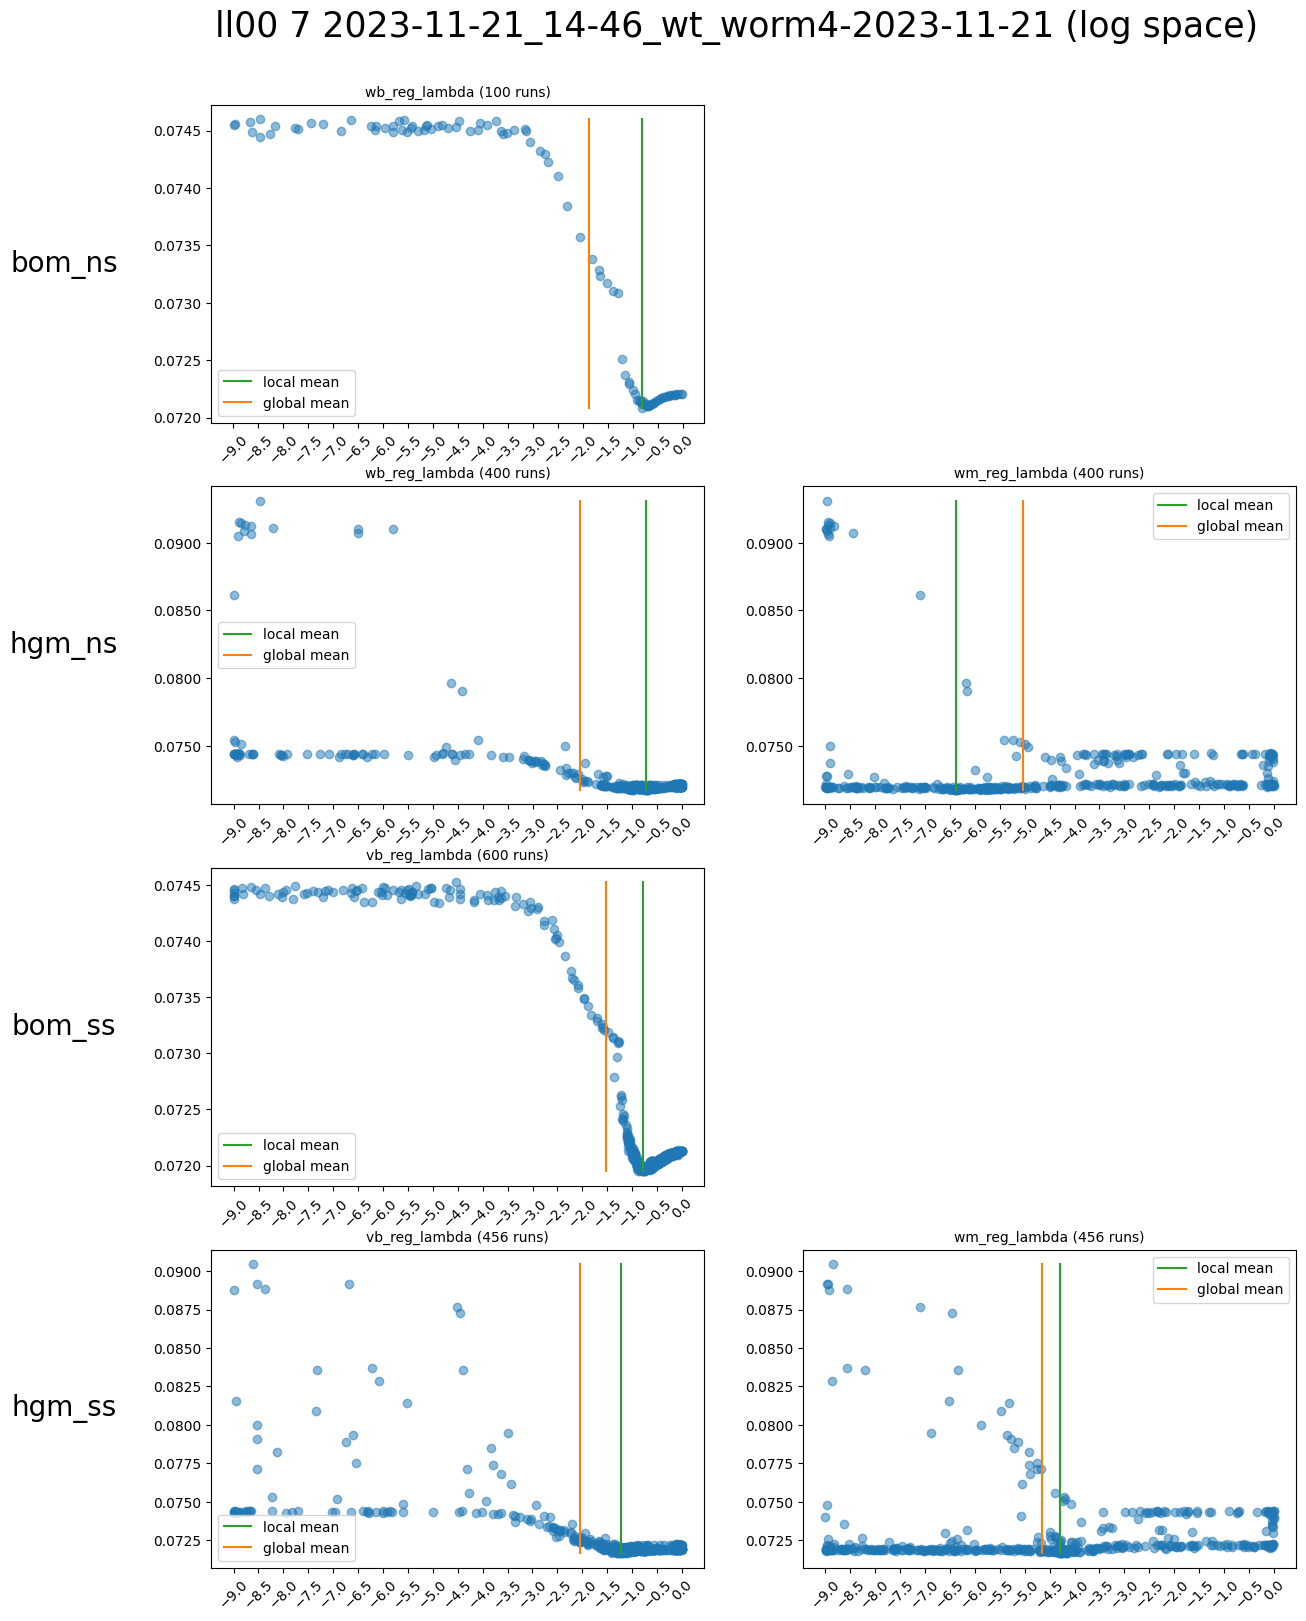

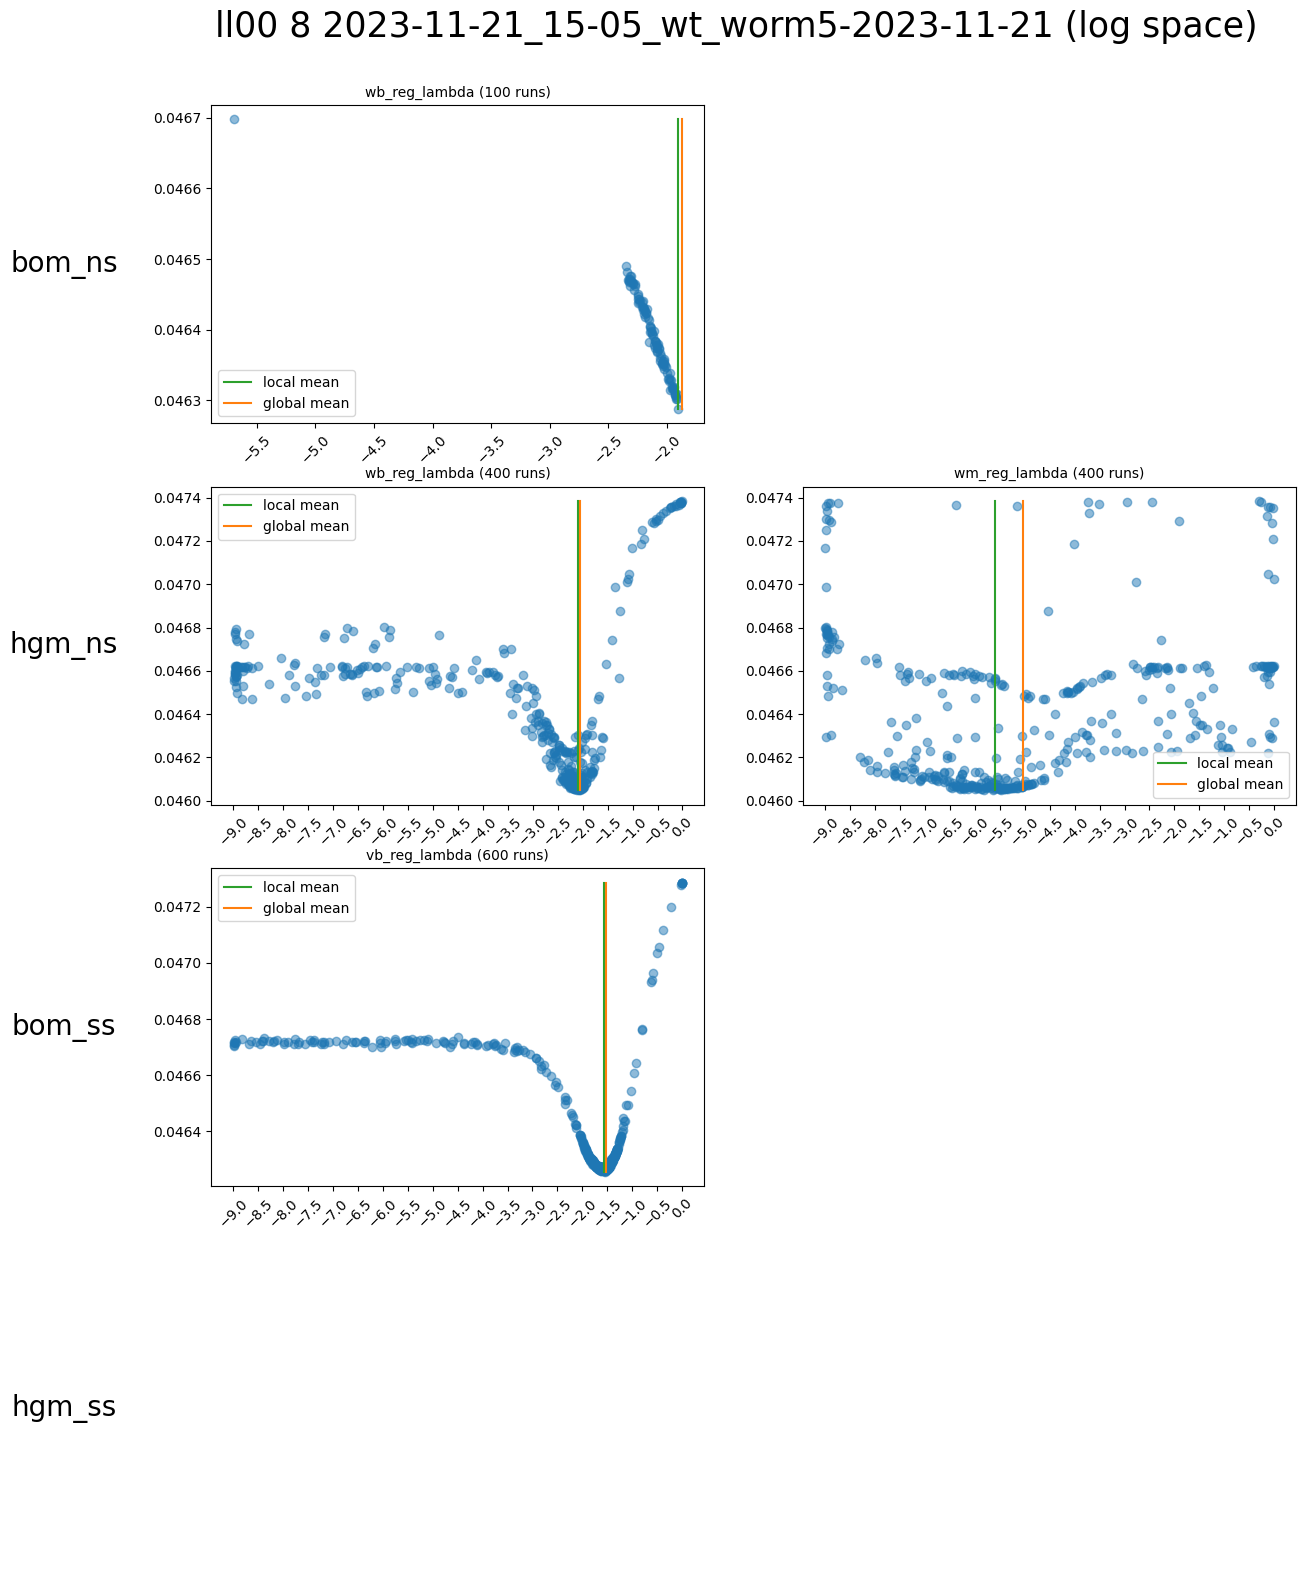

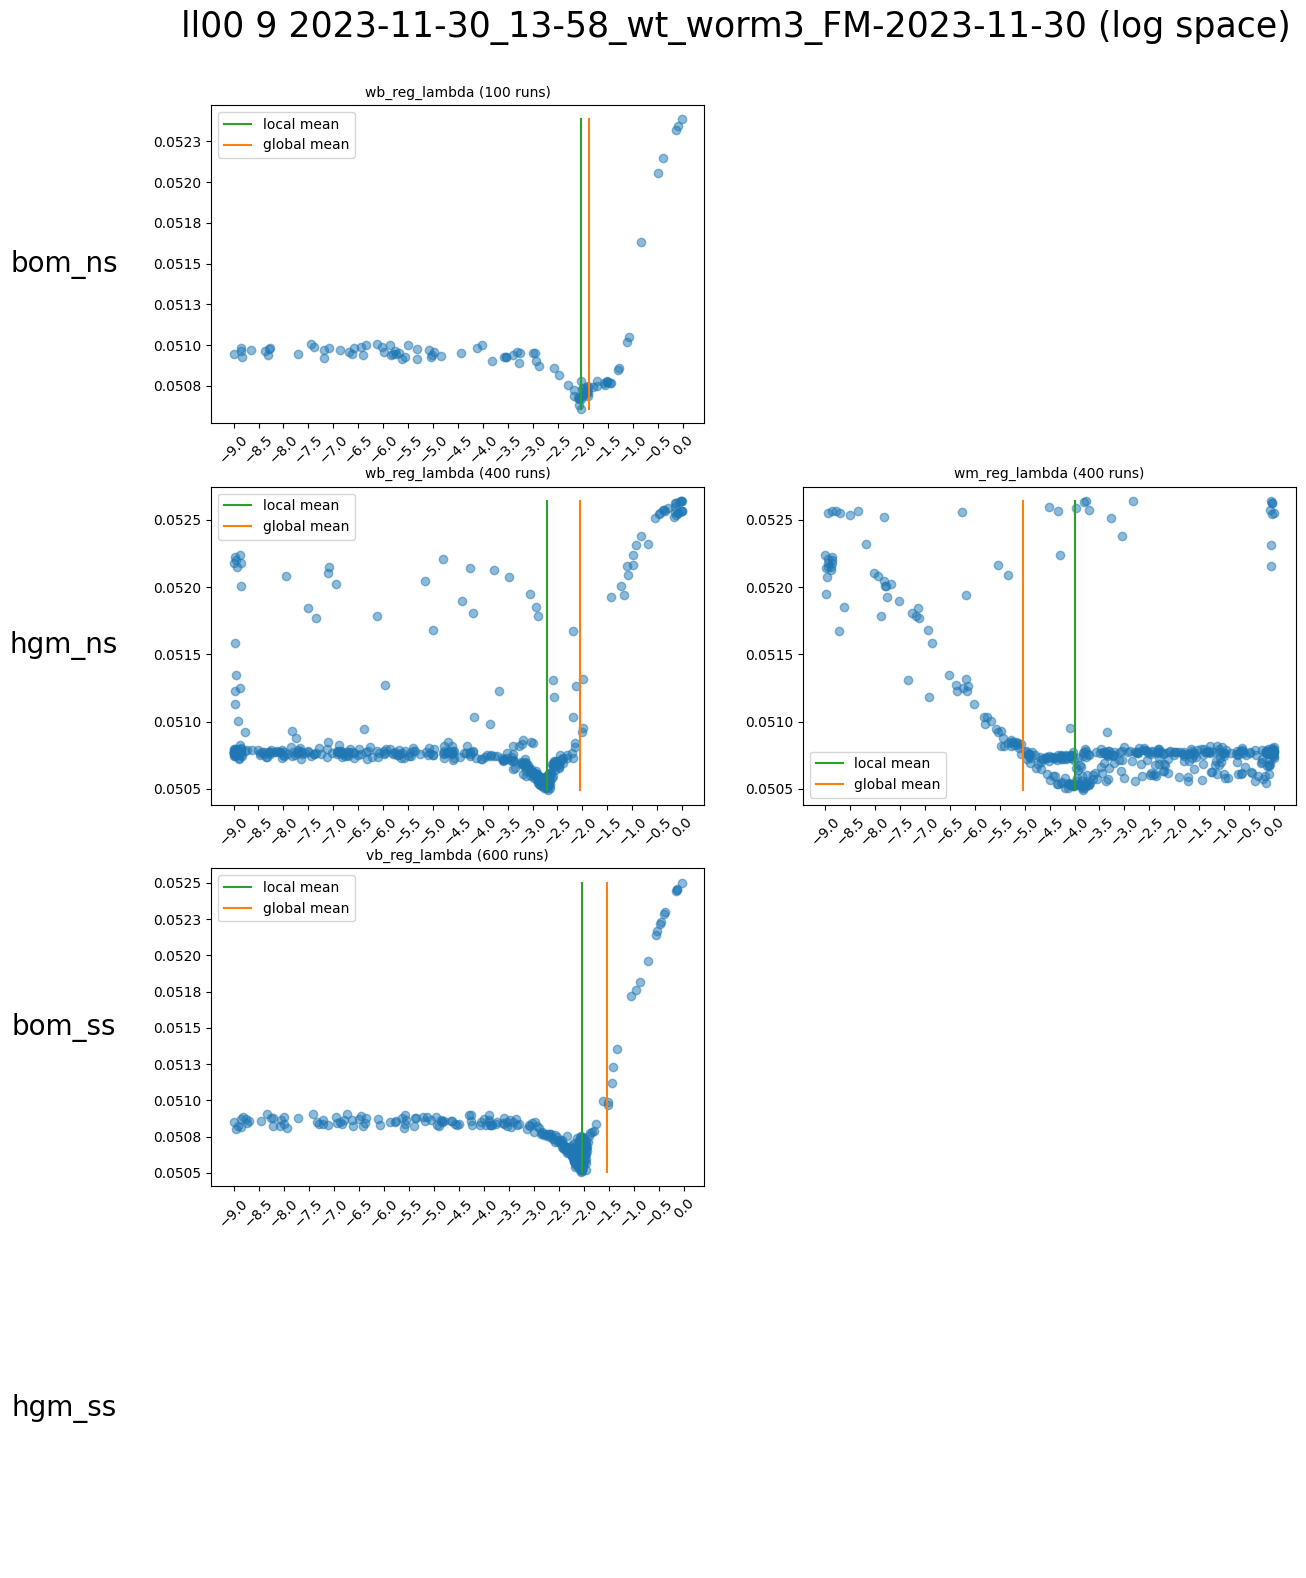

In [8]:
save = False
plot_utils.plot_hyperparams(hyperparams, None,
							ll='ll00', histograms=False, space='logarithmic',
							save_dirpath='../../out/plots/hyperparameters' if save else None)

In [10]:
# with open('../src/hyperparams.pkl', 'wb') as file:
#     pickle.dump(hyperparams, file)